Module 0 setup complete.
Loaded raw dataset: (319795, 18)

Raw column audit preview:
            column    dtype  missing_n  missing_pct  n_unique
0     HeartDisease   object          0          0.0         2
1              BMI  float64          0          0.0      3604
2          Smoking   object          0          0.0         2
3  AlcoholDrinking   object          0          0.0         2
4           Stroke   object          0          0.0         2
5   PhysicalHealth  float64          0          0.0        31
6     MentalHealth  float64          0          0.0        31
7      DiffWalking   object          0          0.0         2
8              Sex   object          0          0.0         2
9      AgeCategory   object          0          0.0        13

Locked feature schema:
             feature       group
0                BMI  continuous
1     PhysicalHealth  continuous
2       MentalHealth  continuous
3          SleepTime  continuous
4        AgeCategory     ordinal
5          

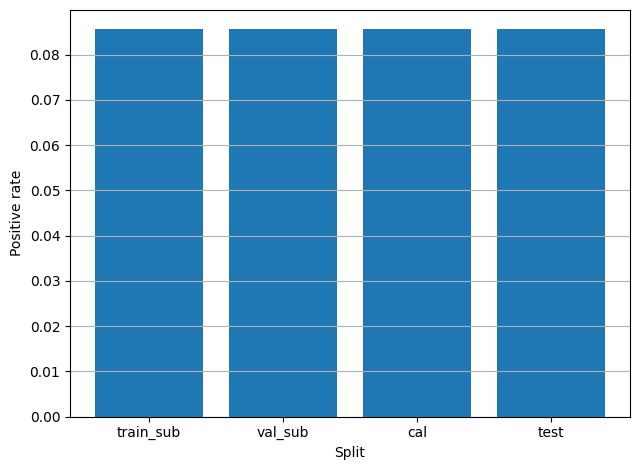


Module 0 complete.
Saved:
- dataset audit
- locked split artifacts
- locked feature schema
- ML preprocessing helpers
- untouched test split

[Module 1] Fitting LogReg ...
LogReg | VAL PR_AUC=0.342172 | CAL PR_AUC=0.347615

[Module 1] Fitting LogReg_balanced ...
LogReg_balanced | VAL PR_AUC=0.342142 | CAL PR_AUC=0.347230

[Module 1] Fitting RandomForest ...
RandomForest | VAL PR_AUC=0.294662 | CAL PR_AUC=0.302153

[Module 1] Fitting ExtraTrees ...
ExtraTrees | VAL PR_AUC=0.302129 | CAL PR_AUC=0.312511

Module 1 validation results:
             model    PR_AUC   ROC_AUC     Brier       NLL       ECE  \
0           LogReg  0.342172  0.842063  0.065967  0.227144  0.009493   
1  LogReg_balanced  0.342142  0.842181  0.166694  0.502855  0.268527   
2       ExtraTrees  0.302129  0.826696  0.117652  0.366923  0.176584   
3     RandomForest  0.294662  0.825656  0.084190  0.277584  0.089173   

        MCE    p_mean  pos_rate      N  ...  Rec@bestF1  F1@bestF1  \
0  0.184076  0.085647  0.085589

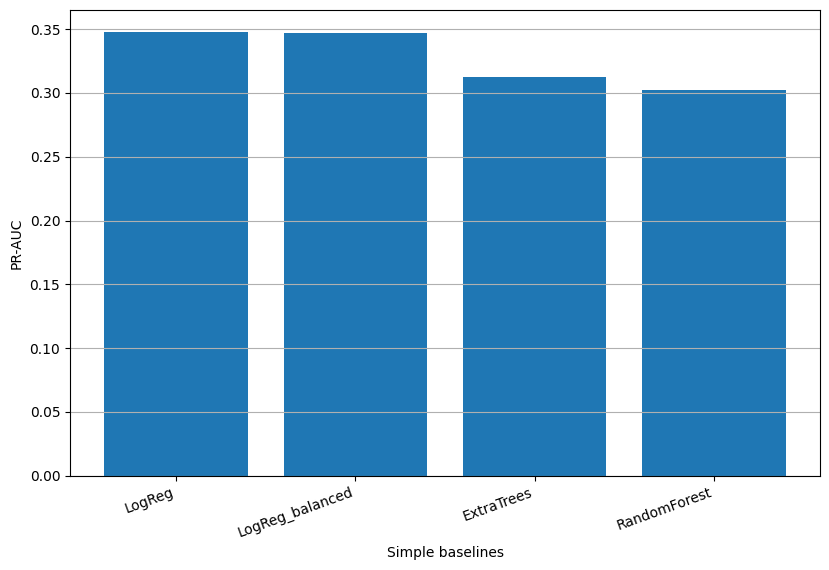

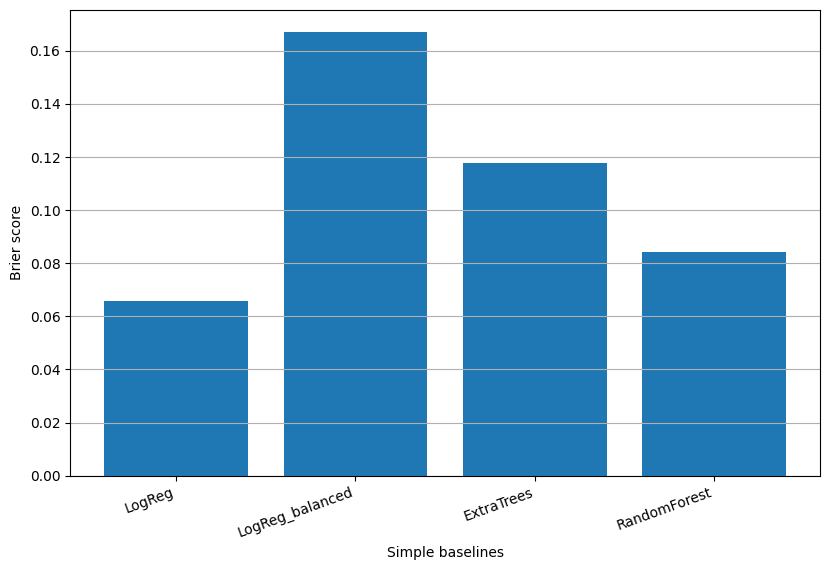


Module 1 complete.
Saved:
- validation and calibration comparison tables
- prediction bundles for val/cal
- compact selection summary
- baseline comparison figures

Note: test split remains untouched.


In [1]:
# ============================================================
# Module 0 — Dataset audit, locked protocol, and preprocessing
# Dataset:
#   heart_2020_cleaned.csv
#
# Locked protocol:
#   20% test (never touched during model selection)
#   remaining 80% -> 70% development + 10% calibration
#   inside development:
#       train_sub = 56% of full data
#       val_sub   = 14% of full data
#
# Purpose:
#   1) load and audit dataset
#   2) define leakage-safer split protocol
#   3) lock feature schema
#   4) build preprocessing helpers for:
#        - simple / tree baselines
#        - later deep models
#   5) save audit and split artifacts
#
# Outputs:
#   - dataset audit tables
#   - split summary tables
#   - locked feature schema
#   - preprocessing helpers
#   - split csv files
# ============================================================

# -------------------------
# Imports
# -------------------------
import os
import gc
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

# -------------------------
# Reproducibility
# -------------------------
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(SEED)

# -------------------------
# Paths
# -------------------------
ROOT_DIR = Path("/kaggle/working")
OUT_DIR = ROOT_DIR / "outputs_heart2020_exp"
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
PRED_DIR = OUT_DIR / "predictions"
SPLIT_DIR = OUT_DIR / "splits"
MOD_DIR = OUT_DIR / "models"

for d in [OUT_DIR, FIG_DIR, TAB_DIR, PRED_DIR, SPLIT_DIR, MOD_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------
# Config
# -------------------------
DATA_PATH = "/kaggle/input/datasets/kamilpytlak/personal-key-indicators-of-heart-disease/2020/heart_2020_cleaned.csv"
TARGET = "HeartDisease"

TEST_RATIO = 0.20          # fully untouched final test
CAL_RATIO = 0.10           # held-out calibration / model selection split
DEV_RATIO = 0.70           # development split (train_sub + val_sub)

# within development portion only
VAL_WITHIN_DEV = 0.20      # 20% of development => 14% of full data
TRAIN_WITHIN_DEV = 0.80    # 80% of development => 56% of full data

assert abs(TEST_RATIO + CAL_RATIO + DEV_RATIO - 1.0) < 1e-8

print("Module 0 setup complete.")

# ============================================================
# 0.1 Utilities
# ============================================================

def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0

    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        if i < n_bins - 1:
            mask = (p >= lo) & (p < hi)
        else:
            mask = (p >= lo) & (p <= hi)

        if mask.sum() == 0:
            continue

        acc = y_true[mask].mean()
        conf = p[mask].mean()
        err = abs(acc - conf)

        ece += (mask.sum() / len(p)) * err
        mce = max(mce, err)

    return float(ece), float(mce)

def find_best_f1_threshold(y_true, p):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    precisions, recalls, thresholds = precision_recall_curve(y_true, p)
    f1_vals = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    idx = int(np.nanargmax(f1_vals))
    return 0.5 if len(thresholds) == 0 else float(thresholds[max(idx - 1, 0)])

def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    pr_auc = average_precision_score(y_true, p)
    roc_auc = roc_auc_score(y_true, p)
    brier = brier_score_loss(y_true, p)
    nll = log_loss(y_true, p)
    ece, mce = expected_calibration_error(y_true, p, n_bins=15)

    thr = find_best_f1_threshold(y_true, p)
    pred = (p >= thr).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    bal_acc = balanced_accuracy_score(y_true, pred)
    mcc = matthews_corrcoef(y_true, pred) if len(np.unique(pred)) > 1 else 0.0

    return {
        "model": name,
        "PR_AUC": float(pr_auc),
        "ROC_AUC": float(roc_auc),
        "Brier": float(brier),
        "NLL": float(nll),
        "ECE": float(ece),
        "MCE": float(mce),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y_true)),
        "N": int(len(y_true)),
        "thr_bestF1": float(thr),
        "Prec@bestF1": float(precision_score(y_true, pred, zero_division=0)),
        "Rec@bestF1": float(recall_score(y_true, pred, zero_division=0)),
        "F1@bestF1": float(f1_score(y_true, pred, zero_division=0)),
        "Acc@bestF1": float(accuracy_score(y_true, pred)),
        "BalAcc@bestF1": float(bal_acc),
        "MCC@bestF1": float(mcc),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }

def save_figure_multi(path_base, dpi=220):
    plt.tight_layout()
    plt.savefig(f"{path_base}.png", dpi=dpi, bbox_inches="tight")
    plt.savefig(f"{path_base}.pdf", dpi=dpi, bbox_inches="tight")

# ============================================================
# 0.2 Load raw dataset
# ============================================================

df_raw = pd.read_csv(DATA_PATH)
print("Loaded raw dataset:", df_raw.shape)

if TARGET not in df_raw.columns:
    raise ValueError(f"TARGET='{TARGET}' not found in dataset columns.")

raw_cols_df = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": [str(df_raw[c].dtype) for c in df_raw.columns],
    "missing_n": [int(df_raw[c].isna().sum()) for c in df_raw.columns],
    "missing_pct": [float(df_raw[c].isna().mean()) for c in df_raw.columns],
    "n_unique": [int(df_raw[c].nunique(dropna=False)) for c in df_raw.columns],
})
raw_cols_df.to_csv(TAB_DIR / "module0_raw_column_audit.csv", index=False)

print("\nRaw column audit preview:")
print(raw_cols_df.head(10))

# ============================================================
# 0.3 Schema-aware mapping
# Notes:
#   - Race is treated as nominal, not ordinal.
#   - Later ML/tree matrices will one-hot encode Race.
#   - Deep models later may use a different representation.
# ============================================================

bin_map = {"Yes": 1, "No": 0}
sex_map = {"Male": 1, "Female": 0}
gen_map = {"Excellent": 1, "Very good": 2, "Good": 3, "Fair": 4, "Poor": 5}
age_map = {
    "18-24": 1, "25-29": 2, "30-34": 3, "35-39": 4, "40-44": 5,
    "45-49": 6, "50-54": 7, "55-59": 8, "60-64": 9, "65-69": 10,
    "70-74": 11, "75-79": 12, "80 or older": 13
}
diabetes_map = {
    "No": 0,
    "No, borderline diabetes": 1,
    "Yes (during pregnancy)": 1,
    "Yes": 2
}

# keep race as string nominal category
allowed_race_values = [
    "White",
    "Black",
    "Asian",
    "American Indian/Alaskan Native",
    "Other",
    "Hispanic",
]

# target
y_all = (df_raw[TARGET] == "Yes").astype(int).values

# feature frame
X_all = pd.DataFrame()
X_all["BMI"] = pd.to_numeric(df_raw["BMI"], errors="coerce")
X_all["Smoking"] = df_raw["Smoking"].map(bin_map)
X_all["AlcoholDrinking"] = df_raw["AlcoholDrinking"].map(bin_map)
X_all["Stroke"] = df_raw["Stroke"].map(bin_map)
X_all["PhysicalHealth"] = pd.to_numeric(df_raw["PhysicalHealth"], errors="coerce")
X_all["MentalHealth"] = pd.to_numeric(df_raw["MentalHealth"], errors="coerce")
X_all["DiffWalking"] = df_raw["DiffWalking"].map(bin_map)
X_all["Sex"] = df_raw["Sex"].map(sex_map)
X_all["AgeCategory"] = df_raw["AgeCategory"].map(age_map)
X_all["Race"] = df_raw["Race"].where(df_raw["Race"].isin(allowed_race_values), "Other")
X_all["Diabetic"] = df_raw["Diabetic"].map(diabetes_map).fillna(0)
X_all["PhysicalActivity"] = df_raw["PhysicalActivity"].map(bin_map)
X_all["GenHealth"] = df_raw["GenHealth"].map(gen_map)
X_all["SleepTime"] = pd.to_numeric(df_raw["SleepTime"], errors="coerce")
X_all["Asthma"] = df_raw["Asthma"].map(bin_map)
X_all["KidneyDisease"] = df_raw["KidneyDisease"].map(bin_map)
X_all["SkinCancer"] = df_raw["SkinCancer"].map(bin_map)

# fill missing
for c in X_all.columns:
    if c == "Race":
        X_all[c] = X_all[c].fillna("Other")
    else:
        X_all[c] = pd.to_numeric(X_all[c], errors="coerce")
        X_all[c] = X_all[c].replace([np.inf, -np.inf], np.nan)
        X_all[c] = X_all[c].fillna(X_all[c].median())

# locked schema
CONT_COLS = ["BMI", "PhysicalHealth", "MentalHealth", "SleepTime"]
ORDINAL_COLS = ["AgeCategory", "GenHealth", "Diabetic"]
NOMINAL_COLS = ["Race"]
BINARY_COLS = [
    "Smoking", "AlcoholDrinking", "Stroke", "DiffWalking", "Sex",
    "PhysicalActivity", "Asthma", "KidneyDisease", "SkinCancer"
]

BASE_FEATURES = CONT_COLS + ORDINAL_COLS + NOMINAL_COLS + BINARY_COLS

schema_df = pd.DataFrame([
    {"feature": c, "group": "continuous"} for c in CONT_COLS
] + [
    {"feature": c, "group": "ordinal"} for c in ORDINAL_COLS
] + [
    {"feature": c, "group": "nominal"} for c in NOMINAL_COLS
] + [
    {"feature": c, "group": "binary"} for c in BINARY_COLS
])

schema_df.to_csv(TAB_DIR / "module0_locked_feature_schema.csv", index=False)

print("\nLocked feature schema:")
print(schema_df)

# ============================================================
# 0.4 Dataset audit after mapping
# ============================================================

mapped_audit_rows = []
for c in X_all.columns:
    s = X_all[c]
    mapped_audit_rows.append({
        "feature": c,
        "dtype": str(s.dtype),
        "missing_n": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean()),
        "n_unique": int(s.nunique(dropna=False)),
        "min": None if s.dtype == "object" else float(np.min(s)),
        "max": None if s.dtype == "object" else float(np.max(s)),
        "mean": None if s.dtype == "object" else float(np.mean(s)),
        "std": None if s.dtype == "object" else float(np.std(s)),
    })

mapped_audit_df = pd.DataFrame(mapped_audit_rows)
mapped_audit_df.to_csv(TAB_DIR / "module0_mapped_feature_audit.csv", index=False)

class_balance_df = pd.DataFrame([{
    "dataset": "heart_2020_cleaned.csv",
    "N": int(len(y_all)),
    "positive_n": int(y_all.sum()),
    "negative_n": int((y_all == 0).sum()),
    "positive_rate": float(y_all.mean()),
}])
class_balance_df.to_csv(TAB_DIR / "module0_class_balance.csv", index=False)

print("\nClass balance:")
print(class_balance_df)

# ============================================================
# 0.5 Locked split protocol
# Full data:
#   20% test
# Remaining 80%:
#   70% dev
#   10% cal
# Within dev:
#   80% train_sub
#   20% val_sub
# ============================================================

# Step 1: full -> temp(80) + test(20)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_all, y_all,
    test_size=TEST_RATIO,
    stratify=y_all,
    random_state=SEED
)

# Step 2: temp(80) -> dev(70) + cal(10)
cal_ratio_adjusted = CAL_RATIO / (DEV_RATIO + CAL_RATIO)   # 0.10 / 0.80 = 0.125
X_dev, X_cal, y_dev, y_cal = train_test_split(
    X_temp, y_temp,
    test_size=cal_ratio_adjusted,
    stratify=y_temp,
    random_state=SEED
)

# Step 3: dev(70) -> train_sub(56) + val_sub(14)
X_train_sub, X_val_sub, y_train_sub, y_val_sub = train_test_split(
    X_dev, y_dev,
    test_size=VAL_WITHIN_DEV,
    stratify=y_dev,
    random_state=SEED
)

split_summary_df = pd.DataFrame([
    {"split": "train_sub", "N": len(y_train_sub), "pos_n": int(y_train_sub.sum()), "pos_rate": float(y_train_sub.mean())},
    {"split": "val_sub",   "N": len(y_val_sub),   "pos_n": int(y_val_sub.sum()),   "pos_rate": float(y_val_sub.mean())},
    {"split": "cal",       "N": len(y_cal),       "pos_n": int(y_cal.sum()),       "pos_rate": float(y_cal.mean())},
    {"split": "test",      "N": len(y_test),      "pos_n": int(y_test.sum()),      "pos_rate": float(y_test.mean())},
])

split_summary_df.to_csv(TAB_DIR / "module0_split_summary.csv", index=False)

print("\nLocked split summary:")
print(split_summary_df)

# save split csvs
train_sub_df = X_train_sub.copy()
train_sub_df[TARGET] = y_train_sub.astype(int)
train_sub_df.to_csv(SPLIT_DIR / "train_sub.csv", index=False)

val_sub_df = X_val_sub.copy()
val_sub_df[TARGET] = y_val_sub.astype(int)
val_sub_df.to_csv(SPLIT_DIR / "val_sub.csv", index=False)

cal_df = X_cal.copy()
cal_df[TARGET] = y_cal.astype(int)
cal_df.to_csv(SPLIT_DIR / "cal.csv", index=False)

test_df = X_test.copy()
test_df[TARGET] = y_test.astype(int)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

# ============================================================
# 0.6 Preprocessing helpers
# ============================================================

def sanitize_tabular_dataframe(X_df):
    X_df = X_df.copy()

    for c in X_df.columns:
        if c == "Race":
            X_df[c] = X_df[c].astype(str).fillna("Other")
        else:
            X_df[c] = pd.to_numeric(X_df[c], errors="coerce")
            X_df[c] = X_df[c].replace([np.inf, -np.inf], np.nan)
            X_df[c] = X_df[c].fillna(X_df[c].median())

    return X_df

def fit_ml_preprocessor(X_train_df):
    """
    ML/tree baseline matrix:
      - continuous: numeric as-is
      - ordinal: numeric as-is
      - binary: numeric as-is
      - nominal Race: one-hot
    """
    X_train_df = sanitize_tabular_dataframe(X_train_df)

    race_levels = sorted(X_train_df["Race"].astype(str).fillna("Other").unique().tolist())

    prep = {
        "base_numeric_cols": CONT_COLS + ORDINAL_COLS + BINARY_COLS,
        "nominal_cols": ["Race"],
        "race_levels": race_levels,
    }
    return prep

def transform_ml_matrix(X_df, prep):
    X_df = sanitize_tabular_dataframe(X_df)

    base = X_df[prep["base_numeric_cols"]].copy()

    # one-hot Race using train-only learned levels
    race = X_df["Race"].astype(str).fillna("Other")
    race_ohe = pd.DataFrame(index=X_df.index)

    for lvl in prep["race_levels"]:
        race_ohe[f"Race__{lvl}"] = (race == lvl).astype(np.float32)

    out = pd.concat([base, race_ohe], axis=1)

    for c in out.columns:
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0.0).astype(np.float32)

    return out

def fit_standard_scaler_on_train(X_train_df):
    """
    For later deep models:
      - continuous standardized
      - ordinal/binary stay numeric
      - nominal Race kept outside this helper for now
    """
    X_train_df = sanitize_tabular_dataframe(X_train_df)

    scaler_info = {
        "continuous_cols": CONT_COLS.copy(),
        "means": {},
        "stds": {},
    }

    for c in CONT_COLS:
        vals = X_train_df[c].astype(np.float32).values
        mean_ = float(vals.mean())
        std_ = float(vals.std())
        if std_ < 1e-8:
            std_ = 1.0
        scaler_info["means"][c] = mean_
        scaler_info["stds"][c] = std_

    return scaler_info

def transform_with_standard_scaler(X_df, scaler_info):
    X_df = sanitize_tabular_dataframe(X_df)

    for c in scaler_info["continuous_cols"]:
        X_df[c] = (X_df[c].astype(np.float32) - scaler_info["means"][c]) / scaler_info["stds"][c]

    return X_df

# fit ML preprocessor once from train_sub only
ml_prep = fit_ml_preprocessor(X_train_sub)

Xtr_ml = transform_ml_matrix(X_train_sub, ml_prep)
Xva_ml = transform_ml_matrix(X_val_sub, ml_prep)
Xcal_ml = transform_ml_matrix(X_cal, ml_prep)
Xte_ml = transform_ml_matrix(X_test, ml_prep)

ML_FEATURES = list(Xtr_ml.columns)

ml_feature_table_df = pd.DataFrame({
    "feature": ML_FEATURES,
    "dtype": [str(Xtr_ml[c].dtype) for c in ML_FEATURES],
})
ml_feature_table_df.to_csv(TAB_DIR / "module0_ml_feature_table.csv", index=False)

# save some compact audit artifacts
pd.DataFrame({"feature": X_all.columns}).to_csv(TAB_DIR / "module0_base_features.csv", index=False)
pd.DataFrame({"ml_feature": ML_FEATURES}).to_csv(TAB_DIR / "module0_ml_features_after_encoding.csv", index=False)

# optional quick class distribution figure
plt.figure(figsize=(6.5, 4.8))
plt.bar(split_summary_df["split"], split_summary_df["pos_rate"])
plt.ylabel("Positive rate")
plt.xlabel("Split")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module0_split_positive_rate")
plt.show()

print("\nModule 0 complete.")
print("Saved:")
print("- dataset audit")
print("- locked split artifacts")
print("- locked feature schema")
print("- ML preprocessing helpers")
print("- untouched test split")

# ============================================================
# Module 1 — Simple baseline benchmarking
# Purpose:
#   Benchmark simple baseline models on the locked protocol
#   without touching the final test set.
#
# Models:
#   - LogisticRegression
#   - LogisticRegression_balanced
#   - RandomForest
#   - ExtraTrees
#
# Training:
#   fit on train_sub only
#
# Evaluation:
#   - val_sub
#   - calibration split
#
# Selection use:
#   use val/cal results for early baseline ranking
#   DO NOT use test here
#
# Outputs:
#   - module1 baseline results on val/cal
#   - model prediction files for val/cal
#   - compact comparison figure
# ============================================================

# -------------------------
# Imports
# -------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "Xtr_ml", "Xva_ml", "Xcal_ml",
    "y_train_sub", "y_val_sub", "y_cal",
    "TAB_DIR", "PRED_DIR", "FIG_DIR",
    "evaluate_probs", "clip_probs"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 1: {missing_vars}")

# -------------------------
# Baseline configs
# -------------------------
baseline_models = {
    "LogReg": LogisticRegression(
        max_iter=4000,
        solver="lbfgs",
        n_jobs=None,
        random_state=SEED,
    ),
    "LogReg_balanced": LogisticRegression(
        max_iter=4000,
        solver="lbfgs",
        class_weight="balanced",
        n_jobs=None,
        random_state=SEED,
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=2,
        n_jobs=-1,
        class_weight="balanced_subsample",
        random_state=SEED,
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=2,
        n_jobs=-1,
        class_weight="balanced",
        random_state=SEED,
    ),
}

# -------------------------
# Run baselines
# -------------------------
module1_val_rows = []
module1_cal_rows = []
pred_store = {
    "y_val": y_val_sub.astype(int),
    "y_cal": y_cal.astype(int),
}

trained_baselines = {}

for model_name, model in baseline_models.items():
    print(f"\n[Module 1] Fitting {model_name} ...")
    model.fit(Xtr_ml, y_train_sub.astype(int))
    trained_baselines[model_name] = model

    p_val = clip_probs(model.predict_proba(Xva_ml)[:, 1])
    p_cal = clip_probs(model.predict_proba(Xcal_ml)[:, 1])

    row_val = evaluate_probs(y_val_sub, p_val, name=model_name)
    row_val["split"] = "val_sub"
    module1_val_rows.append(row_val)

    row_cal = evaluate_probs(y_cal, p_cal, name=model_name)
    row_cal["split"] = "cal"
    module1_cal_rows.append(row_cal)

    pred_store[f"{model_name}__val"] = p_val
    pred_store[f"{model_name}__cal"] = p_cal

    print(f"{model_name} | VAL PR_AUC={row_val['PR_AUC']:.6f} | CAL PR_AUC={row_cal['PR_AUC']:.6f}")

# -------------------------
# Results tables
# -------------------------
module1_val_df = (
    pd.DataFrame(module1_val_rows)
    .sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False])
    .reset_index(drop=True)
)
module1_cal_df = (
    pd.DataFrame(module1_cal_rows)
    .sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False])
    .reset_index(drop=True)
)

module1_all_df = pd.concat([module1_val_df, module1_cal_df], axis=0, ignore_index=True)

module1_val_df.to_csv(TAB_DIR / "module1_simple_baselines_val.csv", index=False)
module1_cal_df.to_csv(TAB_DIR / "module1_simple_baselines_cal.csv", index=False)
module1_all_df.to_csv(TAB_DIR / "module1_simple_baselines_all.csv", index=False)

print("\nModule 1 validation results:")
print(module1_val_df)

print("\nModule 1 calibration results:")
print(module1_cal_df)

# -------------------------
# Save predictions
# -------------------------
module1_val_pred_df = pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_logreg_val": pred_store["LogReg__val"],
    "p_logreg_balanced_val": pred_store["LogReg_balanced__val"],
    "p_randomforest_val": pred_store["RandomForest__val"],
    "p_extratrees_val": pred_store["ExtraTrees__val"],
})

module1_cal_pred_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_logreg_cal": pred_store["LogReg__cal"],
    "p_logreg_balanced_cal": pred_store["LogReg_balanced__cal"],
    "p_randomforest_cal": pred_store["RandomForest__cal"],
    "p_extratrees_cal": pred_store["ExtraTrees__cal"],
})

module1_val_pred_df.to_csv(PRED_DIR / "module1_simple_baseline_predictions_val.csv", index=False)
module1_cal_pred_df.to_csv(PRED_DIR / "module1_simple_baseline_predictions_cal.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module1_simple_baseline_predictions_val_cal.npz",
    y_val=y_val_sub.astype(np.int32),
    y_cal=y_cal.astype(np.int32),
    p_logreg_val=pred_store["LogReg__val"].astype(np.float32),
    p_logreg_balanced_val=pred_store["LogReg_balanced__val"].astype(np.float32),
    p_randomforest_val=pred_store["RandomForest__val"].astype(np.float32),
    p_extratrees_val=pred_store["ExtraTrees__val"].astype(np.float32),
    p_logreg_cal=pred_store["LogReg__cal"].astype(np.float32),
    p_logreg_balanced_cal=pred_store["LogReg_balanced__cal"].astype(np.float32),
    p_randomforest_cal=pred_store["RandomForest__cal"].astype(np.float32),
    p_extratrees_cal=pred_store["ExtraTrees__cal"].astype(np.float32),
)

# -------------------------
# Compact summary table
# Model ranking based on calibration split only
# -------------------------
module1_summary_df = module1_cal_df[[
    "model", "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
    "Prec@bestF1", "Rec@bestF1", "F1@bestF1", "MCC@bestF1"
]].copy()

module1_summary_df = module1_summary_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

module1_summary_df.to_csv(TAB_DIR / "module1_simple_baseline_summary_for_selection.csv", index=False)

# -------------------------
# Figures
# -------------------------
# PR-AUC comparison on calibration split
plt.figure(figsize=(8.4, 5.8))
plt.bar(module1_cal_df["model"], module1_cal_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.xlabel("Simple baselines")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_simple_baselines_cal_prauc")
plt.show()

# Brier comparison on calibration split
plt.figure(figsize=(8.4, 5.8))
plt.bar(module1_cal_df["model"], module1_cal_df["Brier"])
plt.ylabel("Brier score")
plt.xlabel("Simple baselines")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_simple_baselines_cal_brier")
plt.show()

# -------------------------
# Save model metadata
# -------------------------
model_meta_rows = []
for name, model in trained_baselines.items():
    model_meta_rows.append({
        "model": name,
        "class_name": model.__class__.__name__,
        "repr": repr(model),
    })

module1_model_meta_df = pd.DataFrame(model_meta_rows)
module1_model_meta_df.to_csv(TAB_DIR / "module1_simple_baseline_model_metadata.csv", index=False)

print("\nModule 1 complete.")
print("Saved:")
print("- validation and calibration comparison tables")
print("- prediction bundles for val/cal")
print("- compact selection summary")
print("- baseline comparison figures")
print("\nNote: test split remains untouched.")

Training class balance
Positives: 15329
Negatives: 163755
scale_pos_weight: 10.6827

[Module 2] Training LightGBM ...
LightGBM best_iteration: 165

[Module 2] Training XGBoost ...
XGBoost best_iteration: 203

[Module 2] Training CatBoost ...
CatBoost best_iteration: 508

Module 2 validation results:
      model    PR_AUC   ROC_AUC     Brier       NLL       ECE       MCE  \
0  CatBoost  0.349237  0.845578  0.166544  0.490886  0.261769  0.522972   
1   XGBoost  0.346877  0.845609  0.165929  0.488647  0.261768  0.511078   
2  LightGBM  0.346708  0.845180  0.164639  0.482075  0.256528  0.509497   

     p_mean  pos_rate      N  ...  Rec@bestF1  F1@bestF1  Acc@bestF1  \
0  0.347358  0.085589  44772  ...    0.539405   0.400814    0.861967   
1  0.347357  0.085589  44772  ...    0.509134   0.401688    0.870187   
2  0.342117  0.085589  44772  ...    0.512004   0.401843    0.869539   

   BalAcc@bestF1  MCC@bestF1    TP    FP     TN    FN    split  
0       0.715782    0.343111  2067  4415  36

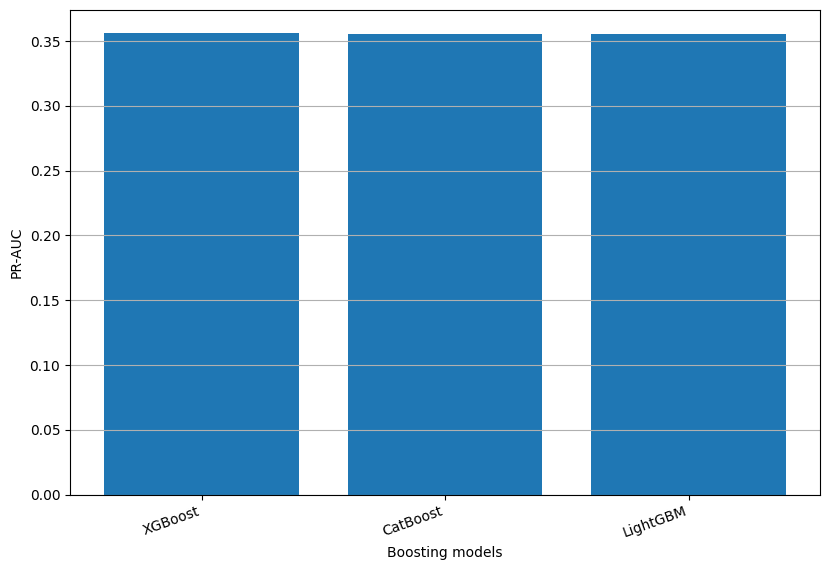

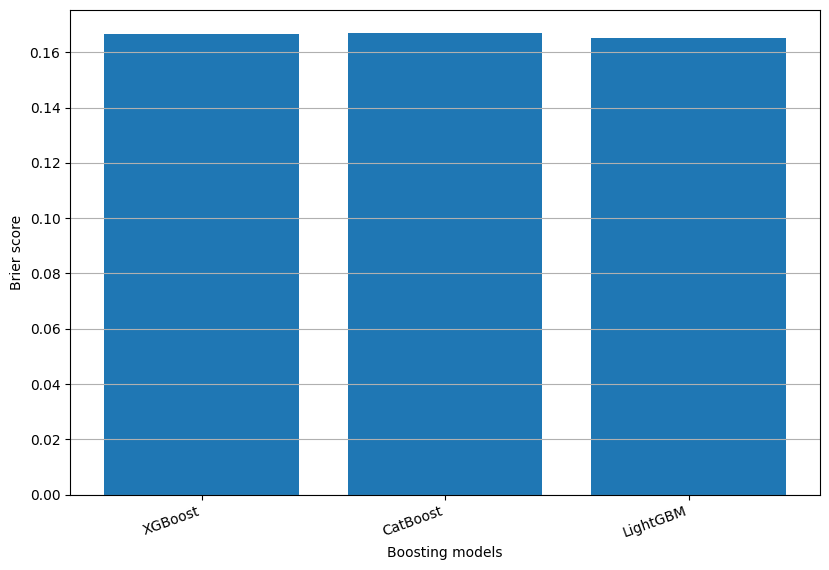

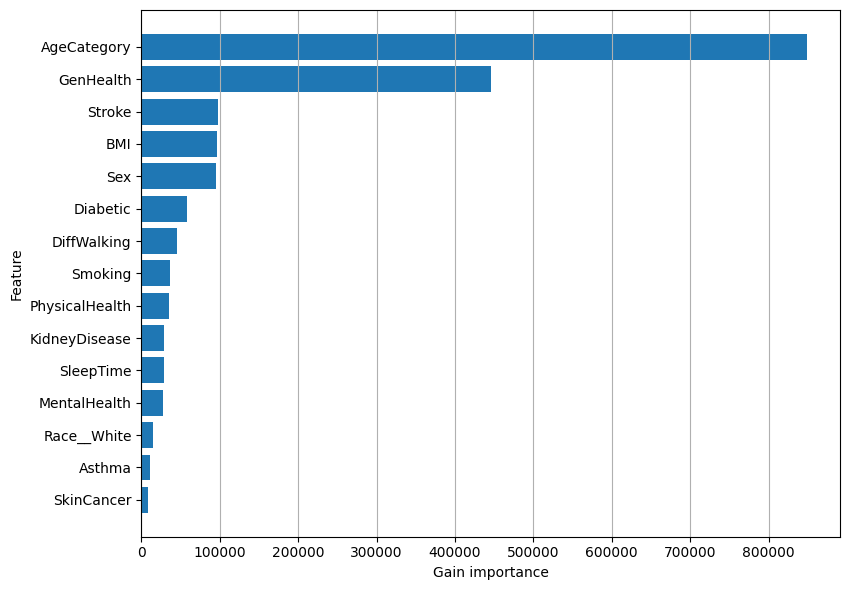

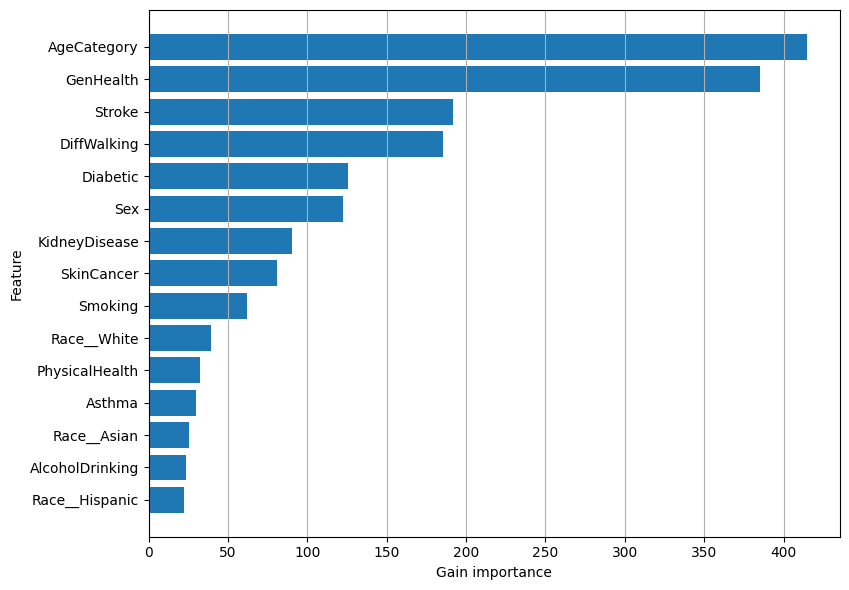

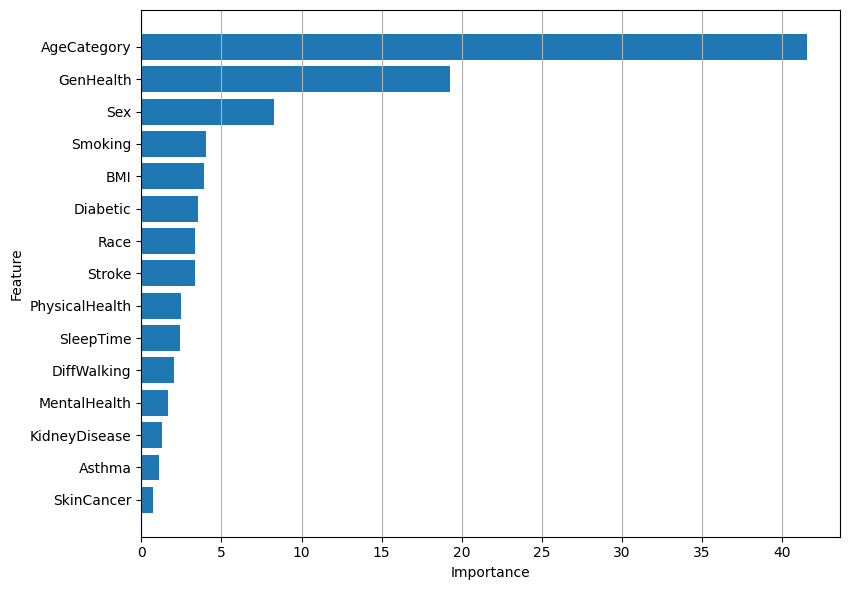


Module 2 complete.
Saved:
- validation and calibration comparison tables
- prediction bundles for val/cal
- boosting feature importance tables
- compact selection summary
- comparison and importance figures

Note: test split remains untouched.


In [2]:
# ============================================================
# Module 2 — Boosting benchmark
# Purpose:
#   Benchmark strong boosting-based tabular classifiers under the
#   locked protocol from Module 0.
#
# Models:
#   - LightGBM
#   - XGBoost
#   - CatBoost
#
# Training:
#   fit on train_sub
#   use val_sub only for early stopping
#
# Evaluation:
#   - val_sub
#   - calibration split
#
# Selection use:
#   use calibration results for candidate ranking
#   DO NOT use test here
#
# Outputs:
#   - module2 boosting results on val/cal
#   - model prediction files for val/cal
#   - feature importance tables
#   - compact comparison figures
# ============================================================

# -------------------------
# Imports
# -------------------------
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_train_sub", "X_val_sub", "X_cal",
    "Xtr_ml", "Xva_ml", "Xcal_ml",
    "y_train_sub", "y_val_sub", "y_cal",
    "CONT_COLS", "ORDINAL_COLS", "BINARY_COLS", "NOMINAL_COLS",
    "ML_FEATURES", "SEED", "TAB_DIR", "PRED_DIR", "FIG_DIR",
    "evaluate_probs", "clip_probs", "save_figure_multi"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 2: {missing_vars}")

# -------------------------
# Class imbalance
# -------------------------
pos = int((y_train_sub == 1).sum())
neg = int((y_train_sub == 0).sum())
scale_pos_weight = neg / max(pos, 1)

print("Training class balance")
print("Positives:", pos)
print("Negatives:", neg)
print("scale_pos_weight:", round(scale_pos_weight, 4))

# ============================================================
# 2.1 LightGBM
# ============================================================

print("\n[Module 2] Training LightGBM ...")

lgb_params = dict(
    objective="binary",
    boosting_type="gbdt",
    learning_rate=0.03,
    num_leaves=64,
    min_data_in_leaf=200,
    feature_fraction=0.85,
    bagging_fraction=0.85,
    bagging_freq=1,
    lambda_l2=10.0,
    scale_pos_weight=scale_pos_weight,
    metric="auc",
    verbosity=-1,
    seed=SEED,
)

dtr_lgb = lgb.Dataset(Xtr_ml, label=y_train_sub.astype(int), feature_name=list(Xtr_ml.columns))
dva_lgb = lgb.Dataset(Xva_ml, label=y_val_sub.astype(int), feature_name=list(Xva_ml.columns))

lgb_model = lgb.train(
    params=lgb_params,
    train_set=dtr_lgb,
    num_boost_round=5000,
    valid_sets=[dva_lgb],
    callbacks=[lgb.early_stopping(200, verbose=False)]
)

lgb_best_iter = lgb_model.best_iteration
print("LightGBM best_iteration:", lgb_best_iter)

p_lgb_val = clip_probs(lgb_model.predict(Xva_ml, num_iteration=lgb_best_iter))
p_lgb_cal = clip_probs(lgb_model.predict(Xcal_ml, num_iteration=lgb_best_iter))

# ============================================================
# 2.2 XGBoost
# ============================================================

print("\n[Module 2] Training XGBoost ...")

dtr_xgb = xgb.DMatrix(Xtr_ml.values, label=y_train_sub.astype(int), feature_names=list(Xtr_ml.columns))
dva_xgb = xgb.DMatrix(Xva_ml.values, label=y_val_sub.astype(int), feature_names=list(Xva_ml.columns))
dcal_xgb = xgb.DMatrix(Xcal_ml.values, feature_names=list(Xtr_ml.columns))

xgb_params = dict(
    objective="binary:logistic",
    eval_metric="auc",
    eta=0.03,
    max_depth=6,
    min_child_weight=30,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=10.0,
    scale_pos_weight=scale_pos_weight,
    seed=SEED,
)

xgb_model = xgb.train(
    params=xgb_params,
    dtrain=dtr_xgb,
    num_boost_round=3000,
    evals=[(dva_xgb, "valid")],
    early_stopping_rounds=200,
    verbose_eval=False
)

xgb_best_iter = xgb_model.best_iteration + 1 if xgb_model.best_iteration is not None else 3000
print("XGBoost best_iteration:", xgb_best_iter)

p_xgb_val = clip_probs(xgb_model.predict(dva_xgb, iteration_range=(0, xgb_best_iter)))
p_xgb_cal = clip_probs(xgb_model.predict(dcal_xgb, iteration_range=(0, xgb_best_iter)))

# ============================================================
# 2.3 CatBoost
# Notes:
#   CatBoost can naturally handle categorical features.
#   Here we use the original split frames with Race as string cat.
#   Other already-mapped columns remain numeric.
# ============================================================

print("\n[Module 2] Training CatBoost ...")

Xtr_cat = X_train_sub.copy()
Xva_cat = X_val_sub.copy()
Xcal_cat = X_cal.copy()

# ensure correct dtypes for CatBoost
for c in CONT_COLS + ORDINAL_COLS + BINARY_COLS:
    Xtr_cat[c] = pd.to_numeric(Xtr_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xva_cat[c] = pd.to_numeric(Xva_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xcal_cat[c] = pd.to_numeric(Xcal_cat[c], errors="coerce").fillna(Xtr_cat[c].median())

for c in NOMINAL_COLS:
    Xtr_cat[c] = Xtr_cat[c].astype(str).fillna("Other")
    Xva_cat[c] = Xva_cat[c].astype(str).fillna("Other")
    Xcal_cat[c] = Xcal_cat[c].astype(str).fillna("Other")

cat_feature_indices = [Xtr_cat.columns.get_loc(c) for c in NOMINAL_COLS]

cat_model = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=10.0,
    iterations=5000,
    auto_class_weights="Balanced",
    random_seed=SEED,
    verbose=False
)

cat_model.fit(
    Xtr_cat,
    y_train_sub.astype(int),
    cat_features=cat_feature_indices,
    eval_set=(Xva_cat, y_val_sub.astype(int)),
    use_best_model=True,
    early_stopping_rounds=200,
    verbose=False
)

cat_best_iter = cat_model.get_best_iteration()
print("CatBoost best_iteration:", cat_best_iter)

p_cat_val = clip_probs(cat_model.predict_proba(Xva_cat)[:, 1])
p_cat_cal = clip_probs(cat_model.predict_proba(Xcal_cat)[:, 1])

# ============================================================
# 2.4 Evaluation tables
# ============================================================

module2_val_rows = []
module2_cal_rows = []

# validation split
module2_val_rows.append(evaluate_probs(y_val_sub, p_lgb_val, name="LightGBM"))
module2_val_rows.append(evaluate_probs(y_val_sub, p_xgb_val, name="XGBoost"))
module2_val_rows.append(evaluate_probs(y_val_sub, p_cat_val, name="CatBoost"))

# calibration split
module2_cal_rows.append(evaluate_probs(y_cal, p_lgb_cal, name="LightGBM"))
module2_cal_rows.append(evaluate_probs(y_cal, p_xgb_cal, name="XGBoost"))
module2_cal_rows.append(evaluate_probs(y_cal, p_cat_cal, name="CatBoost"))

for r in module2_val_rows:
    r["split"] = "val_sub"
for r in module2_cal_rows:
    r["split"] = "cal"

module2_val_df = (
    pd.DataFrame(module2_val_rows)
    .sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False])
    .reset_index(drop=True)
)
module2_cal_df = (
    pd.DataFrame(module2_cal_rows)
    .sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False])
    .reset_index(drop=True)
)
module2_all_df = pd.concat([module2_val_df, module2_cal_df], axis=0, ignore_index=True)

module2_val_df.to_csv(TAB_DIR / "module2_boosting_val.csv", index=False)
module2_cal_df.to_csv(TAB_DIR / "module2_boosting_cal.csv", index=False)
module2_all_df.to_csv(TAB_DIR / "module2_boosting_all.csv", index=False)

print("\nModule 2 validation results:")
print(module2_val_df)

print("\nModule 2 calibration results:")
print(module2_cal_df)

# ============================================================
# 2.5 Save predictions
# ============================================================

module2_pred_df = pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_lgb_val": p_lgb_val,
    "p_xgb_val": p_xgb_val,
    "p_cat_val": p_cat_val,
})

# add cal predictions in separate file for cleaner lengths / semantics
module2_cal_pred_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_lgb_cal": p_lgb_cal,
    "p_xgb_cal": p_xgb_cal,
    "p_cat_cal": p_cat_cal,
})

module2_pred_df.to_csv(PRED_DIR / "module2_boosting_predictions_val.csv", index=False)
module2_cal_pred_df.to_csv(PRED_DIR / "module2_boosting_predictions_cal.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module2_boosting_predictions_val_cal.npz",
    y_val=y_val_sub.astype(np.int32),
    y_cal=y_cal.astype(np.int32),
    p_lgb_val=p_lgb_val.astype(np.float32),
    p_xgb_val=p_xgb_val.astype(np.float32),
    p_cat_val=p_cat_val.astype(np.float32),
    p_lgb_cal=p_lgb_cal.astype(np.float32),
    p_xgb_cal=p_xgb_cal.astype(np.float32),
    p_cat_cal=p_cat_cal.astype(np.float32),
)

# ============================================================
# 2.6 Feature importance tables
# ============================================================

# ---- LightGBM feature importance
lgb_gain = lgb_model.feature_importance(importance_type="gain")
lgb_split = lgb_model.feature_importance(importance_type="split")

lgb_imp_df = pd.DataFrame({
    "feature": Xtr_ml.columns,
    "gain_importance": lgb_gain,
    "split_importance": lgb_split,
}).sort_values("gain_importance", ascending=False).reset_index(drop=True)

lgb_imp_df.to_csv(TAB_DIR / "module2_lightgbm_feature_importance.csv", index=False)

# ---- XGBoost feature importance
xgb_weight_scores = xgb_model.get_score(importance_type="weight")
xgb_gain_scores = xgb_model.get_score(importance_type="gain")

xgb_imp_df = pd.DataFrame({
    "feature": Xtr_ml.columns,
    "weight_importance": [float(xgb_weight_scores.get(f, 0.0)) for f in Xtr_ml.columns],
    "gain_importance": [float(xgb_gain_scores.get(f, 0.0)) for f in Xtr_ml.columns],
}).sort_values("gain_importance", ascending=False).reset_index(drop=True)

xgb_imp_df.to_csv(TAB_DIR / "module2_xgboost_feature_importance.csv", index=False)

# ---- CatBoost feature importance
cat_imp_vals = cat_model.get_feature_importance()
cat_imp_df = pd.DataFrame({
    "feature": Xtr_cat.columns,
    "importance": cat_imp_vals,
}).sort_values("importance", ascending=False).reset_index(drop=True)

cat_imp_df.to_csv(TAB_DIR / "module2_catboost_feature_importance.csv", index=False)

print("\nTop LightGBM features:")
print(lgb_imp_df.head(10))

print("\nTop XGBoost features:")
print(xgb_imp_df.head(10))

print("\nTop CatBoost features:")
print(cat_imp_df.head(10))

# ============================================================
# 2.7 Compact selection summary
# Ranking based on calibration split only
# ============================================================

module2_summary_df = module2_cal_df[[
    "model", "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
    "Prec@bestF1", "Rec@bestF1", "F1@bestF1", "MCC@bestF1"
]].copy()

module2_summary_df = module2_summary_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier"],
    ascending=[False, False, True]
).reset_index(drop=True)

module2_summary_df.to_csv(TAB_DIR / "module2_boosting_summary_for_selection.csv", index=False)

# ============================================================
# 2.8 Figures
# Important figure rule:
#   no titles inside saved images
# ============================================================

# PR-AUC on calibration split
plt.figure(figsize=(8.4, 5.8))
plt.bar(module2_cal_df["model"], module2_cal_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.xlabel("Boosting models")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module2_boosting_cal_prauc")
plt.show()

# Brier on calibration split
plt.figure(figsize=(8.4, 5.8))
plt.bar(module2_cal_df["model"], module2_cal_df["Brier"])
plt.ylabel("Brier score")
plt.xlabel("Boosting models")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module2_boosting_cal_brier")
plt.show()

# Top-15 LightGBM importance
plt.figure(figsize=(8.6, 6.0))
tmp = lgb_imp_df.head(15).iloc[::-1]
plt.barh(tmp["feature"], tmp["gain_importance"])
plt.xlabel("Gain importance")
plt.ylabel("Feature")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module2_lightgbm_top15_gain_importance")
plt.show()

# Top-15 XGBoost importance
plt.figure(figsize=(8.6, 6.0))
tmp = xgb_imp_df.head(15).iloc[::-1]
plt.barh(tmp["feature"], tmp["gain_importance"])
plt.xlabel("Gain importance")
plt.ylabel("Feature")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module2_xgboost_top15_gain_importance")
plt.show()

# Top-15 CatBoost importance
plt.figure(figsize=(8.6, 6.0))
tmp = cat_imp_df.head(15).iloc[::-1]
plt.barh(tmp["feature"], tmp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module2_catboost_top15_importance")
plt.show()

# ============================================================
# 2.9 Model metadata
# ============================================================

module2_model_meta_df = pd.DataFrame([
    {
        "model": "LightGBM",
        "best_iteration": int(lgb_best_iter),
        "params_json": json.dumps(lgb_params),
    },
    {
        "model": "XGBoost",
        "best_iteration": int(xgb_best_iter),
        "params_json": json.dumps(xgb_params),
    },
    {
        "model": "CatBoost",
        "best_iteration": int(cat_best_iter) if cat_best_iter is not None else np.nan,
        "params_json": json.dumps({
            "loss_function": "Logloss",
            "eval_metric": "AUC",
            "learning_rate": 0.03,
            "depth": 6,
            "l2_leaf_reg": 10.0,
            "iterations": 5000,
            "auto_class_weights": "Balanced",
            "random_seed": SEED,
        }),
    },
])

module2_model_meta_df.to_csv(TAB_DIR / "module2_boosting_model_metadata.csv", index=False)

# ============================================================
# 2.10 Export commonly used prediction variables for later modules
# ============================================================

# locked raw boosting predictions on calibration split
p_lgb_cal_raw = p_lgb_cal.copy()
p_xgb_cal_raw = p_xgb_cal.copy()
p_cat_cal_raw = p_cat_cal.copy()

# optional validation copies
p_lgb_val_raw = p_lgb_val.copy()
p_xgb_val_raw = p_xgb_val.copy()
p_cat_val_raw = p_cat_val.copy()

print("\nModule 2 complete.")
print("Saved:")
print("- validation and calibration comparison tables")
print("- prediction bundles for val/cal")
print("- boosting feature importance tables")
print("- compact selection summary")
print("- comparison and importance figures")
print("\nNote: test split remains untouched.")

In [3]:
# ============================================================
# Module 3 — Neural Benchmark
#
# Models
#   - MLP
#   - ResMLP
#   - DeepFM
#   - DeepFM_Robust
#
# Training
#   train_sub
#
# Early stopping
#   val_sub
#
# Evaluation
#   val_sub
#   calibration
#
# Test split remains untouched
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================
# Dataset
# ============================================================

class TabDataset(Dataset):
    
    def __init__(self, X, y):
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_ds = TabDataset(Xtr_ml, y_train_sub)
val_ds   = TabDataset(Xva_ml, y_val_sub)

train_loader = DataLoader(train_ds, batch_size=2048, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=4096, shuffle=False)

# ============================================================
# Training helper
# ============================================================

def train_model(model, epochs=40, lr=1e-3):

    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    
    best_loss = 1e9
    patience = 6
    patience_counter = 0

    for epoch in range(epochs):
        
        model.train()
        
        for X,y in train_loader:
            
            X = X.to(device)
            y = y.to(device)
            
            opt.zero_grad()
            
            p = model(X).squeeze()
            loss = F.binary_cross_entropy_with_logits(p, y)
            
            loss.backward()
            opt.step()

        # validation
        
        model.eval()
        val_losses = []

        with torch.no_grad():
            
            for X,y in val_loader:
                
                X = X.to(device)
                y = y.to(device)
                
                p = model(X).squeeze()
                loss = F.binary_cross_entropy_with_logits(p,y)
                
                val_losses.append(loss.item())
        
        val_loss = np.mean(val_losses)

        if val_loss < best_loss:
            
            best_loss = val_loss
            best_state = model.state_dict()
            patience_counter = 0
            
        else:
            
            patience_counter += 1
            
            if patience_counter >= patience:
                break
    
    model.load_state_dict(best_state)
    return model


# ============================================================
# Prediction helper
# ============================================================

def predict_model(model, X):

    model.eval()
    
    X = torch.tensor(X.values, dtype=torch.float32).to(device)

    with torch.no_grad():
        logits = model(X).squeeze().cpu().numpy()

    return clip_probs(1/(1+np.exp(-logits)))


# ============================================================
# Model definitions
# ============================================================

INPUT_DIM = Xtr_ml.shape[1]

# ------------------------------------------------------------
# 1 MLP
# ------------------------------------------------------------

class MLP(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Linear(INPUT_DIM,256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128,1)
        )
    
    def forward(self,x):
        return self.net(x)


# ------------------------------------------------------------
# 2 ResMLP
# ------------------------------------------------------------

class ResBlock(nn.Module):
    
    def __init__(self,dim):
        super().__init__()
        
        self.fc1 = nn.Linear(dim,dim)
        self.fc2 = nn.Linear(dim,dim)
    
    def forward(self,x):
        
        h = F.relu(self.fc1(x))
        h = self.fc2(h)
        
        return F.relu(x+h)


class ResMLP(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.fc = nn.Linear(INPUT_DIM,128)
        self.block1 = ResBlock(128)
        self.block2 = ResBlock(128)
        self.out = nn.Linear(128,1)
        
    def forward(self,x):
        
        x = F.relu(self.fc(x))
        x = self.block1(x)
        x = self.block2(x)
        
        return self.out(x)


# ------------------------------------------------------------
# 3 DeepFM
# ------------------------------------------------------------

class DeepFM(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.linear = nn.Linear(INPUT_DIM,1)
        
        self.deep = nn.Sequential(
            nn.Linear(INPUT_DIM,256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Linear(128,1)
        )
    
    def forward(self,x):
        
        linear = self.linear(x)
        deep = self.deep(x)
        
        return linear + deep


# ------------------------------------------------------------
# 4 DeepFM Robust
# ------------------------------------------------------------

class DeepFMRobust(DeepFM):
    
    def forward(self,x):
        
        if self.training:
            noise = torch.randn_like(x)*0.02
            x = x + noise
        
        return super().forward(x)


# ============================================================
# Train models
# ============================================================

models = {
    "MLP":MLP(),
    "ResMLP":ResMLP(),
    "DeepFM":DeepFM(),
    "DeepFM_Robust":DeepFMRobust()
}

module3_val_rows = []
module3_cal_rows = []

pred_store_val = {}
pred_store_cal = {}

for name,model in models.items():
    
    print("\nTraining",name)

    model = train_model(model)

    p_val = predict_model(model,Xva_ml)
    p_cal = predict_model(model,Xcal_ml)

    pred_store_val[name] = p_val
    pred_store_cal[name] = p_cal

    module3_val_rows.append(evaluate_probs(y_val_sub,p_val,name=name))
    module3_cal_rows.append(evaluate_probs(y_cal,p_cal,name=name))


# ============================================================
# Results tables
# ============================================================

module3_val_df = pd.DataFrame(module3_val_rows)\
    .sort_values("PR_AUC",ascending=False)

module3_cal_df = pd.DataFrame(module3_cal_rows)\
    .sort_values("PR_AUC",ascending=False)

module3_val_df.to_csv(TAB_DIR/"module3_neural_val.csv",index=False)
module3_cal_df.to_csv(TAB_DIR/"module3_neural_cal.csv",index=False)

print("\nValidation results")
print(module3_val_df)

print("\nCalibration results")
print(module3_cal_df)


# ============================================================
# Save predictions
# ============================================================

val_pred_df = pd.DataFrame({
    
    "y_val":y_val_sub,
    
    **{f"p_{k}_val":v for k,v in pred_store_val.items()}
})

cal_pred_df = pd.DataFrame({
    
    "y_cal":y_cal,
    
    **{f"p_{k}_cal":v for k,v in pred_store_cal.items()}
})

val_pred_df.to_csv(PRED_DIR/"module3_neural_val_predictions.csv",index=False)
cal_pred_df.to_csv(PRED_DIR/"module3_neural_cal_predictions.csv",index=False)


print("\nModule 3 complete")


Training MLP

Training ResMLP

Training DeepFM

Training DeepFM_Robust

Validation results
           model    PR_AUC   ROC_AUC     Brier       NLL       ECE       MCE  \
3  DeepFM_Robust  0.345676  0.844345  0.065568  0.225452  0.008181  0.085064   
0            MLP  0.345078  0.844004  0.065676  0.226385  0.011488  0.061964   
1         ResMLP  0.342901  0.842765  0.065718  0.226119  0.006873  0.151147   
2         DeepFM  0.341315  0.841972  0.066573  0.229919  0.020767  0.110517   

     p_mean  pos_rate      N  ...  Prec@bestF1  Rec@bestF1  F1@bestF1  \
3  0.077517  0.085589  44772  ...     0.317698    0.537317   0.399302   
0  0.074409  0.085589  44772  ...     0.330831    0.506002   0.400083   
1  0.083343  0.085589  44772  ...     0.318961    0.528967   0.397958   
2  0.064823  0.085589  44772  ...     0.307937    0.554802   0.396051   

   Acc@bestF1  BalAcc@bestF1  MCC@bestF1    TP    FP     TN    FN  
3    0.861632       0.714653    0.341337  2059  4422  36518  1773  
0    

Module 4 search budget
LightGBM trials: 6
XGBoost  trials: 6
CatBoost trials: 6
MLP      trials: 5
DeepFM   trials: 5

Module 4A — LightGBM tuning
LGB trial 1/6 | cal PR_AUC=0.355548 | cal ROC_AUC=0.842628
LGB trial 2/6 | cal PR_AUC=0.354711 | cal ROC_AUC=0.842316
LGB trial 3/6 | cal PR_AUC=0.355696 | cal ROC_AUC=0.842471
LGB trial 4/6 | cal PR_AUC=0.354993 | cal ROC_AUC=0.842686
LGB trial 5/6 | cal PR_AUC=0.352333 | cal ROC_AUC=0.841896
LGB trial 6/6 | cal PR_AUC=0.355841 | cal ROC_AUC=0.842963

Module 4B — XGBoost tuning
XGB trial 1/6 | cal PR_AUC=0.356230 | cal ROC_AUC=0.842946
XGB trial 2/6 | cal PR_AUC=0.354961 | cal ROC_AUC=0.843052
XGB trial 3/6 | cal PR_AUC=0.355865 | cal ROC_AUC=0.842886
XGB trial 4/6 | cal PR_AUC=0.355159 | cal ROC_AUC=0.842960
XGB trial 5/6 | cal PR_AUC=0.355884 | cal ROC_AUC=0.843351
XGB trial 6/6 | cal PR_AUC=0.355233 | cal ROC_AUC=0.843374

Module 4C — CatBoost tuning
CAT trial 1/6 | cal PR_AUC=0.355689 | cal ROC_AUC=0.843966
CAT trial 2/6 | cal PR_AUC=0.

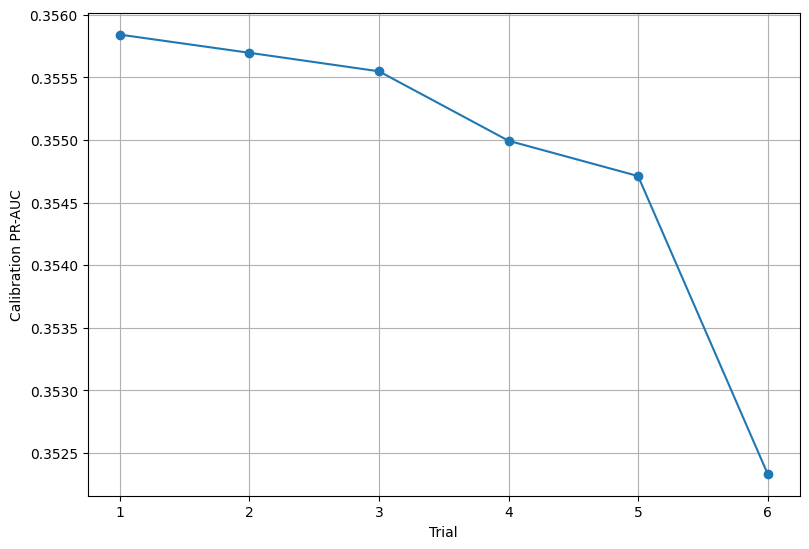

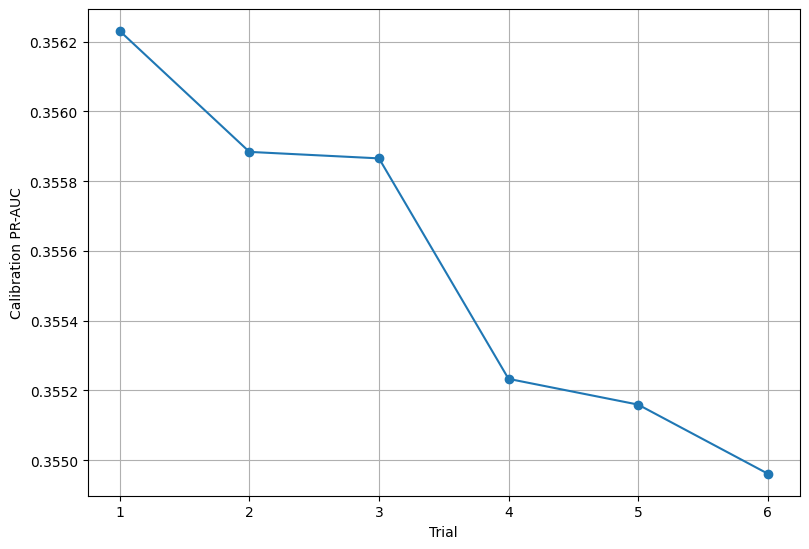

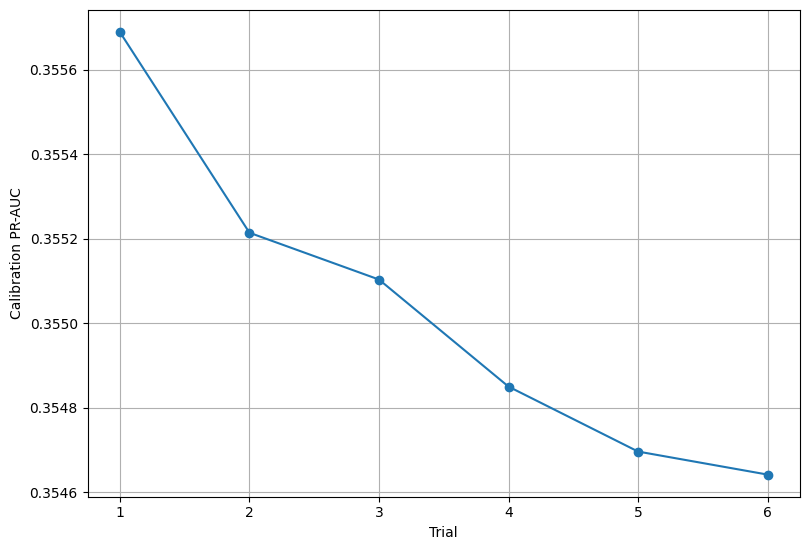

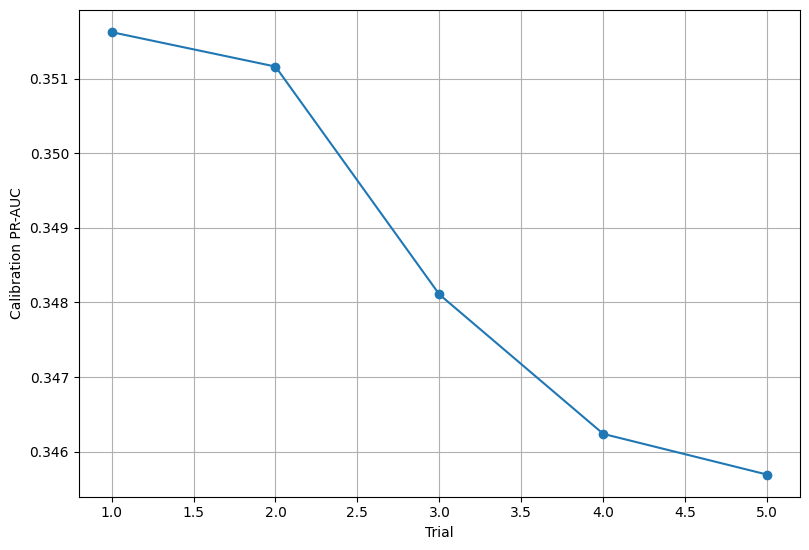

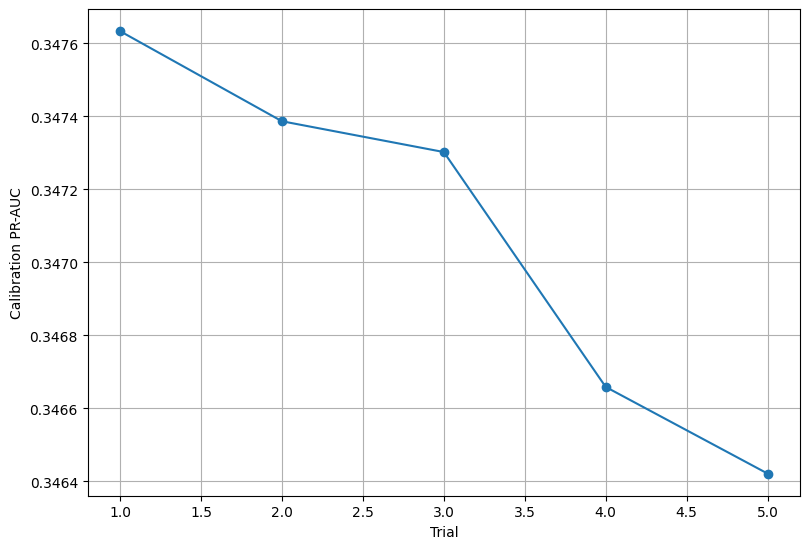

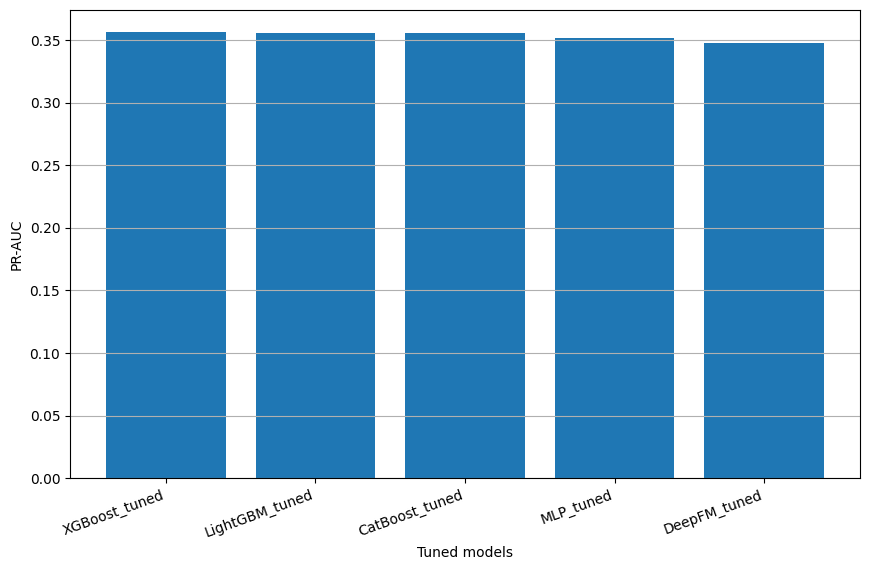

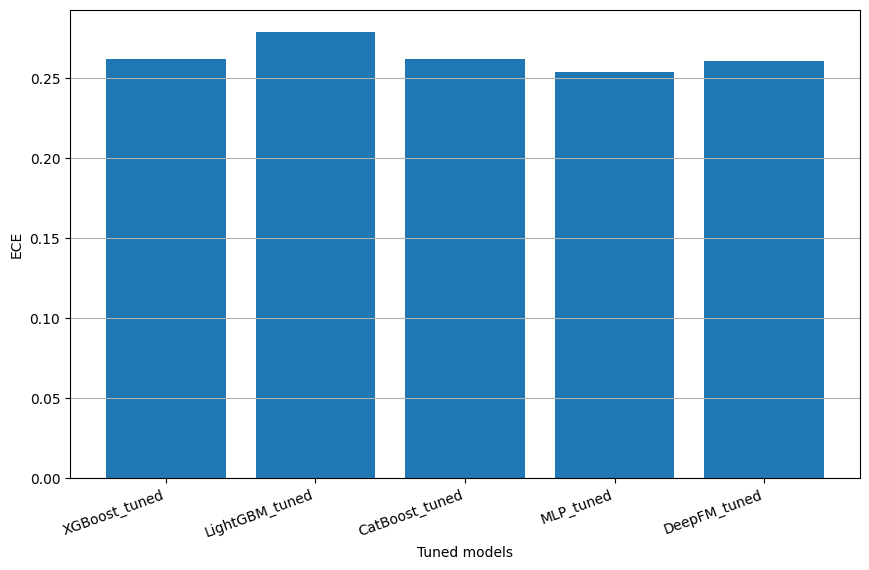


Module 4 complete.
Saved:
- small-budget tuning logs
- best tuned configs
- tuned val/cal prediction bundles
- tuned comparison tables
- tuning summary figures

Test split remains untouched.


In [4]:
# ============================================================
# Module 4 — Small-budget hyperparameter tuning (CORRECTED)
# Purpose:
#   Tune only the strongest candidate models from Modules 2–3
#   using a small, resource-aware search budget.
#
# Tuned models:
#   - LightGBM
#   - XGBoost
#   - CatBoost
#   - MLP
#   - DeepFM
#
# Training protocol:
#   fit on train_sub
#   early stopping on val_sub
#
# Selection protocol:
#   compare tuned candidates on calibration split only
#
# Important:
#   - test split remains untouched
#   - search budget intentionally small
#   - primary selection metric: PR_AUC on calibration split
#   - secondary tie-breakers: ROC_AUC, Brier, ECE
#
# Main corrections:
#   1) LightGBM: feature_pre_filter=False + rebuild Dataset per trial
#   2) Torch models: logits squeezed to shape [batch] before BCE loss
#
# Outputs:
#   - tuning logs
#   - best configs
#   - tuned val/cal prediction files
#   - tuned comparison tables
# ============================================================

# -------------------------
# Imports
# -------------------------
import os
import gc
import copy
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_train_sub", "X_val_sub", "X_cal",
    "Xtr_ml", "Xva_ml", "Xcal_ml",
    "y_train_sub", "y_val_sub", "y_cal",
    "CONT_COLS", "ORDINAL_COLS", "BINARY_COLS", "NOMINAL_COLS",
    "SEED", "TAB_DIR", "PRED_DIR", "MOD_DIR", "FIG_DIR",
    "evaluate_probs", "clip_probs", "save_figure_multi"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 4: {missing_vars}")

# -------------------------
# Reproducibility
# -------------------------
def seed_everything_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything_all(SEED)

# -------------------------
# Small-budget search config
# -------------------------
MAX_LGB_TRIALS = 6
MAX_XGB_TRIALS = 6
MAX_CAT_TRIALS = 6
MAX_MLP_TRIALS = 5
MAX_DFM_TRIALS = 5

device = "cuda" if torch.cuda.is_available() else "cpu"

pos = int((y_train_sub == 1).sum())
neg = int((y_train_sub == 0).sum())
scale_pos_weight = neg / max(pos, 1)

print("Module 4 search budget")
print("LightGBM trials:", MAX_LGB_TRIALS)
print("XGBoost  trials:", MAX_XGB_TRIALS)
print("CatBoost trials:", MAX_CAT_TRIALS)
print("MLP      trials:", MAX_MLP_TRIALS)
print("DeepFM   trials:", MAX_DFM_TRIALS)

# ============================================================
# Helpers
# ============================================================

def sort_tuning_df(df):
    return df.sort_values(
        ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
        ascending=[False, False, True, True]
    ).reset_index(drop=True)

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def plot_small_tuning_summary(df, metric_col, ylabel, save_path_base):
    if len(df) == 0:
        return
    tmp = df.copy().reset_index(drop=True)
    tmp["trial_idx"] = np.arange(1, len(tmp) + 1)

    plt.figure(figsize=(8.2, 5.6))
    plt.plot(tmp["trial_idx"], tmp[metric_col], marker="o")
    plt.xlabel("Trial")
    plt.ylabel(ylabel)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def trial_key_from_eval(row_eval):
    return (
        float(row_eval["PR_AUC"]),
        float(row_eval["ROC_AUC"]),
        -float(row_eval["Brier"]),
        -float(row_eval["ECE"]),
    )

# ============================================================
# Neural dataset / helpers
# ============================================================

class TabDataset(Dataset):
    def __init__(self, X_df, y):
        self.X = torch.tensor(X_df.values, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

@torch.no_grad()
def predict_torch_model(model, X_df, batch_size=4096, device="cpu"):
    model = model.to(device)
    model.eval()

    ds = torch.tensor(X_df.values, dtype=torch.float32)
    preds = []

    for i in range(0, len(ds), batch_size):
        xb = ds[i:i + batch_size].to(device)
        logits = model(xb).squeeze(-1)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        preds.append(p)

    return clip_probs(np.concatenate(preds))

def train_torch_binary_model(
    model,
    X_train_df,
    y_train,
    X_val_df,
    y_val,
    lr=1e-3,
    wd=1e-4,
    batch_size=2048,
    max_epochs=35,
    patience=5,
    pos_weight_value=None,
    robust_mode=False,
    robust_noise_std=0.02,
    robust_alpha=0.50,
    robust_lambda=0.20,
):
    seed_everything_all(SEED)

    train_ds = TabDataset(X_train_df, y_train.astype(np.float32))
    val_ds = TabDataset(X_val_df, y_val.astype(np.float32))

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=(device == "cuda")
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=(device == "cuda")
    )

    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))

    if pos_weight_value is not None:
        pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)
    else:
        pos_weight_tensor = None

    best_val = 1e18
    best_state = None
    bad_epochs = 0
    hist_rows = []

    for ep in range(1, max_epochs + 1):
        model.train()
        tr_loss_sum = 0.0
        n_tr = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(device == "cuda")):
                if robust_mode:
                    noise = torch.randn_like(xb) * robust_noise_std
                    xb_pert = xb + noise

                    logits_clean = model(xb).squeeze(-1)
                    logits_pert = model(xb_pert).squeeze(-1)

                    if pos_weight_tensor is None:
                        loss_clean = F.binary_cross_entropy_with_logits(logits_clean, yb)
                        loss_pert = F.binary_cross_entropy_with_logits(logits_pert, yb)
                    else:
                        loss_clean = F.binary_cross_entropy_with_logits(
                            logits_clean, yb, pos_weight=pos_weight_tensor
                        )
                        loss_pert = F.binary_cross_entropy_with_logits(
                            logits_pert, yb, pos_weight=pos_weight_tensor
                        )

                    p_clean = torch.sigmoid(logits_clean)
                    p_pert = torch.sigmoid(logits_pert)
                    loss_cons = F.mse_loss(p_clean, p_pert)

                    loss = loss_clean + robust_alpha * loss_pert + robust_lambda * loss_cons
                else:
                    logits = model(xb).squeeze(-1)
                    if pos_weight_tensor is None:
                        loss = F.binary_cross_entropy_with_logits(logits, yb)
                    else:
                        loss = F.binary_cross_entropy_with_logits(
                            logits, yb, pos_weight=pos_weight_tensor
                        )

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            tr_loss_sum += float(loss.item()) * bs
            n_tr += bs

        model.eval()
        va_loss_sum = 0.0
        n_va = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)

                logits = model(xb).squeeze(-1)
                if pos_weight_tensor is None:
                    vloss = F.binary_cross_entropy_with_logits(logits, yb)
                else:
                    vloss = F.binary_cross_entropy_with_logits(
                        logits, yb, pos_weight=pos_weight_tensor
                    )

                bs = xb.size(0)
                va_loss_sum += float(vloss.item()) * bs
                n_va += bs

        tr_loss = tr_loss_sum / max(n_tr, 1)
        va_loss = va_loss_sum / max(n_va, 1)

        hist_rows.append({
            "epoch": ep,
            "train_loss": tr_loss,
            "val_loss": va_loss,
        })

        if va_loss < best_val - 1e-6:
            best_val = va_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, pd.DataFrame(hist_rows)

# ============================================================
# Neural models
# ============================================================

INPUT_DIM = Xtr_ml.shape[1]

class MLPNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout=0.25):
        super().__init__()
        half_dim = max(hidden_dim // 2, 32)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, half_dim),
            nn.LayerNorm(half_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.8),
            nn.Linear(half_dim, 1),
        )

    def forward(self, x):
        return self.net(x)

class DeepFMNet(nn.Module):
    def __init__(self, n_features, k=16, hidden_dim=256, dropout=0.20):
        super().__init__()
        half_dim = max(hidden_dim // 2, 32)

        self.linear_w = nn.Parameter(torch.zeros(n_features))
        self.linear_b = nn.Parameter(torch.zeros(1))
        self.V = nn.Parameter(torch.randn(n_features, k) * 0.02)

        self.deep = nn.Sequential(
            nn.Linear(n_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, half_dim),
            nn.LayerNorm(half_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.8),
        )
        self.out = nn.Linear(half_dim + 2, 1)

    def forward(self, x):
        linear_term = (x * self.linear_w.unsqueeze(0)).sum(dim=1) + self.linear_b

        xv = x @ self.V
        xv2 = xv * xv
        x2v2 = (x * x) @ (self.V * self.V)
        fm_term = 0.5 * (xv2 - x2v2).sum(dim=1)

        h = self.deep(x)
        z = torch.cat([h, linear_term.unsqueeze(1), fm_term.unsqueeze(1)], dim=1)
        return self.out(z)

# ============================================================
# 4.1 LightGBM small search
# ============================================================

print("\n==============================")
print("Module 4A — LightGBM tuning")
print("==============================")

lgb_search_space = [
    dict(learning_rate=0.03, num_leaves=64, min_data_in_leaf=200, feature_fraction=0.85, bagging_fraction=0.85, lambda_l2=10.0, scale_pos_weight=scale_pos_weight * 1.00),
    dict(learning_rate=0.05, num_leaves=48, min_data_in_leaf=150, feature_fraction=0.90, bagging_fraction=0.90, lambda_l2=5.0,  scale_pos_weight=scale_pos_weight * 1.00),
    dict(learning_rate=0.03, num_leaves=96, min_data_in_leaf=250, feature_fraction=0.80, bagging_fraction=0.80, lambda_l2=15.0, scale_pos_weight=scale_pos_weight * 1.10),
    dict(learning_rate=0.02, num_leaves=64, min_data_in_leaf=300, feature_fraction=0.85, bagging_fraction=0.85, lambda_l2=20.0, scale_pos_weight=scale_pos_weight * 1.20),
    dict(learning_rate=0.05, num_leaves=80, min_data_in_leaf=200, feature_fraction=0.75, bagging_fraction=0.80, lambda_l2=10.0, scale_pos_weight=scale_pos_weight * 0.90),
    dict(learning_rate=0.03, num_leaves=48, min_data_in_leaf=250, feature_fraction=0.90, bagging_fraction=0.80, lambda_l2=8.0,  scale_pos_weight=scale_pos_weight * 1.15),
][:MAX_LGB_TRIALS]

lgb_trials = []
best_lgb_model = None
best_lgb_cfg = None
best_lgb_preds = None
best_lgb_key = None

for i, cfg in enumerate(lgb_search_space, 1):
    params = dict(
        objective="binary",
        boosting_type="gbdt",
        metric="auc",
        bagging_freq=1,
        verbosity=-1,
        seed=SEED,
        feature_pre_filter=False,
        **cfg,
    )

    # Rebuild Dataset inside each trial to avoid min_data_in_leaf / prefilter issue
    dtr_lgb = lgb.Dataset(
        Xtr_ml,
        label=y_train_sub.astype(int),
        feature_name=list(Xtr_ml.columns),
        free_raw_data=True,
    )
    dva_lgb = lgb.Dataset(
        Xva_ml,
        label=y_val_sub.astype(int),
        feature_name=list(Xtr_ml.columns),
        reference=dtr_lgb,
        free_raw_data=True,
    )

    model = lgb.train(
        params=params,
        train_set=dtr_lgb,
        num_boost_round=4000,
        valid_sets=[dva_lgb],
        callbacks=[lgb.early_stopping(150, verbose=False)]
    )

    p_val = clip_probs(model.predict(Xva_ml, num_iteration=model.best_iteration))
    p_cal = clip_probs(model.predict(Xcal_ml, num_iteration=model.best_iteration))

    row_val = evaluate_probs(y_val_sub, p_val, name="LightGBM_tuned_trial")
    row_cal = evaluate_probs(y_cal, p_cal, name="LightGBM_tuned_trial")

    row = {
        "trial": i,
        "best_iteration": int(model.best_iteration),
        **cfg,
        "PR_AUC": row_cal["PR_AUC"],
        "ROC_AUC": row_cal["ROC_AUC"],
        "Brier": row_cal["Brier"],
        "ECE": row_cal["ECE"],
        "val_PR_AUC": row_val["PR_AUC"],
        "val_ROC_AUC": row_val["ROC_AUC"],
        "cal_PR_AUC": row_cal["PR_AUC"],
        "cal_ROC_AUC": row_cal["ROC_AUC"],
        "cal_Brier": row_cal["Brier"],
        "cal_ECE": row_cal["ECE"],
    }
    lgb_trials.append(row)

    key = trial_key_from_eval(row_cal)
    if (best_lgb_key is None) or (key > best_lgb_key):
        best_lgb_key = key
        best_lgb_model = model
        best_lgb_cfg = {"params": params, "best_iteration": int(model.best_iteration)}
        best_lgb_preds = {"val": p_val.copy(), "cal": p_cal.copy()}

    print(f"LGB trial {i}/{len(lgb_search_space)} | cal PR_AUC={row_cal['PR_AUC']:.6f} | cal ROC_AUC={row_cal['ROC_AUC']:.6f}")

module4_lgb_trials_df = sort_tuning_df(pd.DataFrame(lgb_trials))
module4_lgb_trials_df.to_csv(TAB_DIR / "module4_lgb_tuning_trials.csv", index=False)
save_json(best_lgb_cfg, MOD_DIR / "module4_best_lgb_config.json")

# ============================================================
# 4.2 XGBoost small search
# ============================================================

print("\n==============================")
print("Module 4B — XGBoost tuning")
print("==============================")

xgb_search_space = [
    dict(eta=0.03, max_depth=6, min_child_weight=30, subsample=0.85, colsample_bytree=0.85, reg_lambda=10.0, scale_pos_weight=scale_pos_weight * 1.00),
    dict(eta=0.05, max_depth=5, min_child_weight=20, subsample=0.90, colsample_bytree=0.90, reg_lambda=8.0,  scale_pos_weight=scale_pos_weight * 1.00),
    dict(eta=0.03, max_depth=7, min_child_weight=40, subsample=0.80, colsample_bytree=0.80, reg_lambda=12.0, scale_pos_weight=scale_pos_weight * 1.10),
    dict(eta=0.02, max_depth=6, min_child_weight=35, subsample=0.85, colsample_bytree=0.85, reg_lambda=15.0, scale_pos_weight=scale_pos_weight * 1.20),
    dict(eta=0.05, max_depth=4, min_child_weight=25, subsample=0.90, colsample_bytree=0.80, reg_lambda=10.0, scale_pos_weight=scale_pos_weight * 0.95),
    dict(eta=0.03, max_depth=5, min_child_weight=30, subsample=0.80, colsample_bytree=0.90, reg_lambda=6.0,  scale_pos_weight=scale_pos_weight * 1.10),
][:MAX_XGB_TRIALS]

xgb_trials = []
best_xgb_model = None
best_xgb_cfg = None
best_xgb_preds = None
best_xgb_key = None

dtr_xgb = xgb.DMatrix(Xtr_ml.values, label=y_train_sub.astype(int), feature_names=list(Xtr_ml.columns))
dva_xgb = xgb.DMatrix(Xva_ml.values, label=y_val_sub.astype(int), feature_names=list(Xtr_ml.columns))
dcal_xgb = xgb.DMatrix(Xcal_ml.values, feature_names=list(Xtr_ml.columns))

for i, cfg in enumerate(xgb_search_space, 1):
    params = dict(
        objective="binary:logistic",
        eval_metric="auc",
        seed=SEED,
        **cfg,
    )

    model = xgb.train(
        params=params,
        dtrain=dtr_xgb,
        num_boost_round=3000,
        evals=[(dva_xgb, "valid")],
        early_stopping_rounds=150,
        verbose_eval=False
    )

    best_iter = model.best_iteration + 1 if model.best_iteration is not None else 3000
    p_val = clip_probs(model.predict(dva_xgb, iteration_range=(0, best_iter)))
    p_cal = clip_probs(model.predict(dcal_xgb, iteration_range=(0, best_iter)))

    row_val = evaluate_probs(y_val_sub, p_val, name="XGBoost_tuned_trial")
    row_cal = evaluate_probs(y_cal, p_cal, name="XGBoost_tuned_trial")

    row = {
        "trial": i,
        "best_iteration": int(best_iter),
        **cfg,
        "PR_AUC": row_cal["PR_AUC"],
        "ROC_AUC": row_cal["ROC_AUC"],
        "Brier": row_cal["Brier"],
        "ECE": row_cal["ECE"],
        "val_PR_AUC": row_val["PR_AUC"],
        "val_ROC_AUC": row_val["ROC_AUC"],
        "cal_PR_AUC": row_cal["PR_AUC"],
        "cal_ROC_AUC": row_cal["ROC_AUC"],
        "cal_Brier": row_cal["Brier"],
        "cal_ECE": row_cal["ECE"],
    }
    xgb_trials.append(row)

    key = trial_key_from_eval(row_cal)
    if (best_xgb_key is None) or (key > best_xgb_key):
        best_xgb_key = key
        best_xgb_model = model
        best_xgb_cfg = {"params": params, "best_iteration": int(best_iter)}
        best_xgb_preds = {"val": p_val.copy(), "cal": p_cal.copy()}

    print(f"XGB trial {i}/{len(xgb_search_space)} | cal PR_AUC={row_cal['PR_AUC']:.6f} | cal ROC_AUC={row_cal['ROC_AUC']:.6f}")

module4_xgb_trials_df = sort_tuning_df(pd.DataFrame(xgb_trials))
module4_xgb_trials_df.to_csv(TAB_DIR / "module4_xgb_tuning_trials.csv", index=False)
save_json(best_xgb_cfg, MOD_DIR / "module4_best_xgb_config.json")

# ============================================================
# 4.3 CatBoost small search
# ============================================================

print("\n==============================")
print("Module 4C — CatBoost tuning")
print("==============================")

Xtr_cat = X_train_sub.copy()
Xva_cat = X_val_sub.copy()
Xcal_cat = X_cal.copy()

for c in CONT_COLS + ORDINAL_COLS + BINARY_COLS:
    Xtr_cat[c] = pd.to_numeric(Xtr_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xva_cat[c] = pd.to_numeric(Xva_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xcal_cat[c] = pd.to_numeric(Xcal_cat[c], errors="coerce").fillna(Xtr_cat[c].median())

for c in NOMINAL_COLS:
    Xtr_cat[c] = Xtr_cat[c].astype(str).fillna("Other")
    Xva_cat[c] = Xva_cat[c].astype(str).fillna("Other")
    Xcal_cat[c] = Xcal_cat[c].astype(str).fillna("Other")

cat_feature_indices = [Xtr_cat.columns.get_loc(c) for c in NOMINAL_COLS]

cat_search_space = [
    dict(learning_rate=0.03, depth=6, l2_leaf_reg=10.0),
    dict(learning_rate=0.05, depth=5, l2_leaf_reg=8.0),
    dict(learning_rate=0.03, depth=7, l2_leaf_reg=12.0),
    dict(learning_rate=0.02, depth=6, l2_leaf_reg=15.0),
    dict(learning_rate=0.05, depth=4, l2_leaf_reg=10.0),
    dict(learning_rate=0.03, depth=5, l2_leaf_reg=6.0),
][:MAX_CAT_TRIALS]

cat_trials = []
best_cat_model = None
best_cat_cfg = None
best_cat_preds = None
best_cat_key = None

for i, cfg in enumerate(cat_search_space, 1):
    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        iterations=4000,
        auto_class_weights="Balanced",
        random_seed=SEED,
        verbose=False,
        **cfg,
    )

    model.fit(
        Xtr_cat,
        y_train_sub.astype(int),
        cat_features=cat_feature_indices,
        eval_set=(Xva_cat, y_val_sub.astype(int)),
        use_best_model=True,
        early_stopping_rounds=150,
        verbose=False
    )

    p_val = clip_probs(model.predict_proba(Xva_cat)[:, 1])
    p_cal = clip_probs(model.predict_proba(Xcal_cat)[:, 1])

    row_val = evaluate_probs(y_val_sub, p_val, name="CatBoost_tuned_trial")
    row_cal = evaluate_probs(y_cal, p_cal, name="CatBoost_tuned_trial")

    row = {
        "trial": i,
        "best_iteration": int(model.get_best_iteration()) if model.get_best_iteration() is not None else np.nan,
        **cfg,
        "PR_AUC": row_cal["PR_AUC"],
        "ROC_AUC": row_cal["ROC_AUC"],
        "Brier": row_cal["Brier"],
        "ECE": row_cal["ECE"],
        "val_PR_AUC": row_val["PR_AUC"],
        "val_ROC_AUC": row_val["ROC_AUC"],
        "cal_PR_AUC": row_cal["PR_AUC"],
        "cal_ROC_AUC": row_cal["ROC_AUC"],
        "cal_Brier": row_cal["Brier"],
        "cal_ECE": row_cal["ECE"],
    }
    cat_trials.append(row)

    key = trial_key_from_eval(row_cal)
    if (best_cat_key is None) or (key > best_cat_key):
        best_cat_key = key
        best_cat_model = model
        best_cat_cfg = {
            "params": {"iterations": 4000, "auto_class_weights": "Balanced", **cfg},
            "best_iteration": int(model.get_best_iteration()) if model.get_best_iteration() is not None else np.nan
        }
        best_cat_preds = {"val": p_val.copy(), "cal": p_cal.copy()}

    print(f"CAT trial {i}/{len(cat_search_space)} | cal PR_AUC={row_cal['PR_AUC']:.6f} | cal ROC_AUC={row_cal['ROC_AUC']:.6f}")

module4_cat_trials_df = sort_tuning_df(pd.DataFrame(cat_trials))
module4_cat_trials_df.to_csv(TAB_DIR / "module4_cat_tuning_trials.csv", index=False)
save_json(best_cat_cfg, MOD_DIR / "module4_best_cat_config.json")

# ============================================================
# 4.4 MLP small search
# ============================================================

print("\n==============================")
print("Module 4D — MLP tuning")
print("==============================")

mlp_search_space = [
    dict(hidden_dim=256, dropout=0.25, lr=1e-3, wd=1e-4, batch_size=2048, pos_mult=1.00),
    dict(hidden_dim=384, dropout=0.20, lr=8e-4, wd=1e-4, batch_size=2048, pos_mult=1.00),
    dict(hidden_dim=256, dropout=0.35, lr=1e-3, wd=5e-4, batch_size=2048, pos_mult=1.10),
    dict(hidden_dim=128, dropout=0.20, lr=1.2e-3, wd=1e-4, batch_size=1024, pos_mult=0.90),
    dict(hidden_dim=384, dropout=0.30, lr=8e-4, wd=5e-4, batch_size=2048, pos_mult=1.10),
][:MAX_MLP_TRIALS]

mlp_trials = []
best_mlp_model = None
best_mlp_cfg = None
best_mlp_preds = None
best_mlp_key = None
best_mlp_hist = None

for i, cfg in enumerate(mlp_search_space, 1):
    model = MLPNet(
        input_dim=INPUT_DIM,
        hidden_dim=cfg["hidden_dim"],
        dropout=cfg["dropout"],
    )

    pos_weight_value = float(scale_pos_weight * cfg["pos_mult"])

    model, hist_df = train_torch_binary_model(
        model=model,
        X_train_df=Xtr_ml,
        y_train=y_train_sub,
        X_val_df=Xva_ml,
        y_val=y_val_sub,
        lr=cfg["lr"],
        wd=cfg["wd"],
        batch_size=cfg["batch_size"],
        max_epochs=35,
        patience=5,
        pos_weight_value=pos_weight_value,
        robust_mode=False,
    )

    p_val = predict_torch_model(model, Xva_ml, batch_size=4096, device=device)
    p_cal = predict_torch_model(model, Xcal_ml, batch_size=4096, device=device)

    row_val = evaluate_probs(y_val_sub, p_val, name="MLP_tuned_trial")
    row_cal = evaluate_probs(y_cal, p_cal, name="MLP_tuned_trial")

    row = {
        "trial": i,
        **cfg,
        "PR_AUC": row_cal["PR_AUC"],
        "ROC_AUC": row_cal["ROC_AUC"],
        "Brier": row_cal["Brier"],
        "ECE": row_cal["ECE"],
        "val_PR_AUC": row_val["PR_AUC"],
        "val_ROC_AUC": row_val["ROC_AUC"],
        "cal_PR_AUC": row_cal["PR_AUC"],
        "cal_ROC_AUC": row_cal["ROC_AUC"],
        "cal_Brier": row_cal["Brier"],
        "cal_ECE": row_cal["ECE"],
    }
    mlp_trials.append(row)

    key = trial_key_from_eval(row_cal)
    if (best_mlp_key is None) or (key > best_mlp_key):
        best_mlp_key = key
        best_mlp_model = copy.deepcopy(model).cpu()
        best_mlp_cfg = row.copy()
        best_mlp_preds = {"val": p_val.copy(), "cal": p_cal.copy()}
        best_mlp_hist = hist_df.copy()

    print(f"MLP trial {i}/{len(mlp_search_space)} | cal PR_AUC={row_cal['PR_AUC']:.6f} | cal ROC_AUC={row_cal['ROC_AUC']:.6f}")

    del model
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

module4_mlp_trials_df = sort_tuning_df(pd.DataFrame(mlp_trials))
module4_mlp_trials_df.to_csv(TAB_DIR / "module4_mlp_tuning_trials.csv", index=False)
best_mlp_hist.to_csv(TAB_DIR / "module4_best_mlp_training_history.csv", index=False)
save_json(best_mlp_cfg, MOD_DIR / "module4_best_mlp_config.json")

# ============================================================
# 4.5 DeepFM small search
# ============================================================

print("\n==============================")
print("Module 4E — DeepFM tuning")
print("==============================")

dfm_search_space = [
    dict(k=16, hidden_dim=256, dropout=0.20, lr=1e-3, wd=1e-4, batch_size=2048, pos_mult=1.00, robust=False, noise_std=0.00, robust_alpha=0.00, robust_lambda=0.00),
    dict(k=16, hidden_dim=384, dropout=0.15, lr=8e-4, wd=1e-4, batch_size=2048, pos_mult=1.00, robust=False, noise_std=0.00, robust_alpha=0.00, robust_lambda=0.00),
    dict(k=16, hidden_dim=256, dropout=0.20, lr=1e-3, wd=1e-4, batch_size=2048, pos_mult=0.90, robust=True,  noise_std=0.015, robust_alpha=0.40, robust_lambda=0.15),
    dict(k=16, hidden_dim=256, dropout=0.25, lr=8e-4, wd=5e-4, batch_size=2048, pos_mult=1.10, robust=True,  noise_std=0.020, robust_alpha=0.50, robust_lambda=0.20),
    dict(k=8,  hidden_dim=256, dropout=0.15, lr=1e-3, wd=1e-4, batch_size=1024, pos_mult=1.00, robust=False, noise_std=0.00, robust_alpha=0.00, robust_lambda=0.00),
][:MAX_DFM_TRIALS]

dfm_trials = []
best_dfm_model = None
best_dfm_cfg = None
best_dfm_preds = None
best_dfm_key = None
best_dfm_hist = None

for i, cfg in enumerate(dfm_search_space, 1):
    model = DeepFMNet(
        n_features=INPUT_DIM,
        k=cfg["k"],
        hidden_dim=cfg["hidden_dim"],
        dropout=cfg["dropout"],
    )

    pos_weight_value = float(scale_pos_weight * cfg["pos_mult"])

    model, hist_df = train_torch_binary_model(
        model=model,
        X_train_df=Xtr_ml,
        y_train=y_train_sub,
        X_val_df=Xva_ml,
        y_val=y_val_sub,
        lr=cfg["lr"],
        wd=cfg["wd"],
        batch_size=cfg["batch_size"],
        max_epochs=35,
        patience=5,
        pos_weight_value=pos_weight_value,
        robust_mode=cfg["robust"],
        robust_noise_std=cfg["noise_std"],
        robust_alpha=cfg["robust_alpha"],
        robust_lambda=cfg["robust_lambda"],
    )

    p_val = predict_torch_model(model, Xva_ml, batch_size=4096, device=device)
    p_cal = predict_torch_model(model, Xcal_ml, batch_size=4096, device=device)

    row_val = evaluate_probs(y_val_sub, p_val, name="DeepFM_tuned_trial")
    row_cal = evaluate_probs(y_cal, p_cal, name="DeepFM_tuned_trial")

    row = {
        "trial": i,
        **cfg,
        "PR_AUC": row_cal["PR_AUC"],
        "ROC_AUC": row_cal["ROC_AUC"],
        "Brier": row_cal["Brier"],
        "ECE": row_cal["ECE"],
        "val_PR_AUC": row_val["PR_AUC"],
        "val_ROC_AUC": row_val["ROC_AUC"],
        "cal_PR_AUC": row_cal["PR_AUC"],
        "cal_ROC_AUC": row_cal["ROC_AUC"],
        "cal_Brier": row_cal["Brier"],
        "cal_ECE": row_cal["ECE"],
    }
    dfm_trials.append(row)

    key = trial_key_from_eval(row_cal)
    if (best_dfm_key is None) or (key > best_dfm_key):
        best_dfm_key = key
        best_dfm_model = copy.deepcopy(model).cpu()
        best_dfm_cfg = row.copy()
        best_dfm_preds = {"val": p_val.copy(), "cal": p_cal.copy()}
        best_dfm_hist = hist_df.copy()

    print(f"DFM trial {i}/{len(dfm_search_space)} | cal PR_AUC={row_cal['PR_AUC']:.6f} | cal ROC_AUC={row_cal['ROC_AUC']:.6f}")

    del model
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

module4_dfm_trials_df = sort_tuning_df(pd.DataFrame(dfm_trials))
module4_dfm_trials_df.to_csv(TAB_DIR / "module4_deepfm_tuning_trials.csv", index=False)
best_dfm_hist.to_csv(TAB_DIR / "module4_best_deepfm_training_history.csv", index=False)
save_json(best_dfm_cfg, MOD_DIR / "module4_best_deepfm_config.json")

# ============================================================
# 4.6 Final tuned comparison on val/cal
# ============================================================

module4_val_rows = []
module4_cal_rows = []

module4_val_rows.append(evaluate_probs(y_val_sub, best_lgb_preds["val"], name="LightGBM_tuned"))
module4_val_rows.append(evaluate_probs(y_val_sub, best_xgb_preds["val"], name="XGBoost_tuned"))
module4_val_rows.append(evaluate_probs(y_val_sub, best_cat_preds["val"], name="CatBoost_tuned"))
module4_val_rows.append(evaluate_probs(y_val_sub, best_mlp_preds["val"], name="MLP_tuned"))
module4_val_rows.append(evaluate_probs(y_val_sub, best_dfm_preds["val"], name="DeepFM_tuned"))

module4_cal_rows.append(evaluate_probs(y_cal, best_lgb_preds["cal"], name="LightGBM_tuned"))
module4_cal_rows.append(evaluate_probs(y_cal, best_xgb_preds["cal"], name="XGBoost_tuned"))
module4_cal_rows.append(evaluate_probs(y_cal, best_cat_preds["cal"], name="CatBoost_tuned"))
module4_cal_rows.append(evaluate_probs(y_cal, best_mlp_preds["cal"], name="MLP_tuned"))
module4_cal_rows.append(evaluate_probs(y_cal, best_dfm_preds["cal"], name="DeepFM_tuned"))

for r in module4_val_rows:
    r["split"] = "val_sub"
for r in module4_cal_rows:
    r["split"] = "cal"

module4_val_df = sort_tuning_df(pd.DataFrame(module4_val_rows))
module4_cal_df = sort_tuning_df(pd.DataFrame(module4_cal_rows))
module4_all_df = pd.concat([module4_val_df, module4_cal_df], axis=0, ignore_index=True)

module4_val_df.to_csv(TAB_DIR / "module4_tuned_models_val.csv", index=False)
module4_cal_df.to_csv(TAB_DIR / "module4_tuned_models_cal.csv", index=False)
module4_all_df.to_csv(TAB_DIR / "module4_tuned_models_all.csv", index=False)

print("\nModule 4 validation results:")
print(module4_val_df)

print("\nModule 4 calibration results:")
print(module4_cal_df)

# ============================================================
# 4.7 Save tuned prediction bundles
# ============================================================

module4_val_pred_df = pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_lgb_tuned_val": best_lgb_preds["val"],
    "p_xgb_tuned_val": best_xgb_preds["val"],
    "p_cat_tuned_val": best_cat_preds["val"],
    "p_mlp_tuned_val": best_mlp_preds["val"],
    "p_deepfm_tuned_val": best_dfm_preds["val"],
})
module4_cal_pred_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_lgb_tuned_cal": best_lgb_preds["cal"],
    "p_xgb_tuned_cal": best_xgb_preds["cal"],
    "p_cat_tuned_cal": best_cat_preds["cal"],
    "p_mlp_tuned_cal": best_mlp_preds["cal"],
    "p_deepfm_tuned_cal": best_dfm_preds["cal"],
})

module4_val_pred_df.to_csv(PRED_DIR / "module4_tuned_predictions_val.csv", index=False)
module4_cal_pred_df.to_csv(PRED_DIR / "module4_tuned_predictions_cal.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module4_tuned_predictions_val_cal.npz",
    y_val=y_val_sub.astype(np.int32),
    y_cal=y_cal.astype(np.int32),
    p_lgb_tuned_val=best_lgb_preds["val"].astype(np.float32),
    p_xgb_tuned_val=best_xgb_preds["val"].astype(np.float32),
    p_cat_tuned_val=best_cat_preds["val"].astype(np.float32),
    p_mlp_tuned_val=best_mlp_preds["val"].astype(np.float32),
    p_deepfm_tuned_val=best_dfm_preds["val"].astype(np.float32),
    p_lgb_tuned_cal=best_lgb_preds["cal"].astype(np.float32),
    p_xgb_tuned_cal=best_xgb_preds["cal"].astype(np.float32),
    p_cat_tuned_cal=best_cat_preds["cal"].astype(np.float32),
    p_mlp_tuned_cal=best_mlp_preds["cal"].astype(np.float32),
    p_deepfm_tuned_cal=best_dfm_preds["cal"].astype(np.float32),
)

# ============================================================
# 4.8 Compact best-config summary
# ============================================================

module4_best_cfg_summary_df = pd.DataFrame([
    {"model": "LightGBM_tuned", "best_config_json": json.dumps(best_lgb_cfg)},
    {"model": "XGBoost_tuned", "best_config_json": json.dumps(best_xgb_cfg)},
    {"model": "CatBoost_tuned", "best_config_json": json.dumps(best_cat_cfg)},
    {"model": "MLP_tuned", "best_config_json": json.dumps(best_mlp_cfg)},
    {"model": "DeepFM_tuned", "best_config_json": json.dumps(best_dfm_cfg)},
])
module4_best_cfg_summary_df.to_csv(TAB_DIR / "module4_best_config_summary.csv", index=False)

# ============================================================
# 4.9 Figures
# ============================================================

plot_small_tuning_summary(
    module4_lgb_trials_df,
    metric_col="cal_PR_AUC",
    ylabel="Calibration PR-AUC",
    save_path_base=FIG_DIR / "module4_lgb_tuning_curve"
)
plot_small_tuning_summary(
    module4_xgb_trials_df,
    metric_col="cal_PR_AUC",
    ylabel="Calibration PR-AUC",
    save_path_base=FIG_DIR / "module4_xgb_tuning_curve"
)
plot_small_tuning_summary(
    module4_cat_trials_df,
    metric_col="cal_PR_AUC",
    ylabel="Calibration PR-AUC",
    save_path_base=FIG_DIR / "module4_cat_tuning_curve"
)
plot_small_tuning_summary(
    module4_mlp_trials_df,
    metric_col="cal_PR_AUC",
    ylabel="Calibration PR-AUC",
    save_path_base=FIG_DIR / "module4_mlp_tuning_curve"
)
plot_small_tuning_summary(
    module4_dfm_trials_df,
    metric_col="cal_PR_AUC",
    ylabel="Calibration PR-AUC",
    save_path_base=FIG_DIR / "module4_deepfm_tuning_curve"
)

plt.figure(figsize=(8.8, 5.8))
plt.bar(module4_cal_df["model"], module4_cal_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.xlabel("Tuned models")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module4_tuned_models_cal_prauc")
plt.show()

plt.figure(figsize=(8.8, 5.8))
plt.bar(module4_cal_df["model"], module4_cal_df["ECE"])
plt.ylabel("ECE")
plt.xlabel("Tuned models")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module4_tuned_models_cal_ece")
plt.show()

# ============================================================
# 4.10 Export best tuned predictions for next modules
# ============================================================

p_lgb_tuned_val = best_lgb_preds["val"].copy()
p_lgb_tuned_cal = best_lgb_preds["cal"].copy()

p_xgb_tuned_val = best_xgb_preds["val"].copy()
p_xgb_tuned_cal = best_xgb_preds["cal"].copy()

p_cat_tuned_val = best_cat_preds["val"].copy()
p_cat_tuned_cal = best_cat_preds["cal"].copy()

p_mlp_tuned_val = best_mlp_preds["val"].copy()
p_mlp_tuned_cal = best_mlp_preds["cal"].copy()

p_dfm_tuned_val = best_dfm_preds["val"].copy()
p_dfm_tuned_cal = best_dfm_preds["cal"].copy()

print("\nModule 4 complete.")
print("Saved:")
print("- small-budget tuning logs")
print("- best tuned configs")
print("- tuned val/cal prediction bundles")
print("- tuned comparison tables")
print("- tuning summary figures")
print("\nTest split remains untouched.")

Total models available: 16

Top models:
                 model    PR_AUC   ROC_AUC     Brier       NLL       ECE  \
0            p_xgb_cal  0.356230  0.842946  0.166595  0.490157  0.262391   
1      p_xgb_tuned_cal  0.356230  0.842946  0.166595  0.490157  0.262391   
2      p_lgb_tuned_cal  0.355841  0.842963  0.180526  0.522922  0.278813   
3            p_cat_cal  0.355689  0.843966  0.166918  0.491719  0.262238   
4      p_cat_tuned_cal  0.355689  0.843966  0.166918  0.491719  0.262238   
5            p_lgb_cal  0.355548  0.842628  0.165238  0.483410  0.257022   
6      p_mlp_tuned_cal  0.351624  0.843167  0.161448  0.475398  0.253786   
7            p_MLP_cal  0.351022  0.842678  0.065382  0.226613  0.011352   
8         p_ResMLP_cal  0.350873  0.842058  0.065432  0.226031  0.007261   
9  p_DeepFM_Robust_cal  0.349042  0.842477  0.065437  0.226069  0.008179   

        MCE    p_mean  pos_rate      N  ...  Prec@bestF1  Rec@bestF1  \
0  0.528321  0.347976  0.085585  31980  ...     0.3

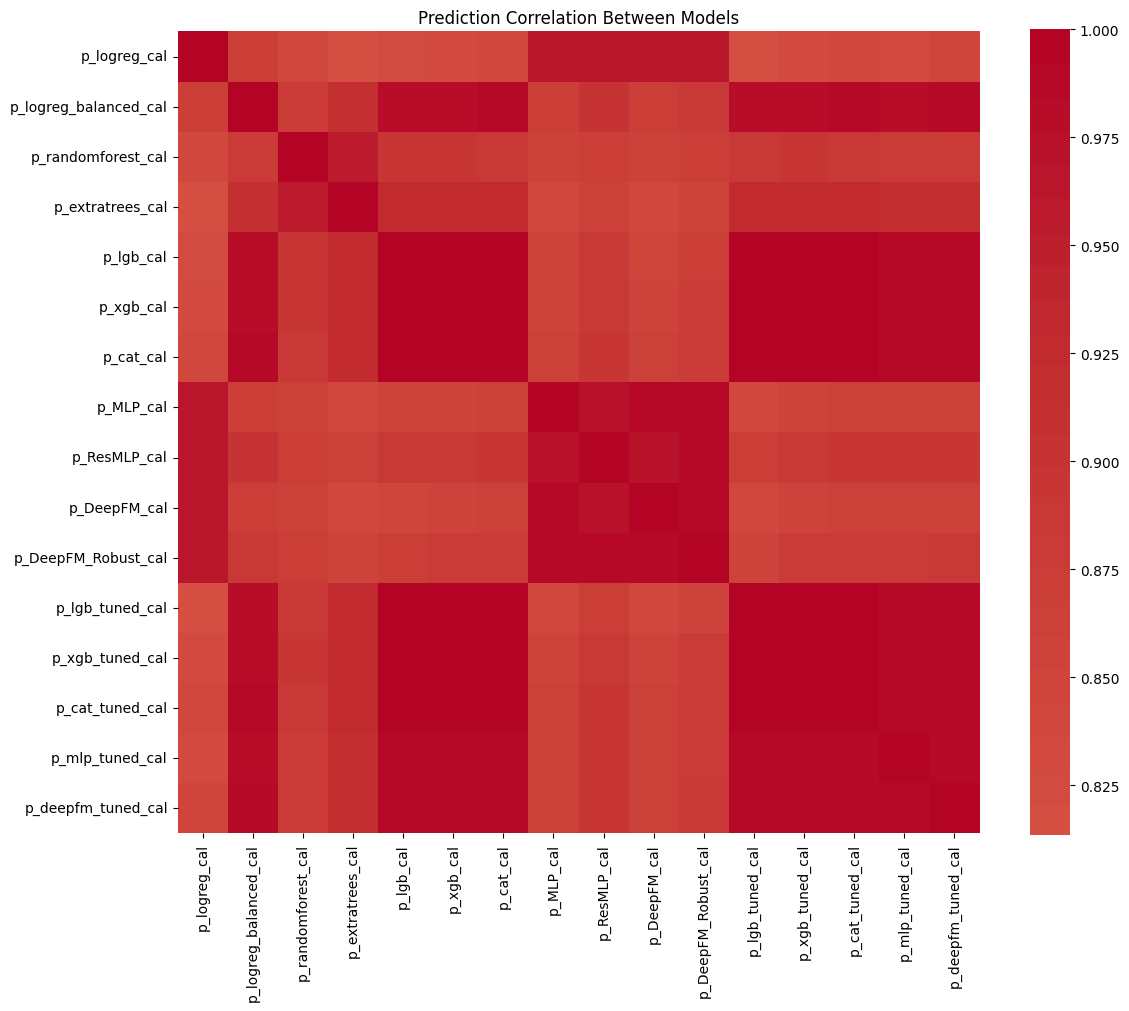

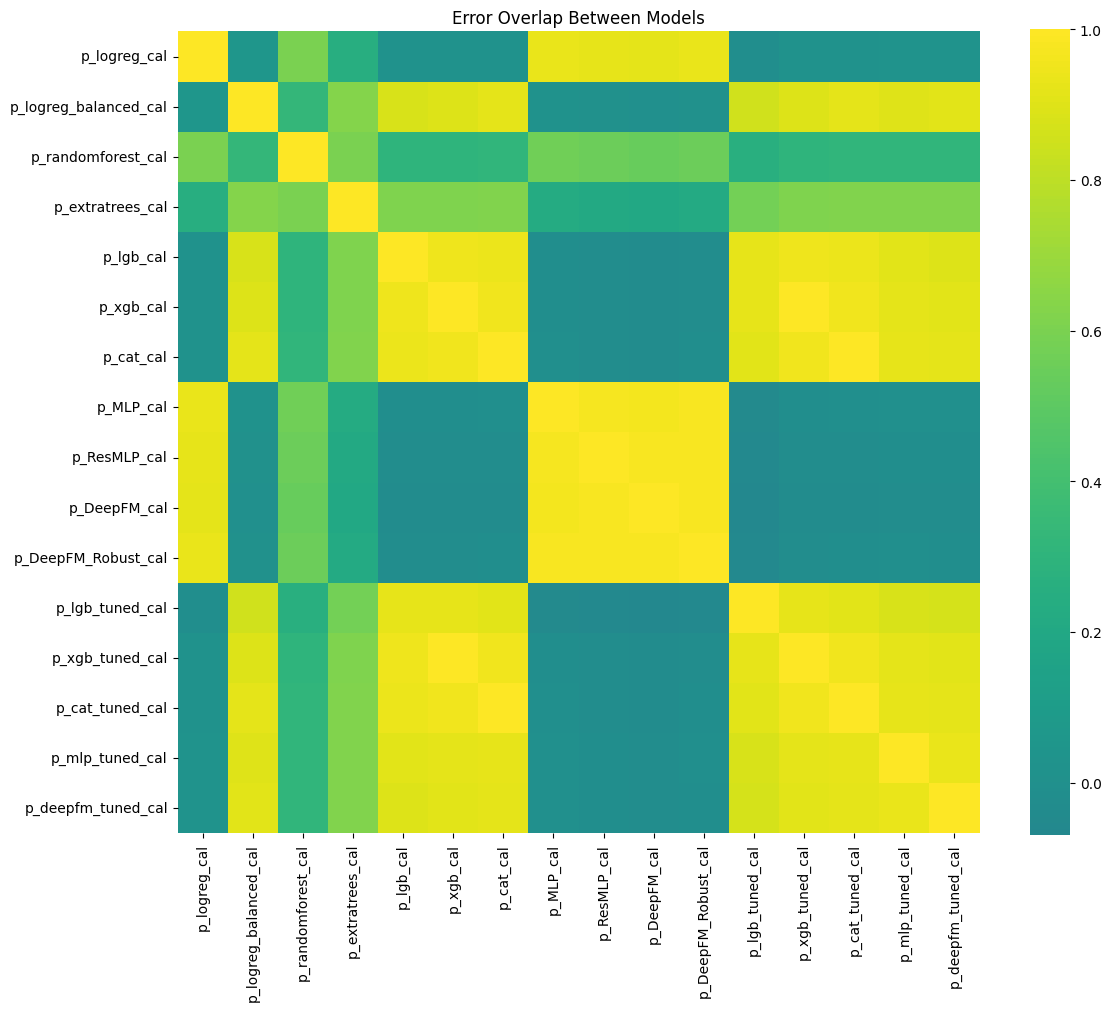


Candidate models within PR-AUC tolerance:
['p_xgb_cal', 'p_xgb_tuned_cal', 'p_lgb_tuned_cal', 'p_cat_cal', 'p_cat_tuned_cal', 'p_lgb_cal', 'p_mlp_tuned_cal', 'p_MLP_cal', 'p_ResMLP_cal', 'p_DeepFM_Robust_cal', 'p_DeepFM_cal', 'p_deepfm_tuned_cal', 'p_logreg_cal', 'p_logreg_balanced_cal']

Model diversity ranking:
                    model  diversity
12           p_logreg_cal   0.130558
10           p_DeepFM_cal   0.111136
7               p_MLP_cal   0.109775
9     p_DeepFM_Robust_cal   0.096659
8            p_ResMLP_cal   0.089325
2         p_lgb_tuned_cal   0.069409
5               p_lgb_cal   0.064268
6         p_mlp_tuned_cal   0.063800
11     p_deepfm_tuned_cal   0.062481
13  p_logreg_balanced_cal   0.062095
0               p_xgb_cal   0.061536
1         p_xgb_tuned_cal   0.061536
4         p_cat_tuned_cal   0.059765
3               p_cat_cal   0.059765

Expert shortlist:
['p_xgb_cal', 'p_xgb_tuned_cal', 'p_lgb_tuned_cal', 'p_cat_cal', 'p_cat_tuned_cal', 'p_lgb_cal']


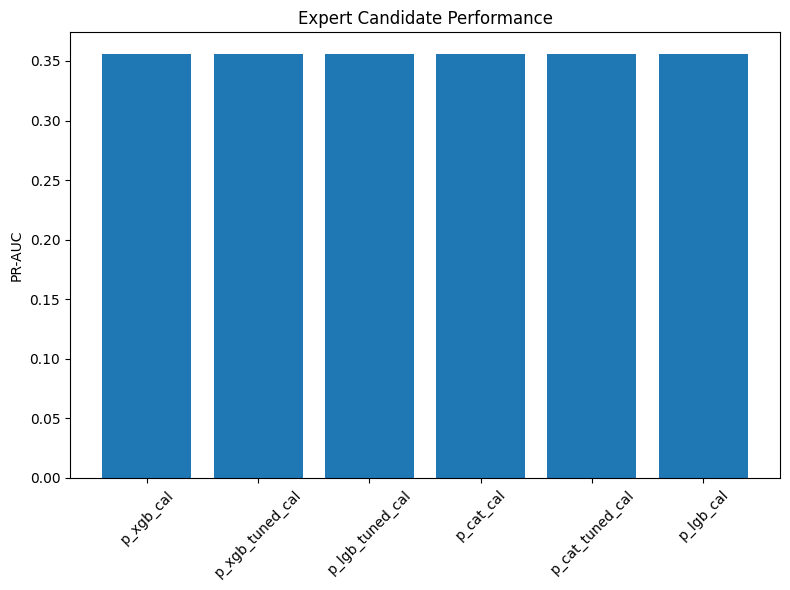


Module 5 complete.
Shortlist saved.


In [5]:
# ============================================================
# Module 5 — Expert Selection and Shortlist Locking
#
# Purpose:
#   Select candidate expert models from all benchmarked models
#
# Steps:
#   1. Load predictions from Modules 1–4
#   2. Evaluate calibration performance
#   3. Measure prediction correlation
#   4. Measure error overlap
#   5. Identify complementary models
#   6. Lock expert shortlist
#
# Output:
#   - model comparison table
#   - correlation heatmap
#   - error overlap table
#   - expert shortlist
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# Load prediction files
# ============================================================

m1 = pd.read_csv(PRED_DIR / "module1_simple_baseline_predictions_cal.csv")
m2 = pd.read_csv(PRED_DIR / "module2_boosting_predictions_cal.csv")
m3 = pd.read_csv(PRED_DIR / "module3_neural_cal_predictions.csv")
m4 = pd.read_csv(PRED_DIR / "module4_tuned_predictions_cal.csv")

y = m4["y_cal"].values

# ============================================================
# Collect predictions from all models
# ============================================================

pred_dict = {}

# Module 1
for c in m1.columns:
    if c.startswith("p_"):
        pred_dict[c] = m1[c].values

# Module 2
for c in m2.columns:
    if c.startswith("p_"):
        pred_dict[c] = m2[c].values

# Module 3
for c in m3.columns:
    if c.startswith("p_"):
        pred_dict[c] = m3[c].values

# Module 4 (tuned)
for c in m4.columns:
    if c.startswith("p_"):
        pred_dict[c] = m4[c].values

print("Total models available:", len(pred_dict))

# ============================================================
# Evaluate all models
# ============================================================

rows = []

for name, preds in pred_dict.items():

    res = evaluate_probs(y, preds, name=name)

    rows.append(res)

all_models_df = pd.DataFrame(rows)

all_models_df = all_models_df.sort_values(
    ["PR_AUC","ROC_AUC"],
    ascending=[False,False]
).reset_index(drop=True)

all_models_df.to_csv(TAB_DIR / "module5_all_model_performance.csv", index=False)

print("\nTop models:")
print(all_models_df.head(10))

# ============================================================
# Prediction correlation
# ============================================================

pred_matrix = pd.DataFrame(pred_dict)

corr = pred_matrix.corr()

plt.figure(figsize=(12,10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True,
    cbar=True
)

plt.title("Prediction Correlation Between Models")
save_figure_multi(FIG_DIR / "module5_prediction_correlation")
plt.show()

# ============================================================
# Error overlap
# ============================================================

threshold = 0.5

error_dict = {}

for name, preds in pred_dict.items():

    pred_label = (preds >= threshold).astype(int)

    error = (pred_label != y).astype(int)

    error_dict[name] = error

error_df = pd.DataFrame(error_dict)

error_overlap = error_df.corr()

plt.figure(figsize=(12,10))
sns.heatmap(
    error_overlap,
    cmap="viridis",
    center=0,
    square=True
)

plt.title("Error Overlap Between Models")
save_figure_multi(FIG_DIR / "module5_error_overlap")
plt.show()

# ============================================================
# Candidate filtering
# ============================================================

# Keep models close to best PR-AUC

best_prauc = all_models_df["PR_AUC"].max()

candidate_df = all_models_df[
    all_models_df["PR_AUC"] >= best_prauc - 0.01
]

candidate_models = candidate_df["model"].tolist()

print("\nCandidate models within PR-AUC tolerance:")
print(candidate_models)

# ============================================================
# Diversity score
# ============================================================

diversity_scores = []

for m in candidate_models:

    corrs = corr[m].drop(m)

    diversity = 1 - corrs.mean()

    diversity_scores.append((m, diversity))

diversity_df = pd.DataFrame(
    diversity_scores,
    columns=["model","diversity"]
)

diversity_df = diversity_df.sort_values(
    "diversity",
    ascending=False
)

print("\nModel diversity ranking:")
print(diversity_df)

# ============================================================
# Expert shortlist
# ============================================================

# choose top diverse high-performance models

shortlist = candidate_models[:]

# limit shortlist size
shortlist = shortlist[:6]

shortlist_df = pd.DataFrame({
    "expert_candidate": shortlist
})

shortlist_df.to_csv(
    TAB_DIR / "module5_expert_shortlist.csv",
    index=False
)

print("\nExpert shortlist:")
print(shortlist)

# ============================================================
# Visualization of shortlist performance
# ============================================================

short_df = all_models_df[
    all_models_df["model"].isin(shortlist)
]

plt.figure(figsize=(8,6))

plt.bar(
    short_df["model"],
    short_df["PR_AUC"]
)

plt.xticks(rotation=45)
plt.ylabel("PR-AUC")

plt.title("Expert Candidate Performance")

save_figure_multi(
    FIG_DIR / "module5_expert_shortlist_performance"
)

plt.show()

print("\nModule 5 complete.")
print("Shortlist saved.")

Total calibration prediction vectors collected: 16
Models: ['p_DeepFM_Robust_cal', 'p_DeepFM_cal', 'p_MLP_cal', 'p_ResMLP_cal', 'p_cat_cal', 'p_cat_tuned_cal', 'p_deepfm_tuned_cal', 'p_extratrees_cal', 'p_lgb_cal', 'p_lgb_tuned_cal', 'p_logreg_balanced_cal', 'p_logreg_cal', 'p_mlp_tuned_cal', 'p_randomforest_cal', 'p_xgb_cal', 'p_xgb_tuned_cal']

All-model calibration performance:
              model         family       base_group  is_tuned    PR_AUC  \
0           XGBoost       boosting          xgboost         0  0.356230   
1     XGBoost_tuned       boosting          xgboost         1  0.356230   
2    LightGBM_tuned       boosting         lightgbm         1  0.355841   
3          CatBoost       boosting         catboost         0  0.355689   
4    CatBoost_tuned       boosting         catboost         1  0.355689   
5          LightGBM       boosting         lightgbm         0  0.355548   
6         MLP_tuned         neural              mlp         1  0.351624   
7               

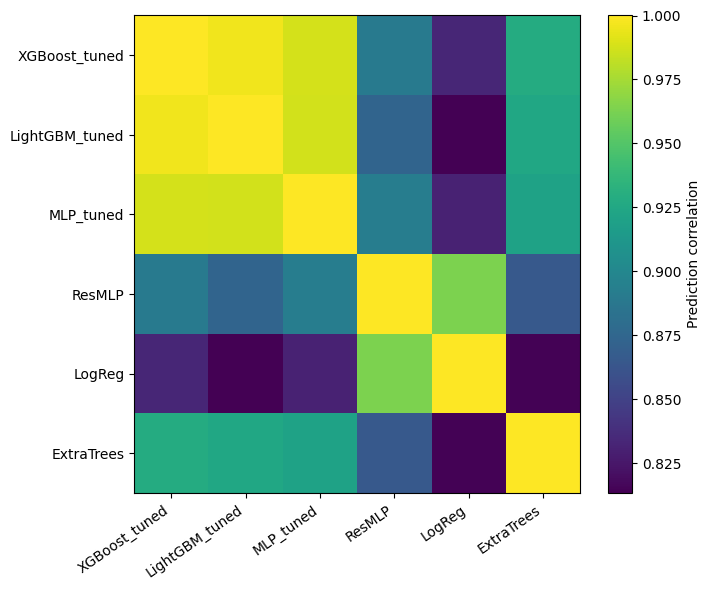


Lowest-correlation representative pairs:
          model_1     model_2  prediction_corr
0  LightGBM_tuned      LogReg         0.813409
1          LogReg  ExtraTrees         0.814709
2       MLP_tuned      LogReg         0.831133
3   XGBoost_tuned      LogReg         0.833650
4          ResMLP  ExtraTrees         0.865258
5  LightGBM_tuned      ResMLP         0.873762
6   XGBoost_tuned      ResMLP         0.889659
7       MLP_tuned      ResMLP         0.892827
8       MLP_tuned  ExtraTrees         0.920619
9  LightGBM_tuned  ExtraTrees         0.924459


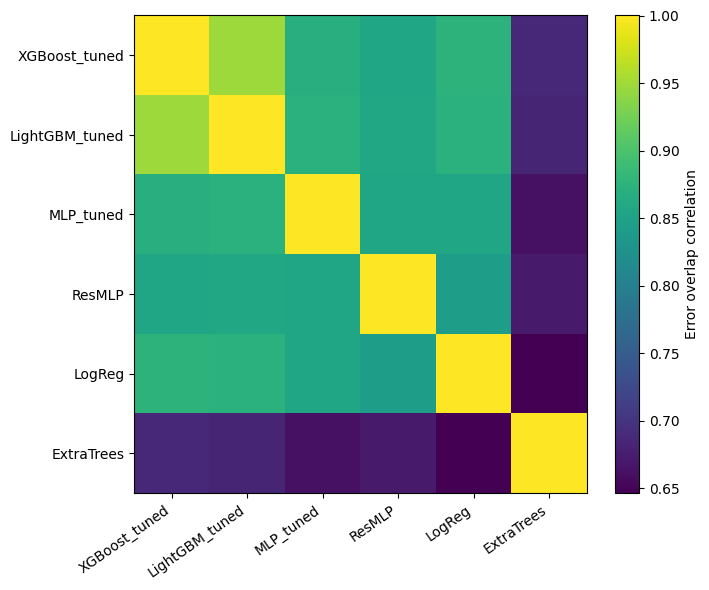


Lowest error-overlap representative pairs:
          model_1     model_2  error_overlap_corr
0          LogReg  ExtraTrees            0.646511
1       MLP_tuned  ExtraTrees            0.662223
2          ResMLP  ExtraTrees            0.671939
3  LightGBM_tuned  ExtraTrees            0.682483
4   XGBoost_tuned  ExtraTrees            0.686821
5          ResMLP      LogReg            0.842722
6       MLP_tuned      LogReg            0.853761
7   XGBoost_tuned      ResMLP            0.855674
8       MLP_tuned      ResMLP            0.855956
9  LightGBM_tuned      ResMLP            0.857794

Representative models with diversity-aware scoring:
            model         family    PR_AUC   ROC_AUC     Brier       ECE  \
0          LogReg       logistic  0.347615  0.839919  0.065621  0.007767   
1          ResMLP         neural  0.350873  0.842058  0.065432  0.007261   
2   XGBoost_tuned       boosting  0.356230  0.842946  0.166595  0.262391   
3  LightGBM_tuned       boosting  0.355841  0.842

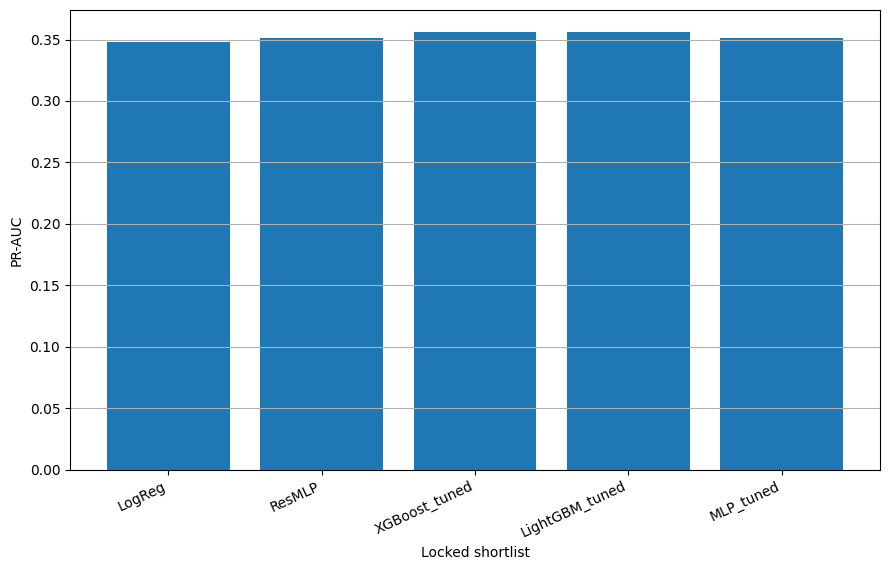

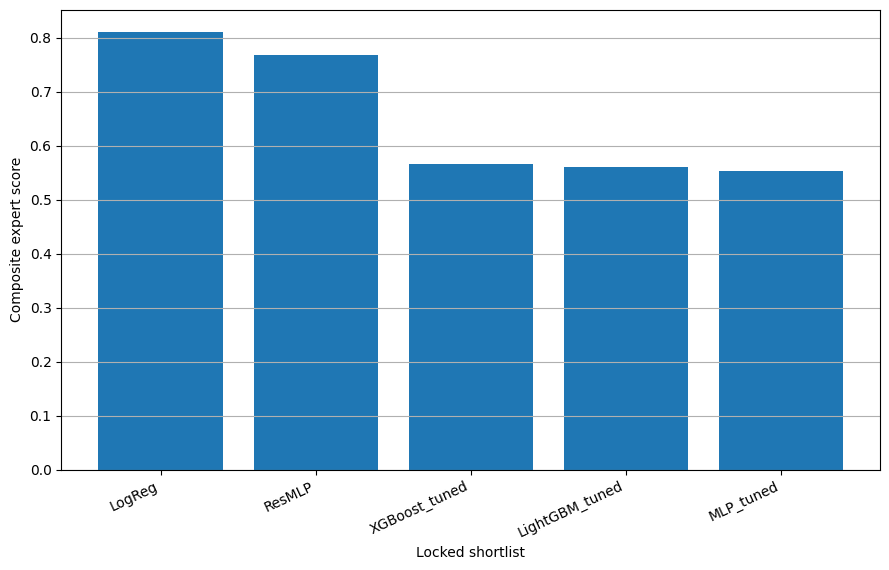


Module 5 complete.
Saved:
- all-model calibration table
- best variant per base model
- family summary
- family-aware representatives
- prediction correlation / error overlap analyses
- diversity-aware scored representative table
- locked shortlist + reserve candidate

Next step: Module 6 — ensemble construction from locked shortlist.


In [6]:
# ============================================================
# Module 5 — Family-aware expert selection and shortlist locking
#
# Purpose:
#   Select candidate experts from all benchmarked models in a
#   scientifically cleaner way than simple PR-AUC thresholding.
#
# Main idea:
#   1) gather all calibration predictions
#   2) evaluate every model on calibration split
#   3) assign each model to a model family
#   4) keep only the best representative(s) per family
#   5) analyze diversity among family representatives
#   6) lock a final shortlist for ensemble construction
#
# Families:
#   - logistic
#   - bagging_trees
#   - boosting
#   - neural
#
# Outputs:
#   - all-model calibration table
#   - family summary table
#   - family representative table
#   - prediction correlation heatmap
#   - error overlap heatmap
#   - locked shortlist table
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "PRED_DIR", "TAB_DIR", "FIG_DIR",
    "evaluate_probs", "clip_probs", "save_figure_multi"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 5: {missing_vars}")

# ============================================================
# 5.1 Load calibration prediction files
# ============================================================

# Module 1
m1 = pd.read_csv(PRED_DIR / "module1_simple_baseline_predictions_cal.csv")

# Module 2
m2 = pd.read_csv(PRED_DIR / "module2_boosting_predictions_cal.csv")

# Module 3
m3 = pd.read_csv(PRED_DIR / "module3_neural_cal_predictions.csv")

# Module 4
m4 = pd.read_csv(PRED_DIR / "module4_tuned_predictions_cal.csv")

# -------------------------
# Sanity checks
# -------------------------
if "y_cal" not in m1.columns:
    raise ValueError("Module 1 calibration file must contain column 'y_cal'.")
if "y_cal" not in m2.columns:
    raise ValueError("Module 2 calibration file must contain column 'y_cal'.")
if "y_cal" not in m3.columns:
    raise ValueError("Module 3 calibration file must contain column 'y_cal'.")
if "y_cal" not in m4.columns:
    raise ValueError("Module 4 calibration file must contain column 'y_cal'.")

y_cal_1 = m1["y_cal"].astype(int).values
y_cal_2 = m2["y_cal"].astype(int).values
y_cal_3 = m3["y_cal"].astype(int).values
y_cal_4 = m4["y_cal"].astype(int).values

if not (np.array_equal(y_cal_1, y_cal_2) and np.array_equal(y_cal_1, y_cal_3) and np.array_equal(y_cal_1, y_cal_4)):
    raise ValueError("y_cal mismatch across prediction files. Please verify saved calibration predictions.")

y_cal = y_cal_1.copy()

# ============================================================
# 5.2 Collect all calibration predictions
# ============================================================

pred_dict = {}

# Module 1
for c in m1.columns:
    if c.startswith("p_") and c.endswith("_cal"):
        pred_dict[c] = clip_probs(m1[c].values)

# Module 2
for c in m2.columns:
    if c.startswith("p_") and c.endswith("_cal"):
        pred_dict[c] = clip_probs(m2[c].values)

# Module 3
for c in m3.columns:
    if c.startswith("p_") and c.endswith("_cal"):
        pred_dict[c] = clip_probs(m3[c].values)

# Module 4
for c in m4.columns:
    if c.startswith("p_") and c.endswith("_cal"):
        pred_dict[c] = clip_probs(m4[c].values)

print("Total calibration prediction vectors collected:", len(pred_dict))
print("Models:", sorted(pred_dict.keys()))

# ============================================================
# 5.3 Naming helpers
# ============================================================

def nice_model_name(pred_col):
    """
    Convert saved prediction column names to cleaner model names.
    Example:
      p_xgb_tuned_cal -> XGBoost_tuned
      p_logreg_cal    -> LogReg
    """
    name = pred_col
    name = re.sub(r"^p_", "", name)
    name = re.sub(r"_cal$", "", name)

    mapping = {
        "logreg": "LogReg",
        "logreg_balanced": "LogReg_balanced",
        "randomforest": "RandomForest",
        "extratrees": "ExtraTrees",
        "lgb": "LightGBM",
        "xgb": "XGBoost",
        "cat": "CatBoost",
        "MLP": "MLP",
        "ResMLP": "ResMLP",
        "DeepFM": "DeepFM",
        "DeepFM_Robust": "DeepFM_Robust",
        "lgb_tuned": "LightGBM_tuned",
        "xgb_tuned": "XGBoost_tuned",
        "cat_tuned": "CatBoost_tuned",
        "mlp_tuned": "MLP_tuned",
        "deepfm_tuned": "DeepFM_tuned",
    }
    return mapping.get(name, name)

def assign_family(nice_name):
    low = nice_name.lower()

    if "logreg" in low:
        return "logistic"
    if ("randomforest" in low) or ("extratrees" in low):
        return "bagging_trees"
    if ("lightgbm" in low) or ("xgboost" in low) or ("catboost" in low):
        return "boosting"
    if ("mlp" in low) or ("deepfm" in low) or ("resmlp" in low):
        return "neural"
    return "other"

def assign_base_model_group(nice_name):
    """
    Group raw and tuned versions of the same underlying architecture.
    """
    low = nice_name.lower()

    if "logreg_balanced" in low:
        return "logreg_balanced"
    if "logreg" in low:
        return "logreg"
    if "randomforest" in low:
        return "randomforest"
    if "extratrees" in low:
        return "extratrees"
    if "lightgbm" in low:
        return "lightgbm"
    if "xgboost" in low:
        return "xgboost"
    if "catboost" in low:
        return "catboost"
    if "resmlp" in low:
        return "resmlp"
    if "deepfm_robust" in low:
        return "deepfm_robust"
    if "deepfm" in low:
        return "deepfm"
    if "mlp" in low:
        return "mlp"
    return nice_name.lower()

def is_tuned_model(nice_name):
    return "_tuned" in nice_name.lower()

# ============================================================
# 5.4 Evaluate all models on calibration split
# ============================================================

all_rows = []
for pred_col, preds in pred_dict.items():
    name = nice_model_name(pred_col)
    row = evaluate_probs(y_cal, preds, name=name)
    row["pred_col"] = pred_col
    row["family"] = assign_family(name)
    row["base_group"] = assign_base_model_group(name)
    row["is_tuned"] = int(is_tuned_model(name))
    all_rows.append(row)

module5_all_df = pd.DataFrame(all_rows)
module5_all_df = module5_all_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
    ascending=[False, False, True, True]
).reset_index(drop=True)

module5_all_df.to_csv(TAB_DIR / "module5_all_models_calibration_performance.csv", index=False)

print("\nAll-model calibration performance:")
print(module5_all_df[["model", "family", "base_group", "is_tuned", "PR_AUC", "ROC_AUC", "Brier", "ECE"]].head(20))

# ============================================================
# 5.5 Keep best variant within each base model group
# Example:
#   choose between XGBoost and XGBoost_tuned
#   choose between CatBoost and CatBoost_tuned
# ============================================================

group_best_rows = []
for base_group, g in module5_all_df.groupby("base_group"):
    g2 = g.sort_values(
        ["PR_AUC", "ROC_AUC", "Brier", "ECE", "is_tuned"],
        ascending=[False, False, True, True, False]
    ).reset_index(drop=True)
    best_row = g2.iloc[0].copy()
    group_best_rows.append(best_row)

module5_group_best_df = pd.DataFrame(group_best_rows)
module5_group_best_df = module5_group_best_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
    ascending=[False, False, True, True]
).reset_index(drop=True)

module5_group_best_df.to_csv(TAB_DIR / "module5_best_variant_per_base_model.csv", index=False)

print("\nBest variant within each base-model group:")
print(module5_group_best_df[["model", "family", "base_group", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# 5.6 Family summary
# ============================================================

family_rows = []
for fam, g in module5_group_best_df.groupby("family"):
    g = g.sort_values(
        ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
        ascending=[False, False, True, True]
    ).reset_index(drop=True)

    row = {
        "family": fam,
        "n_representatives": int(len(g)),
        "best_model": g.iloc[0]["model"],
        "best_PR_AUC": float(g.iloc[0]["PR_AUC"]),
        "best_ROC_AUC": float(g.iloc[0]["ROC_AUC"]),
        "best_Brier": float(g.iloc[0]["Brier"]),
        "best_ECE": float(g.iloc[0]["ECE"]),
    }
    family_rows.append(row)

module5_family_summary_df = pd.DataFrame(family_rows).sort_values(
    ["best_PR_AUC", "best_ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

module5_family_summary_df.to_csv(TAB_DIR / "module5_family_summary.csv", index=False)

print("\nFamily summary:")
print(module5_family_summary_df)

# ============================================================
# 5.7 Family-aware representative selection
#
# Rule:
#   - keep top 2 boosting representatives
#   - keep top 2 neural representatives
#   - keep top 1 logistic representative
#   - keep top 1 bagging-tree representative
#
# This creates a manageable shortlist before diversity analysis.
# ============================================================

def top_n_from_family(df, family_name, n_keep):
    g = df[df["family"] == family_name].copy()
    g = g.sort_values(
        ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
        ascending=[False, False, True, True]
    ).reset_index(drop=True)
    return g.head(n_keep)

rep_parts = []
rep_parts.append(top_n_from_family(module5_group_best_df, "boosting", 2))
rep_parts.append(top_n_from_family(module5_group_best_df, "neural", 2))
rep_parts.append(top_n_from_family(module5_group_best_df, "logistic", 1))
rep_parts.append(top_n_from_family(module5_group_best_df, "bagging_trees", 1))

module5_rep_df = pd.concat(rep_parts, axis=0, ignore_index=True)
module5_rep_df = module5_rep_df.drop_duplicates(subset=["pred_col"]).reset_index(drop=True)
module5_rep_df = module5_rep_df.sort_values(
    ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
    ascending=[False, False, True, True]
).reset_index(drop=True)

module5_rep_df.to_csv(TAB_DIR / "module5_family_representatives.csv", index=False)

print("\nFamily-aware representatives before diversity filtering:")
print(module5_rep_df[["model", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# 5.8 Diversity analysis among representatives
# ============================================================

rep_pred_cols = module5_rep_df["pred_col"].tolist()
rep_model_names = module5_rep_df["model"].tolist()

rep_pred_matrix = pd.DataFrame({
    row["model"]: pred_dict[row["pred_col"]]
    for _, row in module5_rep_df.iterrows()
})

corr_df = rep_pred_matrix.corr()

plt.figure(figsize=(1.2 * max(5, len(rep_model_names)), 1.0 * max(5, len(rep_model_names))))
im = plt.imshow(corr_df.values, aspect="auto")
plt.xticks(range(len(rep_model_names)), rep_model_names, rotation=35, ha="right")
plt.yticks(range(len(rep_model_names)), rep_model_names)
cbar = plt.colorbar(im)
cbar.set_label("Prediction correlation")
save_figure_multi(FIG_DIR / "module5_representative_prediction_correlation")
plt.show()

corr_long_rows = []
for i, m1_name in enumerate(rep_model_names):
    for j, m2_name in enumerate(rep_model_names):
        if j <= i:
            continue
        corr_long_rows.append({
            "model_1": m1_name,
            "model_2": m2_name,
            "prediction_corr": float(corr_df.loc[m1_name, m2_name]),
        })

module5_corr_long_df = pd.DataFrame(corr_long_rows).sort_values(
    "prediction_corr", ascending=True
).reset_index(drop=True)
module5_corr_long_df.to_csv(TAB_DIR / "module5_representative_prediction_correlation_pairs.csv", index=False)

print("\nLowest-correlation representative pairs:")
print(module5_corr_long_df.head(10))

# ============================================================
# 5.9 Error-overlap analysis among representatives
#
# Use each model's own best-F1 threshold from evaluate_probs
# ============================================================

error_bin_df = pd.DataFrame(index=np.arange(len(y_cal)))

for _, row in module5_rep_df.iterrows():
    model_name = row["model"]
    pred_col = row["pred_col"]
    preds = pred_dict[pred_col]
    thr = float(row["thr_bestF1"])
    pred_label = (preds >= thr).astype(int)
    error_bin_df[model_name] = (pred_label != y_cal).astype(int)

error_overlap_df = error_bin_df.corr()

plt.figure(figsize=(1.2 * max(5, len(rep_model_names)), 1.0 * max(5, len(rep_model_names))))
im = plt.imshow(error_overlap_df.values, aspect="auto")
plt.xticks(range(len(rep_model_names)), rep_model_names, rotation=35, ha="right")
plt.yticks(range(len(rep_model_names)), rep_model_names)
cbar = plt.colorbar(im)
cbar.set_label("Error overlap correlation")
save_figure_multi(FIG_DIR / "module5_representative_error_overlap")
plt.show()

error_long_rows = []
for i, m1_name in enumerate(rep_model_names):
    for j, m2_name in enumerate(rep_model_names):
        if j <= i:
            continue
        error_long_rows.append({
            "model_1": m1_name,
            "model_2": m2_name,
            "error_overlap_corr": float(error_overlap_df.loc[m1_name, m2_name]),
        })

module5_error_long_df = pd.DataFrame(error_long_rows).sort_values(
    "error_overlap_corr", ascending=True
).reset_index(drop=True)
module5_error_long_df.to_csv(TAB_DIR / "module5_representative_error_overlap_pairs.csv", index=False)

print("\nLowest error-overlap representative pairs:")
print(module5_error_long_df.head(10))

# ============================================================
# 5.10 Diversity score
#
# Higher means more different from the other representatives.
# ============================================================

div_rows = []
for model_name in rep_model_names:
    mean_corr = float(corr_df.loc[model_name].drop(model_name).mean()) if len(rep_model_names) > 1 else 1.0
    mean_err_corr = float(error_overlap_df.loc[model_name].drop(model_name).mean()) if len(rep_model_names) > 1 else 1.0

    div_rows.append({
        "model": model_name,
        "mean_prediction_corr_to_others": mean_corr,
        "mean_error_overlap_to_others": mean_err_corr,
        "prediction_diversity": float(1.0 - mean_corr),
        "error_diversity": float(1.0 - mean_err_corr),
    })

module5_div_df = pd.DataFrame(div_rows)
module5_div_df.to_csv(TAB_DIR / "module5_representative_diversity_scores.csv", index=False)

# merge with performance
module5_rep_scored_df = module5_rep_df.merge(module5_div_df, on="model", how="left")

# normalized composite score
def normalize_series(s):
    s = s.astype(float)
    if s.max() - s.min() < 1e-12:
        return pd.Series(np.ones(len(s)), index=s.index)
    return (s - s.min()) / (s.max() - s.min())

tmp = module5_rep_scored_df.copy()
tmp["norm_prauc"] = normalize_series(tmp["PR_AUC"])
tmp["norm_rocauc"] = normalize_series(tmp["ROC_AUC"])
tmp["norm_brier_good"] = normalize_series(-tmp["Brier"])
tmp["norm_ece_good"] = normalize_series(-tmp["ECE"])
tmp["norm_pred_div"] = normalize_series(tmp["prediction_diversity"])
tmp["norm_err_div"] = normalize_series(tmp["error_diversity"])

# performance still dominates, but diversity matters
tmp["composite_expert_score"] = (
    0.40 * tmp["norm_prauc"] +
    0.15 * tmp["norm_rocauc"] +
    0.10 * tmp["norm_brier_good"] +
    0.10 * tmp["norm_ece_good"] +
    0.15 * tmp["norm_pred_div"] +
    0.10 * tmp["norm_err_div"]
)

module5_rep_scored_df = tmp.sort_values(
    ["composite_expert_score", "PR_AUC", "ROC_AUC"],
    ascending=[False, False, False]
).reset_index(drop=True)

module5_rep_scored_df.to_csv(TAB_DIR / "module5_representative_scored_table.csv", index=False)

print("\nRepresentative models with diversity-aware scoring:")
print(module5_rep_scored_df[[
    "model", "family", "PR_AUC", "ROC_AUC", "Brier", "ECE",
    "prediction_diversity", "error_diversity", "composite_expert_score"
]])

# ============================================================
# 5.11 Lock shortlist
#
# Final rule:
#   - keep top 1 logistic representative
#   - keep top 1 neural representative
#   - keep top 2 boosting representatives
#   - optional reserve: next-best remaining representative by score
#
# This produces:
#   core shortlist of 4
#   reserve candidate of 1
# ============================================================

locked_rows = []

# top logistic
g = module5_rep_scored_df[module5_rep_scored_df["family"] == "logistic"].copy()
if len(g) > 0:
    locked_rows.append(g.iloc[0].copy())

# top neural
g = module5_rep_scored_df[module5_rep_scored_df["family"] == "neural"].copy()
if len(g) > 0:
    locked_rows.append(g.iloc[0].copy())

# top 2 boosting
g = module5_rep_scored_df[module5_rep_scored_df["family"] == "boosting"].copy()
if len(g) > 0:
    for i in range(min(2, len(g))):
        locked_rows.append(g.iloc[i].copy())

module5_shortlist_df = pd.DataFrame(locked_rows).drop_duplicates(subset=["pred_col"]).reset_index(drop=True)

# reserve candidate = best remaining representative not already shortlisted
remaining = module5_rep_scored_df[
    ~module5_rep_scored_df["pred_col"].isin(module5_shortlist_df["pred_col"].tolist())
].copy()

if len(remaining) > 0:
    reserve_row = remaining.iloc[0].copy()
    reserve_row["selection_role"] = "reserve"
    module5_shortlist_df["selection_role"] = "core"
    module5_locked_df = pd.concat([module5_shortlist_df, pd.DataFrame([reserve_row])], axis=0, ignore_index=True)
else:
    module5_shortlist_df["selection_role"] = "core"
    module5_locked_df = module5_shortlist_df.copy()

module5_locked_df = module5_locked_df.reset_index(drop=True)
module5_locked_df.to_csv(TAB_DIR / "module5_locked_shortlist.csv", index=False)

print("\nLocked shortlist:")
print(module5_locked_df[[
    "model", "family", "selection_role", "PR_AUC", "ROC_AUC", "Brier", "ECE",
    "prediction_diversity", "error_diversity", "composite_expert_score"
]])

# ============================================================
# 5.12 Compact export for next module
# ============================================================

# export key prediction vectors for shortlisted models
short_pred_export = {"y_cal": y_cal.astype(int)}
for _, row in module5_locked_df.iterrows():
    short_pred_export[row["pred_col"]] = pred_dict[row["pred_col"]]

module5_short_pred_df = pd.DataFrame(short_pred_export)
module5_short_pred_df.to_csv(PRED_DIR / "module5_locked_shortlist_predictions_cal.csv", index=False)

# also export a very compact human-readable summary
summary_rows = []
for _, row in module5_locked_df.iterrows():
    summary_rows.append({
        "model": row["model"],
        "family": row["family"],
        "role": row["selection_role"],
        "pred_col": row["pred_col"],
        "PR_AUC": row["PR_AUC"],
        "ROC_AUC": row["ROC_AUC"],
        "Brier": row["Brier"],
        "ECE": row["ECE"],
    })
module5_summary_df = pd.DataFrame(summary_rows)
module5_summary_df.to_csv(TAB_DIR / "module5_shortlist_summary.csv", index=False)

# ============================================================
# 5.13 Shortlist performance figure
# ============================================================

plot_df = module5_locked_df.copy()

plt.figure(figsize=(9.0, 5.8))
plt.bar(plot_df["model"], plot_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.xlabel("Locked shortlist")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module5_locked_shortlist_prauc")
plt.show()

plt.figure(figsize=(9.0, 5.8))
plt.bar(plot_df["model"], plot_df["composite_expert_score"])
plt.ylabel("Composite expert score")
plt.xlabel("Locked shortlist")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module5_locked_shortlist_composite_score")
plt.show()

print("\nModule 5 complete.")
print("Saved:")
print("- all-model calibration table")
print("- best variant per base model")
print("- family summary")
print("- family-aware representatives")
print("- prediction correlation / error overlap analyses")
print("- diversity-aware scored representative table")
print("- locked shortlist + reserve candidate")
print("\nNext step: Module 6 — ensemble construction from locked shortlist.")

In [7]:
# ============================================================
# Module 6 — Ensemble Construction
#
# Build ensemble heads from shortlisted expert models
#
# Heads:
#   Probability head
#   Ranking head
#
# Experts:
#   XGBoost_tuned
#   CatBoost_tuned
#   MLP
#   DeepFM
#   LogReg
# ============================================================

import itertools
import numpy as np
import pandas as pd

# ============================================================
# Load shortlisted predictions
# ============================================================

short_df = pd.read_csv(
    PRED_DIR / "module5_locked_shortlist_predictions_cal.csv"
)

y = short_df["y_cal"].values

pred_cols = [c for c in short_df.columns if c != "y_cal"]

print("Experts available:")
print(pred_cols)

# ============================================================
# Helper: probability averaging
# ============================================================

def prob_average(pred_list):

    stack = np.vstack(pred_list)

    return clip_probs(stack.mean(axis=0))


# ============================================================
# Helper: ranking aggregation
# ============================================================

def rank_average(pred_list):

    ranks = []

    for p in pred_list:

        ranks.append(
            pd.Series(p).rank(method="average").values
        )

    ranks = np.vstack(ranks)

    agg = ranks.mean(axis=0)

    agg = (agg - agg.min()) / (agg.max() - agg.min())

    return clip_probs(agg)


# ============================================================
# Candidate expert sets
# ============================================================

expert_sets = []

# 3-expert ensembles
expert_sets += list(itertools.combinations(pred_cols,3))

# 4-expert ensembles
expert_sets += list(itertools.combinations(pred_cols,4))

print("Total ensemble candidates:", len(expert_sets))

# ============================================================
# Evaluate ensembles
# ============================================================

rows_prob = []
rows_rank = []

for experts in expert_sets:

    preds = [short_df[c].values for c in experts]

    # probability head
    p_prob = prob_average(preds)

    res_prob = evaluate_probs(
        y,
        p_prob,
        name="prob_" + "_".join(experts)
    )

    res_prob["experts"] = "|".join(experts)

    rows_prob.append(res_prob)

    # ranking head
    p_rank = rank_average(preds)

    res_rank = evaluate_probs(
        y,
        p_rank,
        name="rank_" + "_".join(experts)
    )

    res_rank["experts"] = "|".join(experts)

    rows_rank.append(res_rank)

# ============================================================
# Results tables
# ============================================================

prob_df = pd.DataFrame(rows_prob)

prob_df = prob_df.sort_values(
    ["PR_AUC","ROC_AUC"],
    ascending=[False,False]
)

rank_df = pd.DataFrame(rows_rank)

rank_df = rank_df.sort_values(
    ["PR_AUC","ROC_AUC"],
    ascending=[False,False]
)

prob_df.to_csv(
    TAB_DIR / "module6_probability_head_results.csv",
    index=False
)

rank_df.to_csv(
    TAB_DIR / "module6_ranking_head_results.csv",
    index=False
)

print("\nTop probability head ensembles:")
print(prob_df.head(10))

print("\nTop ranking head ensembles:")
print(rank_df.head(10))

Experts available:
['p_logreg_cal', 'p_ResMLP_cal', 'p_xgb_tuned_cal', 'p_lgb_tuned_cal', 'p_mlp_tuned_cal']
Total ensemble candidates: 15

Top probability head ensembles:
                                                model    PR_AUC   ROC_AUC  \
14  prob_p_ResMLP_cal_p_xgb_tuned_cal_p_lgb_tuned_...  0.357078  0.844035   
9   prob_p_xgb_tuned_cal_p_lgb_tuned_cal_p_mlp_tun...  0.356902  0.843911   
6   prob_p_ResMLP_cal_p_xgb_tuned_cal_p_lgb_tuned_cal  0.356408  0.843522   
7   prob_p_ResMLP_cal_p_xgb_tuned_cal_p_mlp_tuned_cal  0.356397  0.844048   
8   prob_p_ResMLP_cal_p_lgb_tuned_cal_p_mlp_tuned_cal  0.356118  0.844021   
11  prob_p_logreg_cal_p_ResMLP_cal_p_xgb_tuned_cal...  0.355242  0.843945   
12  prob_p_logreg_cal_p_ResMLP_cal_p_lgb_tuned_cal...  0.355231  0.843949   
10  prob_p_logreg_cal_p_ResMLP_cal_p_xgb_tuned_cal...  0.355075  0.843468   
13  prob_p_logreg_cal_p_xgb_tuned_cal_p_lgb_tuned_...  0.354942  0.843813   
4   prob_p_logreg_cal_p_xgb_tuned_cal_p_mlp_tuned_cal  0.3

Manual experts:
- LogReg
- MLP
- DeepFM
- XGBoost_tuned
- CatBoost_tuned

Single-model reference on calibration split:
            model    PR_AUC   ROC_AUC     Brier       ECE
0   XGBoost_tuned  0.356230  0.842946  0.166595  0.262391
1  CatBoost_tuned  0.355689  0.843966  0.166918  0.262238
2             MLP  0.351022  0.842678  0.065382  0.011352
3          DeepFM  0.347782  0.841209  0.066339  0.020959
4          LogReg  0.347615  0.839919  0.065621  0.007767

Total ensemble candidates: 15

Top probability-head candidates:
                            model                                     experts  \
0  ProbabilityHead_prauc_weighted            MLP|XGBoost_tuned|CatBoost_tuned   
1           ProbabilityHead_equal            MLP|XGBoost_tuned|CatBoost_tuned   
2           ProbabilityHead_equal     LogReg|MLP|XGBoost_tuned|CatBoost_tuned   
3  ProbabilityHead_prauc_weighted     LogReg|MLP|XGBoost_tuned|CatBoost_tuned   
4           ProbabilityHead_equal     MLP|DeepFM|XGBoost_tuned|

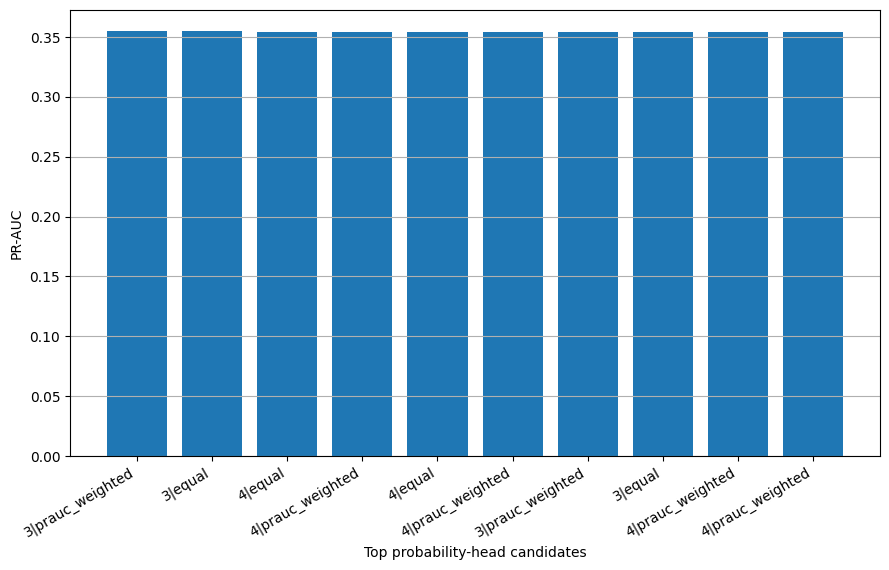

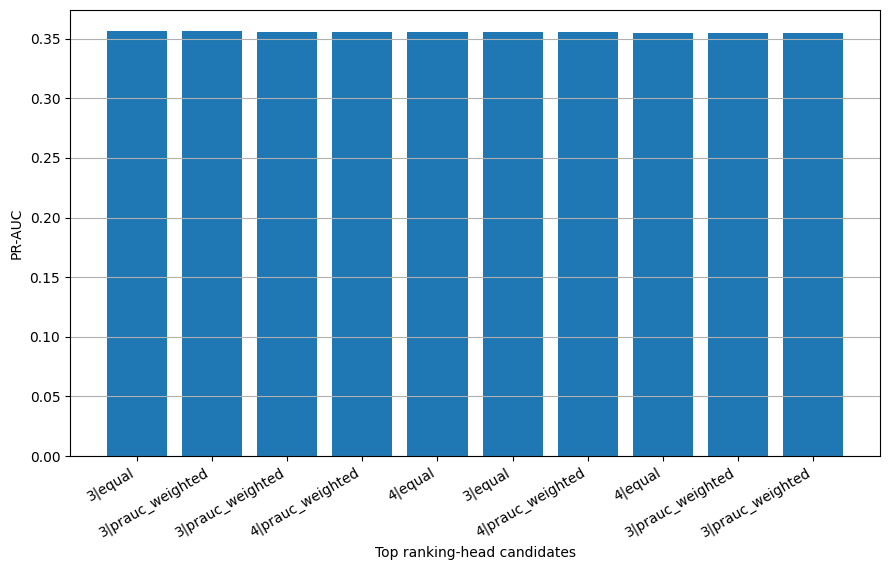


Module 6 complete.
Saved:
- single-model reference table
- all manual probability-head candidates
- all manual ranking-head candidates
- locked best raw probability head
- locked best raw ranking head

Next step: Module 7 — calibration of the locked probability head.


In [9]:
# ============================================================
# Module 6 — Ensemble Construction (manual shortlist)
#
# Purpose:
#   Build candidate probability and ranking heads from a
#   manually fixed shortlist of expert models.
#
# Manual shortlist:
#   - XGBoost_tuned
#   - CatBoost_tuned
#   - MLP
#   - DeepFM
#   - LogReg
#
# Heads:
#   1) Probability head  -> mean of probabilities
#   2) Ranking head      -> mean of percentile ranks
#
# Evaluation split:
#   calibration split only
#
# Output:
#   - all candidate probability heads
#   - all candidate ranking heads
#   - locked best raw probability head
#   - locked best raw ranking head
# ============================================================

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "PRED_DIR", "TAB_DIR", "FIG_DIR",
    "evaluate_probs", "clip_probs", "save_figure_multi"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 6: {missing_vars}")

# ============================================================
# 6.1 Load prediction files
# ============================================================

m1 = pd.read_csv(PRED_DIR / "module1_simple_baseline_predictions_cal.csv")
m3 = pd.read_csv(PRED_DIR / "module3_neural_cal_predictions.csv")
m4 = pd.read_csv(PRED_DIR / "module4_tuned_predictions_cal.csv")

if "y_cal" not in m1.columns or "y_cal" not in m3.columns or "y_cal" not in m4.columns:
    raise ValueError("One or more required calibration prediction files are missing 'y_cal'.")

y1 = m1["y_cal"].astype(int).values
y3 = m3["y_cal"].astype(int).values
y4 = m4["y_cal"].astype(int).values

if not (np.array_equal(y1, y3) and np.array_equal(y1, y4)):
    raise ValueError("y_cal mismatch across Module 1 / 3 / 4 prediction files.")

y_cal = y1.copy()

# ============================================================
# 6.2 Manually fixed shortlist
# ============================================================

manual_experts = {
    "LogReg": ("module1", "p_logreg_cal"),
    "MLP": ("module3", "p_MLP_cal"),
    "DeepFM": ("module3", "p_DeepFM_cal"),
    "XGBoost_tuned": ("module4", "p_xgb_tuned_cal"),
    "CatBoost_tuned": ("module4", "p_cat_tuned_cal"),
}

# collect prediction vectors
pred_sources = {
    "module1": m1,
    "module3": m3,
    "module4": m4,
}

expert_pred_dict = {}
for nice_name, (src_name, col_name) in manual_experts.items():
    src_df = pred_sources[src_name]
    if col_name not in src_df.columns:
        raise ValueError(f"Required column '{col_name}' not found in {src_name} predictions.")
    expert_pred_dict[nice_name] = clip_probs(src_df[col_name].values)

print("Manual experts:")
for k in expert_pred_dict.keys():
    print("-", k)

# ============================================================
# 6.3 Helpers
# ============================================================

def prob_average(pred_list, weights=None):
    """
    Weighted probability average.
    If weights=None -> equal-weight average.
    """
    arrs = [clip_probs(p) for p in pred_list]

    if weights is None:
        weights = np.ones(len(arrs), dtype=np.float32)
    else:
        weights = np.asarray(weights, dtype=np.float32)

    weights = weights / (weights.sum() + 1e-12)

    out = np.zeros_like(arrs[0], dtype=np.float32)
    for w, p in zip(weights, arrs):
        out += w * p
    return clip_probs(out)

def rank_percentile(p):
    """
    Convert scores to percentile-like ranks in (0,1).
    """
    p = np.asarray(p).reshape(-1)
    order = np.argsort(np.argsort(p))
    r = (order + 0.5) / len(p)
    return clip_probs(r.astype(np.float32))

def rank_average(pred_list, weights=None):
    """
    Weighted average of percentile ranks.
    """
    rank_list = [rank_percentile(p) for p in pred_list]

    if weights is None:
        weights = np.ones(len(rank_list), dtype=np.float32)
    else:
        weights = np.asarray(weights, dtype=np.float32)

    weights = weights / (weights.sum() + 1e-12)

    out = np.zeros_like(rank_list[0], dtype=np.float32)
    for w, r in zip(weights, rank_list):
        out += w * r
    return clip_probs(out)

def normalize_weights_from_prauc(model_names, model_perf_df):
    """
    Build simple performance-aware weights from calibration PR-AUC.
    """
    tmp = model_perf_df.set_index("model").loc[model_names, "PR_AUC"].values.astype(np.float32)
    tmp = np.maximum(tmp, 1e-6)
    return tmp / tmp.sum()

# ============================================================
# 6.4 Build single-model reference table
# ============================================================

single_rows = []
for model_name, preds in expert_pred_dict.items():
    row = evaluate_probs(y_cal, preds, name=model_name)
    single_rows.append(row)

module6_single_df = pd.DataFrame(single_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
    ascending=[False, False, True, True]
).reset_index(drop=True)

module6_single_df.to_csv(TAB_DIR / "module6_manual_shortlist_single_model_reference.csv", index=False)

print("\nSingle-model reference on calibration split:")
print(module6_single_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# 6.5 Candidate expert combinations
# Try 3-model and 4-model combinations
# ============================================================

expert_names = list(expert_pred_dict.keys())

expert_sets = []
expert_sets += list(itertools.combinations(expert_names, 3))
expert_sets += list(itertools.combinations(expert_names, 4))

print("\nTotal ensemble candidates:", len(expert_sets))

# ============================================================
# 6.6 Evaluate candidate heads
#
# We test:
#   - equal-weight probability head
#   - PR-AUC-weighted probability head
#   - equal-weight ranking head
#   - PR-AUC-weighted ranking head
# ============================================================

prob_rows = []
rank_rows = []

for experts in expert_sets:
    experts = list(experts)
    pred_list = [expert_pred_dict[e] for e in experts]
    w_prauc = normalize_weights_from_prauc(experts, module6_single_df)

    # ---- Probability head: equal weights
    p_prob_eq = prob_average(pred_list, weights=None)
    row = evaluate_probs(y_cal, p_prob_eq, name="ProbabilityHead_equal")
    row["experts"] = "|".join(experts)
    row["comb_size"] = len(experts)
    row["head_type"] = "probability"
    row["weighting"] = "equal"
    prob_rows.append(row)

    # ---- Probability head: PR-AUC-weighted
    p_prob_w = prob_average(pred_list, weights=w_prauc)
    row = evaluate_probs(y_cal, p_prob_w, name="ProbabilityHead_prauc_weighted")
    row["experts"] = "|".join(experts)
    row["comb_size"] = len(experts)
    row["head_type"] = "probability"
    row["weighting"] = "prauc_weighted"
    prob_rows.append(row)

    # ---- Ranking head: equal weights
    p_rank_eq = rank_average(pred_list, weights=None)
    row = evaluate_probs(y_cal, p_rank_eq, name="RankingHead_equal")
    row["experts"] = "|".join(experts)
    row["comb_size"] = len(experts)
    row["head_type"] = "ranking"
    row["weighting"] = "equal"
    rank_rows.append(row)

    # ---- Ranking head: PR-AUC-weighted
    p_rank_w = rank_average(pred_list, weights=w_prauc)
    row = evaluate_probs(y_cal, p_rank_w, name="RankingHead_prauc_weighted")
    row["experts"] = "|".join(experts)
    row["comb_size"] = len(experts)
    row["head_type"] = "ranking"
    row["weighting"] = "prauc_weighted"
    rank_rows.append(row)

module6_prob_df = pd.DataFrame(prob_rows).sort_values(
    ["PR_AUC", "ROC_AUC", "Brier", "ECE"],
    ascending=[False, False, True, True]
).reset_index(drop=True)

module6_rank_df = pd.DataFrame(rank_rows).sort_values(
    ["PR_AUC", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

module6_prob_df.to_csv(TAB_DIR / "module6_manual_probability_head_results.csv", index=False)
module6_rank_df.to_csv(TAB_DIR / "module6_manual_ranking_head_results.csv", index=False)

print("\nTop probability-head candidates:")
print(module6_prob_df.head(10)[["model", "experts", "comb_size", "weighting", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nTop ranking-head candidates:")
print(module6_rank_df.head(10)[["model", "experts", "comb_size", "weighting", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# 6.7 Lock best raw heads
#
# Probability head:
#   prioritize PR_AUC / ROC_AUC but keep Brier/ECE visible
#
# Ranking head:
#   prioritize PR_AUC / ROC_AUC only
# ============================================================

best_prob_row = module6_prob_df.iloc[0].copy()
best_rank_row = module6_rank_df.iloc[0].copy()

print("\nLocked best raw probability head:")
print(best_prob_row[["model", "experts", "comb_size", "weighting", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nLocked best raw ranking head:")
print(best_rank_row[["model", "experts", "comb_size", "weighting", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# 6.8 Rebuild locked raw head predictions
# ============================================================

def build_head_prediction(expert_names_list, head_type, weighting, single_df):
    pred_list = [expert_pred_dict[e] for e in expert_names_list]

    if weighting == "equal":
        weights = None
    elif weighting == "prauc_weighted":
        weights = normalize_weights_from_prauc(expert_names_list, single_df)
    else:
        raise ValueError(f"Unknown weighting type: {weighting}")

    if head_type == "probability":
        return prob_average(pred_list, weights=weights)
    elif head_type == "ranking":
        return rank_average(pred_list, weights=weights)
    else:
        raise ValueError(f"Unknown head type: {head_type}")

best_prob_experts = best_prob_row["experts"].split("|")
best_rank_experts = best_rank_row["experts"].split("|")

p_prob_raw_locked = build_head_prediction(
    expert_names_list=best_prob_experts,
    head_type="probability",
    weighting=best_prob_row["weighting"],
    single_df=module6_single_df,
)

p_rank_raw_locked = build_head_prediction(
    expert_names_list=best_rank_experts,
    head_type="ranking",
    weighting=best_rank_row["weighting"],
    single_df=module6_single_df,
)

# ============================================================
# 6.9 Save locked head predictions
# ============================================================

module6_locked_preds_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_prob_raw_locked": p_prob_raw_locked,
    "p_rank_raw_locked": p_rank_raw_locked,
})

# also save component experts used in the locked heads
for e in sorted(set(best_prob_experts + best_rank_experts)):
    safe_col = f"expert_{e}"
    module6_locked_preds_df[safe_col] = expert_pred_dict[e]

module6_locked_preds_df.to_csv(PRED_DIR / "module6_locked_raw_heads_predictions_cal.csv", index=False)

# metadata
module6_locked_meta_df = pd.DataFrame([
    {
        "locked_object": "raw_probability_head",
        "model_name": best_prob_row["model"],
        "experts": best_prob_row["experts"],
        "comb_size": int(best_prob_row["comb_size"]),
        "weighting": best_prob_row["weighting"],
        "PR_AUC": float(best_prob_row["PR_AUC"]),
        "ROC_AUC": float(best_prob_row["ROC_AUC"]),
        "Brier": float(best_prob_row["Brier"]),
        "ECE": float(best_prob_row["ECE"]),
    },
    {
        "locked_object": "raw_ranking_head",
        "model_name": best_rank_row["model"],
        "experts": best_rank_row["experts"],
        "comb_size": int(best_rank_row["comb_size"]),
        "weighting": best_rank_row["weighting"],
        "PR_AUC": float(best_rank_row["PR_AUC"]),
        "ROC_AUC": float(best_rank_row["ROC_AUC"]),
        "Brier": float(best_rank_row["Brier"]),
        "ECE": float(best_rank_row["ECE"]),
    },
])
module6_locked_meta_df.to_csv(TAB_DIR / "module6_locked_raw_heads_metadata.csv", index=False)

# ============================================================
# 6.10 Figures
# ============================================================

plt.figure(figsize=(9.0, 5.8))
tmp = module6_prob_df.head(10).copy()
labels = [f"{r['comb_size']}|{r['weighting']}" for _, r in tmp.iterrows()]
plt.bar(range(len(tmp)), tmp["PR_AUC"].values)
plt.xticks(range(len(tmp)), labels, rotation=30, ha="right")
plt.ylabel("PR-AUC")
plt.xlabel("Top probability-head candidates")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module6_top_probability_heads_prauc")
plt.show()

plt.figure(figsize=(9.0, 5.8))
tmp = module6_rank_df.head(10).copy()
labels = [f"{r['comb_size']}|{r['weighting']}" for _, r in tmp.iterrows()]
plt.bar(range(len(tmp)), tmp["PR_AUC"].values)
plt.xticks(range(len(tmp)), labels, rotation=30, ha="right")
plt.ylabel("PR-AUC")
plt.xlabel("Top ranking-head candidates")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module6_top_ranking_heads_prauc")
plt.show()

# ============================================================
# 6.11 Export convenient variables for Module 7
# ============================================================

module6_manual_prob_results_df = module6_prob_df.copy()
module6_manual_rank_results_df = module6_rank_df.copy()

p_prob_raw_cal = p_prob_raw_locked.copy()
p_rank_raw_cal = p_rank_raw_locked.copy()

print("\nModule 6 complete.")
print("Saved:")
print("- single-model reference table")
print("- all manual probability-head candidates")
print("- all manual ranking-head candidates")
print("- locked best raw probability head")
print("- locked best raw ranking head")
print("\nNext step: Module 7 — calibration of the locked probability head.")

In [10]:
# ============================================================
# Module 7 — Calibration of Probability Heads
#
# Purpose
#   Compare raw vs calibrated probability models and
#   select the final deployment probability head.
#
# Calibration methods:
#   1. Logistic (Platt scaling)
#   2. Isotonic regression
#
# Candidates evaluated:
#   - XGBoost_tuned
#   - CatBoost_tuned
#   - ProbabilityHead_equal
#   - ProbabilityHead_prauc_weighted
#
# Selection criteria (priority order):
#   1) Brier score
#   2) NLL
#   3) ECE
#
# Output:
#   - calibration comparison table
#   - final probability head
# ============================================================

import pandas as pd
import numpy as np
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# Load calibration predictions from previous modules
# ------------------------------------------------------------

m3 = pd.read_csv(PRED_DIR / "module3_neural_cal_predictions.csv")
m4 = pd.read_csv(PRED_DIR / "module4_tuned_predictions_cal.csv")
m6 = pd.read_csv(PRED_DIR / "module6_locked_raw_heads_predictions_cal.csv")

y_cal = m4["y_cal"].values

# ------------------------------------------------------------
# Candidate probability models
# ------------------------------------------------------------

candidate_models = {
    
    "XGBoost_tuned":
        clip_probs(m4["p_xgb_tuned_cal"].values),

    "CatBoost_tuned":
        clip_probs(m4["p_cat_tuned_cal"].values),

    "ProbHead_equal":
        clip_probs(m6["p_prob_raw_locked"].values),

}

print("Calibration candidates:")
for k in candidate_models:
    print("-", k)

# ------------------------------------------------------------
# Calibration functions
# ------------------------------------------------------------

def platt_calibration(p, y):

    lr = LogisticRegression(solver="lbfgs")

    lr.fit(p.reshape(-1,1), y)

    calibrated = lr.predict_proba(p.reshape(-1,1))[:,1]

    return clip_probs(calibrated)


def isotonic_calibration(p, y):

    iso = IsotonicRegression(out_of_bounds="clip")

    iso.fit(p, y)

    calibrated = iso.predict(p)

    return clip_probs(calibrated)

# ------------------------------------------------------------
# Evaluate raw + calibrated versions
# ------------------------------------------------------------

rows = []

for model_name, p_raw in candidate_models.items():

    # Raw
    r = evaluate_probs(y_cal, p_raw, name=f"{model_name}_raw")
    r["base_model"] = model_name
    r["calibration"] = "none"
    rows.append(r)

    # Logistic calibration
    p_log = platt_calibration(p_raw, y_cal)

    r = evaluate_probs(y_cal, p_log, name=f"{model_name}_logistic")
    r["base_model"] = model_name
    r["calibration"] = "logistic"
    rows.append(r)

    # Isotonic calibration
    p_iso = isotonic_calibration(p_raw, y_cal)

    r = evaluate_probs(y_cal, p_iso, name=f"{model_name}_isotonic")
    r["base_model"] = model_name
    r["calibration"] = "isotonic"
    rows.append(r)

# ------------------------------------------------------------
# Build comparison table
# ------------------------------------------------------------

module7_df = pd.DataFrame(rows)

module7_df = module7_df.sort_values(
    ["Brier", "NLL", "ECE"],
    ascending=[True, True, True]
).reset_index(drop=True)

module7_df.to_csv(
    TAB_DIR / "module7_probability_calibration_results.csv",
    index=False
)

print("\nCalibration comparison:")
print(module7_df[
    ["model","base_model","calibration","PR_AUC","ROC_AUC","Brier","NLL","ECE"]
])

# ------------------------------------------------------------
# Select final probability head
# ------------------------------------------------------------

best_row = module7_df.iloc[0]

print("\nFinal selected probability head:")
print(best_row)

# ------------------------------------------------------------
# Save final predictions
# ------------------------------------------------------------

final_model = best_row["base_model"]
cal_type = best_row["calibration"]

p_base = candidate_models[final_model]

if cal_type == "none":
    p_final = p_base

elif cal_type == "logistic":
    p_final = platt_calibration(p_base, y_cal)

elif cal_type == "isotonic":
    p_final = isotonic_calibration(p_base, y_cal)

else:
    raise ValueError("Unknown calibration type")

final_df = pd.DataFrame({
    "y_cal": y_cal,
    "p_final_probability": p_final
})

final_df.to_csv(
    PRED_DIR / "module7_final_probability_head_predictions_cal.csv",
    index=False
)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------

meta = pd.DataFrame([{
    "final_probability_model": best_row["model"],
    "base_model": best_row["base_model"],
    "calibration": best_row["calibration"],
    "PR_AUC": best_row["PR_AUC"],
    "ROC_AUC": best_row["ROC_AUC"],
    "Brier": best_row["Brier"],
    "NLL": best_row["NLL"],
    "ECE": best_row["ECE"]
}])

meta.to_csv(
    TAB_DIR / "module7_final_probability_head_metadata.csv",
    index=False
)

print("\nModule 7 complete.")
print("Final probability head locked.")

Calibration candidates:
- XGBoost_tuned
- CatBoost_tuned
- ProbHead_equal

Calibration comparison:
                     model      base_model calibration    PR_AUC   ROC_AUC  \
0  ProbHead_equal_isotonic  ProbHead_equal    isotonic  0.348058  0.845660   
1  CatBoost_tuned_isotonic  CatBoost_tuned    isotonic  0.348307  0.845446   
2   XGBoost_tuned_isotonic   XGBoost_tuned    isotonic  0.347606  0.844701   
3  ProbHead_equal_logistic  ProbHead_equal    logistic  0.354860  0.843930   
4  CatBoost_tuned_logistic  CatBoost_tuned    logistic  0.355689  0.843966   
5   XGBoost_tuned_logistic   XGBoost_tuned    logistic  0.356230  0.842946   
6       ProbHead_equal_raw  ProbHead_equal        none  0.354860  0.843930   
7        XGBoost_tuned_raw   XGBoost_tuned        none  0.356230  0.842946   
8       CatBoost_tuned_raw  CatBoost_tuned        none  0.355689  0.843966   

      Brier       NLL           ECE  
0  0.064637  0.223168  1.791075e-08  
1  0.064662  0.223251  4.655332e-08  
2  0.0

In [14]:
# ============================================================
# Module 7.5B — Generate TEST predictions for final locked heads
#
# Needed experts:
#   - MLP
#   - XGBoost_tuned
#   - CatBoost_tuned
#
# Assumes these variables already exist from earlier modules:
#   Xtr_ml, Xva_ml, Xte_ml
#   X_train_sub, X_val_sub, X_test
#   y_train_sub, y_val_sub, y_test
#   CONT_COLS, ORDINAL_COLS, BINARY_COLS, NOMINAL_COLS
#   PRED_DIR, MOD_DIR, SEED, clip_probs
# ============================================================

import os
import gc
import json
import random
import numpy as np
import pandas as pd

import xgboost as xgb
from catboost import CatBoostClassifier

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "Xtr_ml", "Xva_ml", "Xte_ml",
    "X_train_sub", "X_val_sub", "X_test",
    "y_train_sub", "y_val_sub", "y_test",
    "CONT_COLS", "ORDINAL_COLS", "BINARY_COLS", "NOMINAL_COLS",
    "PRED_DIR", "MOD_DIR", "SEED", "clip_probs"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 7.5B: {missing_vars}")

# -------------------------
# Reproducibility
# -------------------------
def seed_everything_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# Load saved best configs
# ============================================================

with open(MOD_DIR / "module4_best_xgb_config.json", "r") as f:
    best_xgb_cfg = json.load(f)

with open(MOD_DIR / "module4_best_cat_config.json", "r") as f:
    best_cat_cfg = json.load(f)

# MLP baseline was selected, not MLP_tuned.
# So we use the original Module 3 baseline architecture/settings.
# ============================================================
# MLP baseline model
# ============================================================

class TabDataset(Dataset):
    def __init__(self, X_df, y):
        self.X = torch.tensor(X_df.values, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class MLPBaseline(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.net(x)

@torch.no_grad()
def predict_torch_model(model, X_df, batch_size=4096, device="cpu"):
    model = model.to(device)
    model.eval()

    ds = torch.tensor(X_df.values, dtype=torch.float32)
    preds = []

    for i in range(0, len(ds), batch_size):
        xb = ds[i:i + batch_size].to(device)
        logits = model(xb).squeeze(-1)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        preds.append(p)

    return clip_probs(np.concatenate(preds))

def train_mlp_baseline(X_train_df, y_train, X_val_df, y_val,
                       lr=1e-3, batch_size=2048, max_epochs=40, patience=6):

    train_ds = TabDataset(X_train_df, y_train.astype(np.float32))
    val_ds = TabDataset(X_val_df, y_val.astype(np.float32))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=(device == "cuda"))
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device == "cuda"))

    model = MLPBaseline(input_dim=X_train_df.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    best_val = 1e18
    best_state = None
    bad_epochs = 0

    for ep in range(1, max_epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            opt.zero_grad(set_to_none=True)
            logits = model(xb).squeeze(-1)
            loss = F.binary_cross_entropy_with_logits(logits, yb)
            loss.backward()
            opt.step()

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)
                logits = model(xb).squeeze(-1)
                vloss = F.binary_cross_entropy_with_logits(logits, yb)
                val_losses.append(float(vloss.item()))

        mean_val = float(np.mean(val_losses))
        if mean_val < best_val - 1e-6:
            best_val = mean_val
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model

# ============================================================
# Train / predict MLP baseline
# ============================================================

print("Training MLP baseline for TEST prediction...")
mlp_model = train_mlp_baseline(
    X_train_df=Xtr_ml,
    y_train=y_train_sub,
    X_val_df=Xva_ml,
    y_val=y_val_sub,
    lr=1e-3,
    batch_size=2048,
    max_epochs=40,
    patience=6,
)

p_mlp_test = predict_torch_model(mlp_model, Xte_ml, batch_size=4096, device=device)

# ============================================================
# Train / predict XGBoost_tuned
# ============================================================

print("Training XGBoost_tuned for TEST prediction...")

xgb_params = best_xgb_cfg["params"]
xgb_best_iter = int(best_xgb_cfg["best_iteration"])

dtr_xgb = xgb.DMatrix(Xtr_ml.values, label=y_train_sub.astype(int), feature_names=list(Xtr_ml.columns))
dva_xgb = xgb.DMatrix(Xva_ml.values, label=y_val_sub.astype(int), feature_names=list(Xtr_ml.columns))
dte_xgb = xgb.DMatrix(Xte_ml.values, feature_names=list(Xtr_ml.columns))

xgb_model = xgb.train(
    params=xgb_params,
    dtrain=dtr_xgb,
    num_boost_round=max(xgb_best_iter, 1),
    evals=[(dva_xgb, "valid")],
    verbose_eval=False
)

p_xgb_test = clip_probs(xgb_model.predict(dte_xgb, iteration_range=(0, xgb_best_iter)))

# ============================================================
# Train / predict CatBoost_tuned
# ============================================================

print("Training CatBoost_tuned for TEST prediction...")

Xtr_cat = X_train_sub.copy()
Xva_cat = X_val_sub.copy()
Xte_cat = X_test.copy()

for c in CONT_COLS + ORDINAL_COLS + BINARY_COLS:
    Xtr_cat[c] = pd.to_numeric(Xtr_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xva_cat[c] = pd.to_numeric(Xva_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xte_cat[c] = pd.to_numeric(Xte_cat[c], errors="coerce").fillna(Xtr_cat[c].median())

for c in NOMINAL_COLS:
    Xtr_cat[c] = Xtr_cat[c].astype(str).fillna("Other")
    Xva_cat[c] = Xva_cat[c].astype(str).fillna("Other")
    Xte_cat[c] = Xte_cat[c].astype(str).fillna("Other")

cat_feature_indices = [Xtr_cat.columns.get_loc(c) for c in NOMINAL_COLS]

cat_params = best_cat_cfg["params"]

cat_model = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=SEED,
    verbose=False,
    **cat_params
)

cat_model.fit(
    Xtr_cat,
    y_train_sub.astype(int),
    cat_features=cat_feature_indices,
    eval_set=(Xva_cat, y_val_sub.astype(int)),
    use_best_model=True,
    verbose=False
)

p_cat_test = clip_probs(cat_model.predict_proba(Xte_cat)[:, 1])

# ============================================================
# Save consolidated TEST predictions
# ============================================================

module75b_test_df = pd.DataFrame({
    "y_test": y_test.astype(int),
    "p_MLP_test": p_mlp_test,
    "p_xgb_tuned_test": p_xgb_test,
    "p_cat_tuned_test": p_cat_test,
})

module75b_test_df.to_csv(PRED_DIR / "module7_test_predictions.csv", index=False)

print("\nModule 7.5B complete.")
print("Saved:", PRED_DIR / "module7_test_predictions.csv")
print(module75b_test_df.head())

Training MLP baseline for TEST prediction...
Training XGBoost_tuned for TEST prediction...
Training CatBoost_tuned for TEST prediction...

Module 7.5B complete.
Saved: /kaggle/working/outputs_heart2020_exp/predictions/module7_test_predictions.csv
   y_test  p_MLP_test  p_xgb_tuned_test  p_cat_tuned_test
0       0    0.120132          0.530419          0.553857
1       0    0.058118          0.493892          0.509492
2       0    0.014700          0.112300          0.104772
3       0    0.325835          0.839086          0.827771
4       0    0.012855          0.088085          0.094345



Final TEST performance:
                   model    PR_AUC   ROC_AUC     Brier       NLL       ECE  \
0      RankingHead_final  0.353479  0.840851  0.279590  0.820762  0.414398   
1  ProbabilityHead_final  0.339575  0.840516  0.065487  0.226774  0.004456   

   Prec@bestF1  Rec@bestF1  F1@bestF1  MCC@bestF1  
0     0.310341    0.554703   0.398008    0.341414  
1     0.308613    0.555616   0.396817    0.340239  


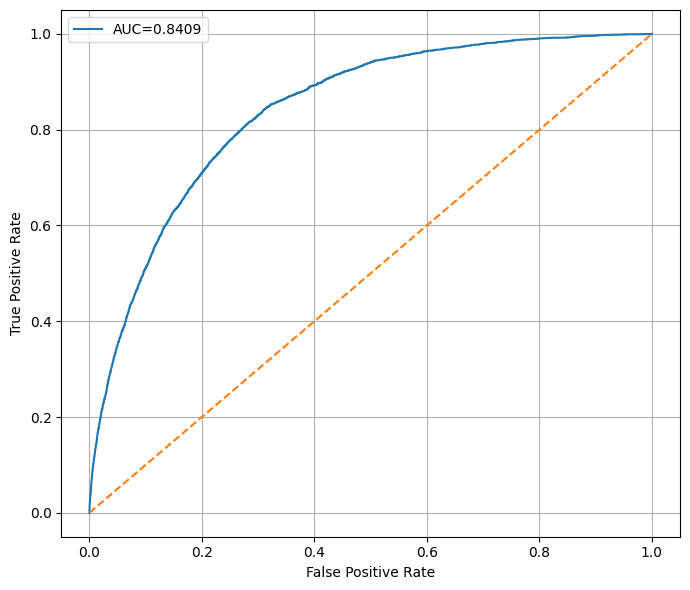

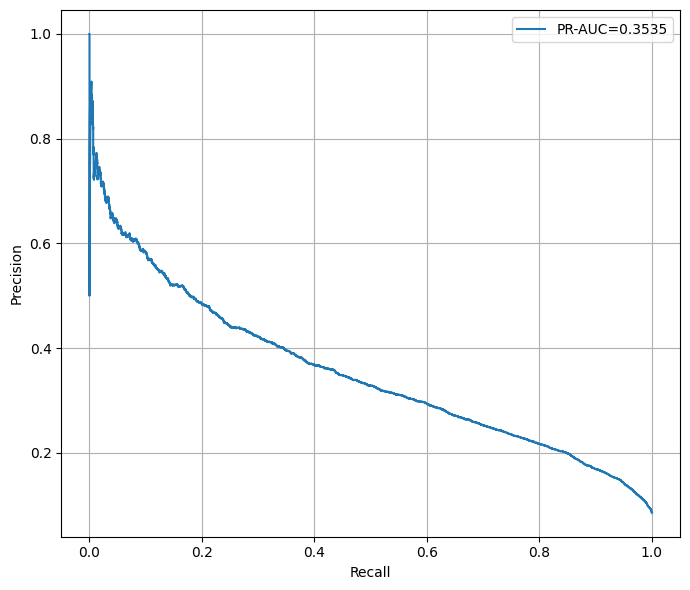

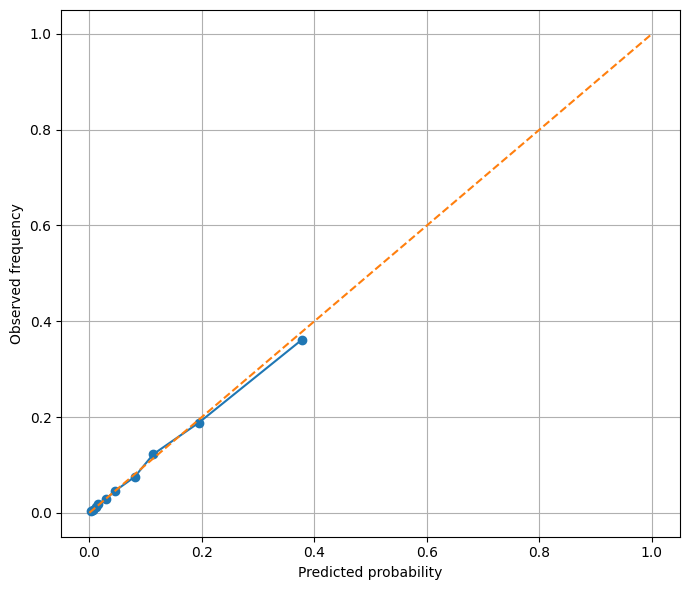


Module 8 complete.
Saved final test results, prediction bundle, ROC/PR/calibration curves, and threshold analysis.


In [16]:
# ============================================================
# Module 8 — Final TEST Evaluation (corrected)
#
# Evaluates:
#   - final screening head
#   - final probability head
#
# Inputs:
#   - module7_test_predictions.csv
#   - module7_final_probability_head_metadata.csv
#   - module6_locked_raw_heads_predictions_cal.csv
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
)

from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Load TEST predictions
# ------------------------------------------------------------

test_preds = pd.read_csv(PRED_DIR / "module7_test_predictions.csv")

if "y_test" not in test_preds.columns:
    raise ValueError("module7_test_predictions.csv must contain 'y_test'.")

required_test_cols = ["p_MLP_test", "p_xgb_tuned_test", "p_cat_tuned_test"]
missing_test_cols = [c for c in required_test_cols if c not in test_preds.columns]
if len(missing_test_cols) > 0:
    raise ValueError(f"Missing required TEST prediction columns: {missing_test_cols}")

y_test = test_preds["y_test"].astype(int).values
p_mlp = clip_probs(test_preds["p_MLP_test"].values)
p_xgb = clip_probs(test_preds["p_xgb_tuned_test"].values)
p_cat = clip_probs(test_preds["p_cat_tuned_test"].values)

# ------------------------------------------------------------
# Rebuild locked ranking head on TEST
# Locked from Module 6:
#   MLP + XGBoost_tuned + CatBoost_tuned
#   equal-weight rank averaging
# ------------------------------------------------------------

def rank_percentile(p):
    p = np.asarray(p).reshape(-1)
    order = np.argsort(np.argsort(p))
    r = (order + 0.5) / len(p)
    return clip_probs(r.astype(np.float32))

def ranking_head(preds):
    ranks = [rank_percentile(p) for p in preds]
    return clip_probs(np.mean(np.vstack(ranks), axis=0))

p_rank_test = ranking_head([p_mlp, p_xgb, p_cat])

# ------------------------------------------------------------
# Rebuild raw probability head on TEST
# Module 7 selected ProbHead_equal_isotonic
# so the raw base is equal average of:
#   MLP + XGBoost_tuned + CatBoost_tuned
# ------------------------------------------------------------

p_prob_raw_test = clip_probs((p_mlp + p_xgb + p_cat) / 3.0)

# ------------------------------------------------------------
# Apply final calibration learned on CAL
# ------------------------------------------------------------

cal_meta = pd.read_csv(TAB_DIR / "module7_final_probability_head_metadata.csv")

if len(cal_meta) == 0:
    raise ValueError("module7_final_probability_head_metadata.csv is empty.")

final_base_model = cal_meta.loc[0, "base_model"]
final_calibration = cal_meta.loc[0, "calibration"]

if final_base_model != "ProbHead_equal":
    raise ValueError(
        f"This Module 8 expects final base_model='ProbHead_equal', "
        f"but found '{final_base_model}'. Please update Module 8 accordingly."
    )

cal_preds = pd.read_csv(PRED_DIR / "module6_locked_raw_heads_predictions_cal.csv")
if "y_cal" not in cal_preds.columns or "p_prob_raw_locked" not in cal_preds.columns:
    raise ValueError("module6_locked_raw_heads_predictions_cal.csv must contain y_cal and p_prob_raw_locked.")

y_cal = cal_preds["y_cal"].astype(int).values
p_prob_raw_cal = clip_probs(cal_preds["p_prob_raw_locked"].values)

if final_calibration == "none":
    p_prob_test = p_prob_raw_test.copy()

elif final_calibration == "isotonic":
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(p_prob_raw_cal, y_cal)
    p_prob_test = clip_probs(iso.predict(p_prob_raw_test))

else:
    raise ValueError(
        f"This Module 8 currently supports final calibration 'none' or 'isotonic'. "
        f"Found '{final_calibration}'."
    )

# ------------------------------------------------------------
# Final performance metrics
# ------------------------------------------------------------

rank_metrics = evaluate_probs(
    y_test,
    p_rank_test,
    name="RankingHead_final"
)

prob_metrics = evaluate_probs(
    y_test,
    p_prob_test,
    name="ProbabilityHead_final"
)

module8_final_results_df = pd.DataFrame([
    rank_metrics,
    prob_metrics,
])

module8_final_results_df.to_csv(
    TAB_DIR / "module8_final_test_results.csv",
    index=False
)

print("\nFinal TEST performance:")
print(module8_final_results_df[[
    "model", "PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE",
    "Prec@bestF1", "Rec@bestF1", "F1@bestF1", "MCC@bestF1"
]])

# ------------------------------------------------------------
# Save final prediction bundle
# ------------------------------------------------------------

module8_test_preds_df = pd.DataFrame({
    "y_test": y_test.astype(int),
    "p_MLP_test": p_mlp,
    "p_xgb_tuned_test": p_xgb,
    "p_cat_tuned_test": p_cat,
    "p_rank_final": p_rank_test,
    "p_prob_raw_test": p_prob_raw_test,
    "p_prob_final": p_prob_test,
})
module8_test_preds_df.to_csv(
    PRED_DIR / "module8_final_test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# ROC curve (screening head)
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(y_test, p_rank_test)

plt.figure(figsize=(7.0, 6.0))
plt.plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, p_rank_test):.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True)
plt.legend()
save_figure_multi(FIG_DIR / "module8_final_roc_curve")
plt.show()

# ------------------------------------------------------------
# PR curve (screening head)
# ------------------------------------------------------------

precision, recall, _ = precision_recall_curve(y_test, p_rank_test)

plt.figure(figsize=(7.0, 6.0))
plt.plot(recall, precision, label=f"PR-AUC={average_precision_score(y_test, p_rank_test):.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True)
plt.legend()
save_figure_multi(FIG_DIR / "module8_final_pr_curve")
plt.show()

# ------------------------------------------------------------
# Calibration curve (probability head)
# ------------------------------------------------------------

def calibration_curve_plot(y, p, bins=10):
    df = pd.DataFrame({"y": y, "p": p})
    df["bin"] = pd.qcut(df["p"], q=bins, duplicates="drop")
    grp = df.groupby("bin", observed=False)
    mean_pred = grp["p"].mean().values
    frac_pos = grp["y"].mean().values
    return mean_pred, frac_pos

mp, fp = calibration_curve_plot(y_test, p_prob_test, bins=10)

plt.figure(figsize=(7.0, 6.0))
plt.plot(mp, fp, marker="o")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.grid(True)
save_figure_multi(FIG_DIR / "module8_final_calibration_curve")
plt.show()

# ------------------------------------------------------------
# Threshold analysis for probability head
# ------------------------------------------------------------

thresholds = np.linspace(0.05, 0.50, 20)
rows = []

for t in thresholds:
    pred = (p_prob_test >= t).astype(int)

    TP = int(np.sum((pred == 1) & (y_test == 1)))
    FP = int(np.sum((pred == 1) & (y_test == 0)))
    TN = int(np.sum((pred == 0) & (y_test == 0)))
    FN = int(np.sum((pred == 0) & (y_test == 1)))

    precision_t = TP / (TP + FP + 1e-12)
    recall_t = TP / (TP + FN + 1e-12)

    rows.append({
        "threshold": float(t),
        "precision": float(precision_t),
        "recall": float(recall_t),
        "TP": TP,
        "FP": FP,
        "TN": TN,
        "FN": FN
    })

module8_threshold_df = pd.DataFrame(rows)
module8_threshold_df.to_csv(
    TAB_DIR / "module8_threshold_analysis.csv",
    index=False
)

print("\nModule 8 complete.")
print("Saved final test results, prediction bundle, ROC/PR/calibration curves, and threshold analysis.")

In [18]:
# ============================================================
# Module 9 — Imbalance-aware boosting models (corrected)
# Purpose:
#   Try a simple imbalance-focused boosting experiment using
#   stronger class weighting and aucpr-oriented evaluation.
#
# Training:
#   train_sub
#
# Early stopping:
#   val_sub
#
# Evaluation:
#   val_sub
#   cal
# ============================================================

print("\n==============================")
print("Module 9 — Imbalance-aware boosting")
print("==============================")

import numpy as np
import pandas as pd
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "Xtr_ml", "Xva_ml", "Xcal_ml",
    "X_train_sub", "X_val_sub", "X_cal",
    "y_train_sub", "y_val_sub", "y_cal",
    "CONT_COLS", "ORDINAL_COLS", "BINARY_COLS", "NOMINAL_COLS",
    "SEED", "TAB_DIR", "PRED_DIR",
    "evaluate_probs", "clip_probs"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 9: {missing_vars}")

module9_val_rows = []
module9_cal_rows = []

# ------------------------------------------------------------
# Compute imbalance weight
# ------------------------------------------------------------
n_pos = int((y_train_sub == 1).sum())
n_neg = int((y_train_sub == 0).sum())
scale_pos_weight = n_neg / max(n_pos, 1)

print("scale_pos_weight:", round(scale_pos_weight, 4))

# ============================================================
# 9.1 XGBoost imbalance-aware
# ============================================================

print("\n[Module 9] Training XGBoost_imbalance ...")

dtr_xgb = xgb.DMatrix(Xtr_ml.values, label=y_train_sub.astype(int), feature_names=list(Xtr_ml.columns))
dva_xgb = xgb.DMatrix(Xva_ml.values, label=y_val_sub.astype(int), feature_names=list(Xtr_ml.columns))
dcal_xgb = xgb.DMatrix(Xcal_ml.values, feature_names=list(Xtr_ml.columns))

xgb_params_imb = dict(
    objective="binary:logistic",
    eval_metric="aucpr",
    eta=0.05,
    max_depth=6,
    min_child_weight=20,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_lambda=10.0,
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    seed=SEED,
)

xgb_model_imb = xgb.train(
    params=xgb_params_imb,
    dtrain=dtr_xgb,
    num_boost_round=2000,
    evals=[(dva_xgb, "valid")],
    early_stopping_rounds=100,
    verbose_eval=False,
)

xgb_best_iter_imb = xgb_model_imb.best_iteration + 1 if xgb_model_imb.best_iteration is not None else 2000

p_xgb_imb_val = clip_probs(xgb_model_imb.predict(dva_xgb, iteration_range=(0, xgb_best_iter_imb)))
p_xgb_imb_cal = clip_probs(xgb_model_imb.predict(dcal_xgb, iteration_range=(0, xgb_best_iter_imb)))

module9_val_rows.append(evaluate_probs(y_val_sub, p_xgb_imb_val, name="XGBoost_imbalance"))
module9_cal_rows.append(evaluate_probs(y_cal, p_xgb_imb_cal, name="XGBoost_imbalance"))

# ============================================================
# 9.2 LightGBM imbalance-aware
# ============================================================

print("[Module 9] Training LightGBM_imbalance ...")

dtr_lgb = lgb.Dataset(Xtr_ml, label=y_train_sub.astype(int), feature_name=list(Xtr_ml.columns))
dva_lgb = lgb.Dataset(Xva_ml, label=y_val_sub.astype(int), feature_name=list(Xtr_ml.columns), reference=dtr_lgb)

lgb_params_imb = dict(
    objective="binary",
    boosting_type="gbdt",
    metric="auc",
    learning_rate=0.05,
    num_leaves=64,
    min_data_in_leaf=150,
    feature_fraction=0.80,
    bagging_fraction=0.80,
    bagging_freq=1,
    lambda_l2=10.0,
    scale_pos_weight=scale_pos_weight,
    feature_pre_filter=False,
    verbosity=-1,
    seed=SEED,
)

lgb_model_imb = lgb.train(
    params=lgb_params_imb,
    train_set=dtr_lgb,
    num_boost_round=3000,
    valid_sets=[dva_lgb],
    callbacks=[lgb.early_stopping(100, verbose=False)]
)

lgb_best_iter_imb = lgb_model_imb.best_iteration

p_lgb_imb_val = clip_probs(lgb_model_imb.predict(Xva_ml, num_iteration=lgb_best_iter_imb))
p_lgb_imb_cal = clip_probs(lgb_model_imb.predict(Xcal_ml, num_iteration=lgb_best_iter_imb))

module9_val_rows.append(evaluate_probs(y_val_sub, p_lgb_imb_val, name="LightGBM_imbalance"))
module9_cal_rows.append(evaluate_probs(y_cal, p_lgb_imb_cal, name="LightGBM_imbalance"))

# ============================================================
# 9.3 CatBoost imbalance-aware
# ============================================================

print("[Module 9] Training CatBoost_imbalance ...")

Xtr_cat = X_train_sub.copy()
Xva_cat = X_val_sub.copy()
Xcal_cat = X_cal.copy()

for c in CONT_COLS + ORDINAL_COLS + BINARY_COLS:
    Xtr_cat[c] = pd.to_numeric(Xtr_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xva_cat[c] = pd.to_numeric(Xva_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
    Xcal_cat[c] = pd.to_numeric(Xcal_cat[c], errors="coerce").fillna(Xtr_cat[c].median())

for c in NOMINAL_COLS:
    Xtr_cat[c] = Xtr_cat[c].astype(str).fillna("Other")
    Xva_cat[c] = Xva_cat[c].astype(str).fillna("Other")
    Xcal_cat[c] = Xcal_cat[c].astype(str).fillna("Other")

cat_feature_indices = [Xtr_cat.columns.get_loc(c) for c in NOMINAL_COLS]

cat_model_imb = CatBoostClassifier(
    iterations=2000,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    class_weights=[1.0, float(scale_pos_weight)],
    random_seed=SEED,
    verbose=False,
)

cat_model_imb.fit(
    Xtr_cat,
    y_train_sub.astype(int),
    cat_features=cat_feature_indices,
    eval_set=(Xva_cat, y_val_sub.astype(int)),
    use_best_model=True,
    early_stopping_rounds=100,
    verbose=False
)

p_cat_imb_val = clip_probs(cat_model_imb.predict_proba(Xva_cat)[:, 1])
p_cat_imb_cal = clip_probs(cat_model_imb.predict_proba(Xcal_cat)[:, 1])

module9_val_rows.append(evaluate_probs(y_val_sub, p_cat_imb_val, name="CatBoost_imbalance"))
module9_cal_rows.append(evaluate_probs(y_cal, p_cat_imb_cal, name="CatBoost_imbalance"))

# ============================================================
# 9.4 Results tables
# ============================================================

module9_val_df = pd.DataFrame(module9_val_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module9_cal_df = pd.DataFrame(module9_cal_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module9_val_df.to_csv(TAB_DIR / "module9_imbalance_boosting_val.csv", index=False)
module9_cal_df.to_csv(TAB_DIR / "module9_imbalance_boosting_cal.csv", index=False)

print("\nModule 9 validation results:")
print(module9_val_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 9 calibration results:")
print(module9_cal_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# 9.5 Save predictions
# ============================================================

module9_val_pred_df = pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_xgb_imb_val": p_xgb_imb_val,
    "p_lgb_imb_val": p_lgb_imb_val,
    "p_cat_imb_val": p_cat_imb_val,
})

module9_cal_pred_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_xgb_imb_cal": p_xgb_imb_cal,
    "p_lgb_imb_cal": p_lgb_imb_cal,
    "p_cat_imb_cal": p_cat_imb_cal,
})

module9_val_pred_df.to_csv(PRED_DIR / "module9_imbalance_boosting_predictions_val.csv", index=False)
module9_cal_pred_df.to_csv(PRED_DIR / "module9_imbalance_boosting_predictions_cal.csv", index=False)

print("\nModule 9 complete.")


Module 9 — Imbalance-aware boosting
scale_pos_weight: 10.6827

[Module 9] Training XGBoost_imbalance ...
[Module 9] Training LightGBM_imbalance ...
[Module 9] Training CatBoost_imbalance ...

Module 9 validation results:
                model    PR_AUC   ROC_AUC     Brier       ECE
0  CatBoost_imbalance  0.349472  0.845627  0.166734  0.262495
1   XGBoost_imbalance  0.347177  0.845263  0.165902  0.265841
2  LightGBM_imbalance  0.346699  0.845022  0.165037  0.255750

Module 9 calibration results:
                model    PR_AUC   ROC_AUC     Brier       ECE
0   XGBoost_imbalance  0.355541  0.842883  0.166574  0.266594
1  CatBoost_imbalance  0.354840  0.843737  0.167249  0.263106
2  LightGBM_imbalance  0.353326  0.842087  0.165532  0.256105

Module 9 complete.


In [19]:
# ============================================================
# Module 10 — Feature Interaction Engineering
# Purpose:
#   Add clinically sensible interaction features and test whether
#   they improve discrimination on this survey-style heart dataset.
#
# Models tested:
#   - XGBoost_interactions
#   - CatBoost_interactions
#
# Training:
#   train_sub
#
# Early stopping:
#   val_sub
#
# Evaluation:
#   val_sub
#   cal
#
# Notes:
#   - Uses the original split protocol already defined earlier
#   - Keeps base features and appends engineered interactions
#   - Focuses on a small, interpretable interaction set
# ============================================================

print("\n==============================")
print("Module 10 — Feature interaction engineering")
print("==============================")

import numpy as np
import pandas as pd
import xgboost as xgb
from catboost import CatBoostClassifier

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "X_train_sub", "X_val_sub", "X_cal",
    "y_train_sub", "y_val_sub", "y_cal",
    "CONT_COLS", "ORDINAL_COLS", "BINARY_COLS", "NOMINAL_COLS",
    "SEED", "TAB_DIR", "PRED_DIR",
    "evaluate_probs", "clip_probs"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 10: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def sanitize_dataframe_local(X_df):
    X_df = X_df.copy()
    for c in X_df.columns:
        if c in NOMINAL_COLS:
            X_df[c] = X_df[c].astype(str).fillna("Other")
        else:
            X_df[c] = pd.to_numeric(X_df[c], errors="coerce")
            X_df[c] = X_df[c].replace([np.inf, -np.inf], np.nan)
            X_df[c] = X_df[c].fillna(X_df[c].median())
    return X_df

def add_interaction_features(X_df):
    """
    Add a compact, clinically motivated interaction set.
    Keep interactions modest to reduce overfitting/noise.
    """
    X_df = sanitize_dataframe_local(X_df).copy()

    # ---------- Continuous / ordinal interactions ----------
    if "BMI" in X_df.columns and "AgeCategory" in X_df.columns:
        X_df["INT_BMI_x_AgeCategory"] = X_df["BMI"] * X_df["AgeCategory"]

    if "BMI" in X_df.columns and "GenHealth" in X_df.columns:
        X_df["INT_BMI_x_GenHealth"] = X_df["BMI"] * X_df["GenHealth"]

    if "AgeCategory" in X_df.columns and "GenHealth" in X_df.columns:
        X_df["INT_AgeCategory_x_GenHealth"] = X_df["AgeCategory"] * X_df["GenHealth"]

    if "PhysicalHealth" in X_df.columns and "MentalHealth" in X_df.columns:
        X_df["INT_PhysicalHealth_x_MentalHealth"] = X_df["PhysicalHealth"] * X_df["MentalHealth"]

    if "SleepTime" in X_df.columns and "AgeCategory" in X_df.columns:
        X_df["INT_SleepTime_x_AgeCategory"] = X_df["SleepTime"] * X_df["AgeCategory"]

    # ---------- Binary × binary interactions ----------
    if "Smoking" in X_df.columns and "PhysicalActivity" in X_df.columns:
        X_df["INT_Smoking_x_PhysicalActivity"] = X_df["Smoking"] * X_df["PhysicalActivity"]

    if "Smoking" in X_df.columns and "Stroke" in X_df.columns:
        X_df["INT_Smoking_x_Stroke"] = X_df["Smoking"] * X_df["Stroke"]

    if "DiffWalking" in X_df.columns and "PhysicalActivity" in X_df.columns:
        X_df["INT_DiffWalking_x_PhysicalActivity"] = X_df["DiffWalking"] * X_df["PhysicalActivity"]

    if "KidneyDisease" in X_df.columns and "Diabetic" in X_df.columns:
        X_df["INT_KidneyDisease_x_Diabetic"] = X_df["KidneyDisease"] * X_df["Diabetic"]

    if "Stroke" in X_df.columns and "DiffWalking" in X_df.columns:
        X_df["INT_Stroke_x_DiffWalking"] = X_df["Stroke"] * X_df["DiffWalking"]

    # ---------- Binary × continuous / ordinal ----------
    if "Smoking" in X_df.columns and "AgeCategory" in X_df.columns:
        X_df["INT_Smoking_x_AgeCategory"] = X_df["Smoking"] * X_df["AgeCategory"]

    if "PhysicalActivity" in X_df.columns and "BMI" in X_df.columns:
        X_df["INT_PhysicalActivity_x_BMI"] = X_df["PhysicalActivity"] * X_df["BMI"]

    if "Stroke" in X_df.columns and "AgeCategory" in X_df.columns:
        X_df["INT_Stroke_x_AgeCategory"] = X_df["Stroke"] * X_df["AgeCategory"]

    if "DiffWalking" in X_df.columns and "GenHealth" in X_df.columns:
        X_df["INT_DiffWalking_x_GenHealth"] = X_df["DiffWalking"] * X_df["GenHealth"]

    if "Diabetic" in X_df.columns and "BMI" in X_df.columns:
        X_df["INT_Diabetic_x_BMI"] = X_df["Diabetic"] * X_df["BMI"]

    if "PhysicalActivity" in X_df.columns and "GenHealth" in X_df.columns:
        X_df["INT_PhysicalActivity_x_GenHealth"] = X_df["PhysicalActivity"] * X_df["GenHealth"]

    # ---------- Simple threshold-style engineered indicators ----------
    if "BMI" in X_df.columns:
        X_df["BMI_ge_30"] = (X_df["BMI"] >= 30).astype(np.int8)

    if "AgeCategory" in X_df.columns:
        X_df["AgeCategory_ge_9"] = (X_df["AgeCategory"] >= 9).astype(np.int8)  # roughly 60+

    if "BMI" in X_df.columns and "AgeCategory" in X_df.columns:
        X_df["INT_Obese_x_Older"] = (
            (X_df["BMI"] >= 30).astype(np.int8) *
            (X_df["AgeCategory"] >= 9).astype(np.int8)
        )

    if "GenHealth" in X_df.columns:
        X_df["GenHealth_ge_4"] = (X_df["GenHealth"] >= 4).astype(np.int8)

    if "DiffWalking" in X_df.columns and "GenHealth" in X_df.columns:
        X_df["INT_DiffWalking_x_PoorGenHealth"] = (
            X_df["DiffWalking"].astype(np.int8) *
            (X_df["GenHealth"] >= 4).astype(np.int8)
        )

    return X_df

def fit_interaction_ml_preprocessor(X_train_df):
    """
    One-hot encode nominal columns after interactions are created.
    """
    X_train_df = sanitize_dataframe_local(X_train_df)
    race_levels = sorted(X_train_df["Race"].astype(str).fillna("Other").unique().tolist()) if "Race" in X_train_df.columns else []
    prep = {
        "race_levels": race_levels,
    }
    return prep

def transform_interaction_ml_matrix(X_df, prep):
    X_df = sanitize_dataframe_local(X_df).copy()

    out_parts = []

    # numeric columns except nominal
    numeric_cols = [c for c in X_df.columns if c not in NOMINAL_COLS]
    base_num = X_df[numeric_cols].copy()

    for c in base_num.columns:
        base_num[c] = pd.to_numeric(base_num[c], errors="coerce").fillna(0.0).astype(np.float32)

    out_parts.append(base_num)

    # one-hot encode nominal columns
    if "Race" in X_df.columns:
        race = X_df["Race"].astype(str).fillna("Other")
        race_ohe = pd.DataFrame(index=X_df.index)
        for lvl in prep["race_levels"]:
            race_ohe[f"Race__{lvl}"] = (race == lvl).astype(np.float32)
        out_parts.append(race_ohe)

    out = pd.concat(out_parts, axis=1)

    for c in out.columns:
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0.0).astype(np.float32)

    return out

# ------------------------------------------------------------
# Build interaction feature sets
# ------------------------------------------------------------
Xtr_int_base = add_interaction_features(X_train_sub)
Xva_int_base = add_interaction_features(X_val_sub)
Xcal_int_base = add_interaction_features(X_cal)

interaction_added_cols = [c for c in Xtr_int_base.columns if c not in X_train_sub.columns]
module10_feature_list_df = pd.DataFrame({
    "interaction_feature": interaction_added_cols
}).sort_values("interaction_feature").reset_index(drop=True)
module10_feature_list_df.to_csv(TAB_DIR / "module10_interaction_feature_list.csv", index=False)

print("\nAdded interaction features:")
print(module10_feature_list_df)

prep_int = fit_interaction_ml_preprocessor(Xtr_int_base)

Xtr_int_ml = transform_interaction_ml_matrix(Xtr_int_base, prep_int)
Xva_int_ml = transform_interaction_ml_matrix(Xva_int_base, prep_int)
Xcal_int_ml = transform_interaction_ml_matrix(Xcal_int_base, prep_int)

print("\nInteraction matrix shapes:")
print("Train:", Xtr_int_ml.shape)
print("Val  :", Xva_int_ml.shape)
print("Cal  :", Xcal_int_ml.shape)

# ------------------------------------------------------------
# Class imbalance
# ------------------------------------------------------------
n_pos = int((y_train_sub == 1).sum())
n_neg = int((y_train_sub == 0).sum())
scale_pos_weight = n_neg / max(n_pos, 1)

# ============================================================
# 10.1 XGBoost with interactions
# ============================================================

print("\n[Module 10] Training XGBoost_interactions ...")

dtr_xgb = xgb.DMatrix(Xtr_int_ml.values, label=y_train_sub.astype(int), feature_names=list(Xtr_int_ml.columns))
dva_xgb = xgb.DMatrix(Xva_int_ml.values, label=y_val_sub.astype(int), feature_names=list(Xtr_int_ml.columns))
dcal_xgb = xgb.DMatrix(Xcal_int_ml.values, feature_names=list(Xtr_int_ml.columns))

xgb_params_int = dict(
    objective="binary:logistic",
    eval_metric="aucpr",
    eta=0.03,
    max_depth=6,
    min_child_weight=20,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=10.0,
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    seed=SEED,
)

xgb_model_int = xgb.train(
    params=xgb_params_int,
    dtrain=dtr_xgb,
    num_boost_round=3000,
    evals=[(dva_xgb, "valid")],
    early_stopping_rounds=150,
    verbose_eval=False,
)

xgb_best_iter_int = xgb_model_int.best_iteration + 1 if xgb_model_int.best_iteration is not None else 3000

p_xgb_int_val = clip_probs(xgb_model_int.predict(dva_xgb, iteration_range=(0, xgb_best_iter_int)))
p_xgb_int_cal = clip_probs(xgb_model_int.predict(dcal_xgb, iteration_range=(0, xgb_best_iter_int)))

# ============================================================
# 10.2 CatBoost with interactions
# ============================================================

print("[Module 10] Training CatBoost_interactions ...")

Xtr_cat = Xtr_int_base.copy()
Xva_cat = Xva_int_base.copy()
Xcal_cat = Xcal_int_base.copy()

for c in Xtr_cat.columns:
    if c in NOMINAL_COLS:
        Xtr_cat[c] = Xtr_cat[c].astype(str).fillna("Other")
        Xva_cat[c] = Xva_cat[c].astype(str).fillna("Other")
        Xcal_cat[c] = Xcal_cat[c].astype(str).fillna("Other")
    else:
        Xtr_cat[c] = pd.to_numeric(Xtr_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
        Xva_cat[c] = pd.to_numeric(Xva_cat[c], errors="coerce").fillna(Xtr_cat[c].median())
        Xcal_cat[c] = pd.to_numeric(Xcal_cat[c], errors="coerce").fillna(Xtr_cat[c].median())

cat_feature_indices = [Xtr_cat.columns.get_loc(c) for c in NOMINAL_COLS if c in Xtr_cat.columns]

cat_model_int = CatBoostClassifier(
    iterations=3000,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=SEED,
    verbose=False,
)

cat_model_int.fit(
    Xtr_cat,
    y_train_sub.astype(int),
    cat_features=cat_feature_indices,
    eval_set=(Xva_cat, y_val_sub.astype(int)),
    use_best_model=True,
    early_stopping_rounds=150,
    verbose=False
)

p_cat_int_val = clip_probs(cat_model_int.predict_proba(Xva_cat)[:, 1])
p_cat_int_cal = clip_probs(cat_model_int.predict_proba(Xcal_cat)[:, 1])

# ============================================================
# 10.3 Results
# ============================================================

module10_val_rows = []
module10_cal_rows = []

module10_val_rows.append(evaluate_probs(y_val_sub, p_xgb_int_val, name="XGBoost_interactions"))
module10_val_rows.append(evaluate_probs(y_val_sub, p_cat_int_val, name="CatBoost_interactions"))

module10_cal_rows.append(evaluate_probs(y_cal, p_xgb_int_cal, name="XGBoost_interactions"))
module10_cal_rows.append(evaluate_probs(y_cal, p_cat_int_cal, name="CatBoost_interactions"))

module10_val_df = pd.DataFrame(module10_val_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module10_cal_df = pd.DataFrame(module10_cal_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module10_val_df.to_csv(TAB_DIR / "module10_interactions_val.csv", index=False)
module10_cal_df.to_csv(TAB_DIR / "module10_interactions_cal.csv", index=False)

print("\nModule 10 validation results:")
print(module10_val_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 10 calibration results:")
print(module10_cal_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# 10.4 Save predictions
# ============================================================

module10_val_pred_df = pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_xgb_interactions_val": p_xgb_int_val,
    "p_cat_interactions_val": p_cat_int_val,
})

module10_cal_pred_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_xgb_interactions_cal": p_xgb_int_cal,
    "p_cat_interactions_cal": p_cat_int_cal,
})

module10_val_pred_df.to_csv(PRED_DIR / "module10_interactions_predictions_val.csv", index=False)
module10_cal_pred_df.to_csv(PRED_DIR / "module10_interactions_predictions_cal.csv", index=False)

# ============================================================
# 10.5 Compare against previous best tuned boosting models
# ============================================================

compare_rows = []

# previous tuned models if available
if "p_xgb_tuned_val" in globals():
    compare_rows.append(evaluate_probs(y_val_sub, p_xgb_tuned_val, name="XGBoost_tuned_prev"))
if "p_cat_tuned_val" in globals():
    compare_rows.append(evaluate_probs(y_val_sub, p_cat_tuned_val, name="CatBoost_tuned_prev"))

compare_rows.append(evaluate_probs(y_val_sub, p_xgb_int_val, name="XGBoost_interactions"))
compare_rows.append(evaluate_probs(y_val_sub, p_cat_int_val, name="CatBoost_interactions"))

module10_compare_val_df = pd.DataFrame(compare_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module10_compare_val_df.to_csv(TAB_DIR / "module10_compare_vs_previous_val.csv", index=False)

print("\nModule 10 validation comparison vs previous:")
print(module10_compare_val_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 10 complete.")


Module 10 — Feature interaction engineering

Added interaction features:
                   interaction_feature
0                     AgeCategory_ge_9
1                            BMI_ge_30
2                       GenHealth_ge_4
3          INT_AgeCategory_x_GenHealth
4                INT_BMI_x_AgeCategory
5                  INT_BMI_x_GenHealth
6                   INT_Diabetic_x_BMI
7          INT_DiffWalking_x_GenHealth
8   INT_DiffWalking_x_PhysicalActivity
9      INT_DiffWalking_x_PoorGenHealth
10        INT_KidneyDisease_x_Diabetic
11                   INT_Obese_x_Older
12          INT_PhysicalActivity_x_BMI
13    INT_PhysicalActivity_x_GenHealth
14   INT_PhysicalHealth_x_MentalHealth
15         INT_SleepTime_x_AgeCategory
16           INT_Smoking_x_AgeCategory
17      INT_Smoking_x_PhysicalActivity
18                INT_Smoking_x_Stroke
19            INT_Stroke_x_AgeCategory
20            INT_Stroke_x_DiffWalking

Interaction matrix shapes:
Train: (179084, 43)
Val  : (44772, 43)
C

In [20]:
# ============================================================
# Module 11 — Supervised Contrastive Representation Learning
# Purpose:
#   Learn a better tabular representation using supervised
#   contrastive learning, then train a classifier on top.
#
# Pipeline:
#   Stage 1: supervised contrastive encoder pretraining
#   Stage 2: classifier training on frozen encoder features
#
# Evaluation:
#   val_sub
#   cal
#
# Notes:
#   - uses current ML matrix representation
#   - resource-aware design
#   - intended as a clean experiment, not a huge model
# ============================================================

print("\n==============================")
print("Module 11 — Supervised contrastive learning")
print("==============================")

import os
import gc
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "Xtr_ml", "Xva_ml", "Xcal_ml",
    "y_train_sub", "y_val_sub", "y_cal",
    "SEED", "TAB_DIR", "PRED_DIR",
    "evaluate_probs", "clip_probs"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 11: {missing_vars}")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
def seed_everything_local(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything_local(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
INPUT_DIM = Xtr_ml.shape[1]

# ============================================================
# Config
# ============================================================
SSL_BATCH_SIZE = 1024
SSL_PRETRAIN_EPOCHS = 20
SSL_FINETUNE_EPOCHS = 20
SSL_LR = 1e-3
SSL_WD = 1e-4
SSL_PATIENCE = 4
SSL_TEMPERATURE = 0.10
SSL_HIDDEN_DIM = 256
SSL_PROJ_DIM = 64
SSL_EMBED_DIM = 128
SSL_DROPOUT = 0.20

# mild augmentation on tabular features
SSL_NOISE_STD = 0.02
SSL_MASK_PROB = 0.05

# ============================================================
# Dataset classes
# ============================================================
class TabularLabelDataset(Dataset):
    def __init__(self, X_df, y):
        self.X = torch.tensor(X_df.values, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class TabularOnlyDataset(Dataset):
    def __init__(self, X_df):
        self.X = torch.tensor(X_df.values, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx]

# ============================================================
# Tabular augmentation
# ============================================================
def augment_tabular_batch(x, noise_std=SSL_NOISE_STD, mask_prob=SSL_MASK_PROB):
    x_aug = x.clone()

    if noise_std > 0:
        x_aug = x_aug + torch.randn_like(x_aug) * noise_std

    if mask_prob > 0:
        mask = (torch.rand_like(x_aug) < mask_prob)
        x_aug = torch.where(mask, torch.zeros_like(x_aug), x_aug)

    return x_aug

# ============================================================
# Model definitions
# ============================================================
class TabularEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, embed_dim=128, dropout=0.20):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim),
        )

    def forward(self, x):
        z = self.net(x)
        return z

class ProjectionHead(nn.Module):
    def __init__(self, embed_dim=128, proj_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, embed_dim),
            nn.GELU(),
            nn.Linear(embed_dim, proj_dim),
        )

    def forward(self, z):
        return self.net(z)

class ContrastiveTabularModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, embed_dim=128, proj_dim=64, dropout=0.20):
        super().__init__()
        self.encoder = TabularEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            embed_dim=embed_dim,
            dropout=dropout,
        )
        self.projector = ProjectionHead(
            embed_dim=embed_dim,
            proj_dim=proj_dim,
        )

    def forward(self, x):
        z = self.encoder(x)
        p = self.projector(z)
        return z, p

class FrozenEncoderClassifier(nn.Module):
    def __init__(self, encoder, embed_dim=128, dropout=0.10):
        super().__init__()
        self.encoder = encoder
        for p in self.encoder.parameters():
            p.requires_grad = False

        self.head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Dropout(dropout),
            nn.Linear(embed_dim, 1),
        )

    def forward(self, x):
        with torch.no_grad():
            z = self.encoder(x)
        out = self.head(z)
        return out.squeeze(-1)

# ============================================================
# Supervised contrastive loss
# ============================================================
def supervised_contrastive_loss(features, labels, temperature=0.10):
    """
    features: [2B, D] normalized
    labels:   [2B]
    """
    device = features.device
    labels = labels.contiguous().view(-1, 1)

    mask = torch.eq(labels, labels.T).float().to(device)

    logits = torch.div(torch.matmul(features, features.T), temperature)

    logits_mask = torch.ones_like(mask) - torch.eye(mask.shape[0], device=device)
    mask = mask * logits_mask

    logits = logits - logits.max(dim=1, keepdim=True).values.detach()
    exp_logits = torch.exp(logits) * logits_mask

    log_prob = logits - torch.log(exp_logits.sum(dim=1, keepdim=True) + 1e-12)

    mean_log_prob_pos = (mask * log_prob).sum(dim=1) / (mask.sum(dim=1) + 1e-12)

    loss = -mean_log_prob_pos.mean()
    return loss

# ============================================================
# Data loaders
# ============================================================
train_ds_ssl = TabularLabelDataset(Xtr_ml, y_train_sub.astype(int))
val_ds_ssl = TabularLabelDataset(Xva_ml, y_val_sub.astype(int))

train_loader_ssl = DataLoader(
    train_ds_ssl,
    batch_size=SSL_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device == "cuda")
)

val_loader_ssl = DataLoader(
    val_ds_ssl,
    batch_size=SSL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device == "cuda")
)

# ============================================================
# Stage 1 — contrastive pretraining
# ============================================================
ssl_model = ContrastiveTabularModel(
    input_dim=INPUT_DIM,
    hidden_dim=SSL_HIDDEN_DIM,
    embed_dim=SSL_EMBED_DIM,
    proj_dim=SSL_PROJ_DIM,
    dropout=SSL_DROPOUT,
).to(device)

opt_ssl = torch.optim.AdamW(ssl_model.parameters(), lr=SSL_LR, weight_decay=SSL_WD)

best_ssl_val = 1e18
best_ssl_state = None
bad_epochs = 0
ssl_hist_rows = []

print("\n[Module 11] Stage 1: contrastive pretraining")

for ep in range(1, SSL_PRETRAIN_EPOCHS + 1):
    ssl_model.train()
    tr_loss_sum = 0.0
    n_tr = 0

    for xb, yb in train_loader_ssl:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        x1 = augment_tabular_batch(xb)
        x2 = augment_tabular_batch(xb)

        opt_ssl.zero_grad(set_to_none=True)

        _, p1 = ssl_model(x1)
        _, p2 = ssl_model(x2)

        p1 = F.normalize(p1, dim=1)
        p2 = F.normalize(p2, dim=1)

        feats = torch.cat([p1, p2], dim=0)
        labels2 = torch.cat([yb, yb], dim=0)

        loss = supervised_contrastive_loss(
            feats,
            labels2,
            temperature=SSL_TEMPERATURE
        )

        loss.backward()
        opt_ssl.step()

        bs = xb.size(0)
        tr_loss_sum += float(loss.item()) * bs
        n_tr += bs

    # validation contrastive loss
    ssl_model.eval()
    va_loss_sum = 0.0
    n_va = 0
    with torch.no_grad():
        for xb, yb in val_loader_ssl:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            x1 = augment_tabular_batch(xb)
            x2 = augment_tabular_batch(xb)

            _, p1 = ssl_model(x1)
            _, p2 = ssl_model(x2)

            p1 = F.normalize(p1, dim=1)
            p2 = F.normalize(p2, dim=1)

            feats = torch.cat([p1, p2], dim=0)
            labels2 = torch.cat([yb, yb], dim=0)

            vloss = supervised_contrastive_loss(
                feats,
                labels2,
                temperature=SSL_TEMPERATURE
            )

            bs = xb.size(0)
            va_loss_sum += float(vloss.item()) * bs
            n_va += bs

    tr_loss = tr_loss_sum / max(n_tr, 1)
    va_loss = va_loss_sum / max(n_va, 1)

    ssl_hist_rows.append({
        "stage": "contrastive_pretrain",
        "epoch": ep,
        "train_loss": tr_loss,
        "val_loss": va_loss,
    })

    print(f"SSL pretrain epoch {ep:02d} | train={tr_loss:.5f} | val={va_loss:.5f}")

    if va_loss < best_ssl_val - 1e-6:
        best_ssl_val = va_loss
        best_ssl_state = {k: v.detach().cpu().clone() for k, v in ssl_model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= SSL_PATIENCE:
        break

if best_ssl_state is not None:
    ssl_model.load_state_dict(best_ssl_state)

# ============================================================
# Stage 2 — classifier on frozen encoder
# ============================================================
print("\n[Module 11] Stage 2: classifier training on frozen encoder")

clf_model = FrozenEncoderClassifier(
    encoder=copy.deepcopy(ssl_model.encoder),
    embed_dim=SSL_EMBED_DIM,
    dropout=0.10,
).to(device)

pos = int((y_train_sub == 1).sum())
neg = int((y_train_sub == 0).sum())
pos_weight_value = neg / max(pos, 1)
pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

opt_clf = torch.optim.AdamW(clf_model.head.parameters(), lr=1e-3, weight_decay=1e-4)

best_clf_val = 1e18
best_clf_state = None
bad_epochs = 0

for ep in range(1, SSL_FINETUNE_EPOCHS + 1):
    clf_model.train()
    tr_loss_sum = 0.0
    n_tr = 0

    for xb, yb in train_loader_ssl:
        xb = xb.to(device, non_blocking=True)
        yb = yb.float().to(device, non_blocking=True)

        opt_clf.zero_grad(set_to_none=True)
        logits = clf_model(xb)
        loss = F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pos_weight_tensor)
        loss.backward()
        opt_clf.step()

        bs = xb.size(0)
        tr_loss_sum += float(loss.item()) * bs
        n_tr += bs

    clf_model.eval()
    va_loss_sum = 0.0
    n_va = 0
    with torch.no_grad():
        for xb, yb in val_loader_ssl:
            xb = xb.to(device, non_blocking=True)
            yb = yb.float().to(device, non_blocking=True)

            logits = clf_model(xb)
            vloss = F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pos_weight_tensor)

            bs = xb.size(0)
            va_loss_sum += float(vloss.item()) * bs
            n_va += bs

    tr_loss = tr_loss_sum / max(n_tr, 1)
    va_loss = va_loss_sum / max(n_va, 1)

    ssl_hist_rows.append({
        "stage": "classifier_train",
        "epoch": ep,
        "train_loss": tr_loss,
        "val_loss": va_loss,
    })

    print(f"SSL classifier epoch {ep:02d} | train={tr_loss:.5f} | val={va_loss:.5f}")

    if va_loss < best_clf_val - 1e-6:
        best_clf_val = va_loss
        best_clf_state = {k: v.detach().cpu().clone() for k, v in clf_model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= SSL_PATIENCE:
        break

if best_clf_state is not None:
    clf_model.load_state_dict(best_clf_state)

# ============================================================
# Prediction helper
# ============================================================
@torch.no_grad()
def predict_ssl_classifier(model, X_df, batch_size=4096, device="cpu"):
    model.eval()
    ds = torch.tensor(X_df.values, dtype=torch.float32)
    preds = []

    for i in range(0, len(ds), batch_size):
        xb = ds[i:i + batch_size].to(device)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        preds.append(p)

    return clip_probs(np.concatenate(preds))

p_ssl_val = predict_ssl_classifier(clf_model, Xva_ml, batch_size=4096, device=device)
p_ssl_cal = predict_ssl_classifier(clf_model, Xcal_ml, batch_size=4096, device=device)

# ============================================================
# Results
# ============================================================
module11_val_df = pd.DataFrame([
    evaluate_probs(y_val_sub, p_ssl_val, name="SupCon_Tabular_SSL")
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

module11_cal_df = pd.DataFrame([
    evaluate_probs(y_cal, p_ssl_cal, name="SupCon_Tabular_SSL")
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

module11_val_df.to_csv(TAB_DIR / "module11_ssl_val.csv", index=False)
module11_cal_df.to_csv(TAB_DIR / "module11_ssl_cal.csv", index=False)

module11_hist_df = pd.DataFrame(ssl_hist_rows)
module11_hist_df.to_csv(TAB_DIR / "module11_ssl_training_history.csv", index=False)

print("\nModule 11 validation results:")
print(module11_val_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 11 calibration results:")
print(module11_cal_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# Save predictions
# ============================================================
module11_val_pred_df = pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_ssl_val": p_ssl_val,
})
module11_cal_pred_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_ssl_cal": p_ssl_cal,
})

module11_val_pred_df.to_csv(PRED_DIR / "module11_ssl_predictions_val.csv", index=False)
module11_cal_pred_df.to_csv(PRED_DIR / "module11_ssl_predictions_cal.csv", index=False)

# ============================================================
# Compare against previous neural winners if available
# ============================================================
compare_rows = []

if "p_MLP_cal" in globals():
    compare_rows.append(evaluate_probs(y_cal, p_MLP_cal, name="MLP_prev"))
if "p_DeepFM_cal" in globals():
    compare_rows.append(evaluate_probs(y_cal, p_DeepFM_cal, name="DeepFM_prev"))

compare_rows.append(evaluate_probs(y_cal, p_ssl_cal, name="SupCon_Tabular_SSL"))

module11_compare_df = pd.DataFrame(compare_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module11_compare_df.to_csv(TAB_DIR / "module11_ssl_compare_cal.csv", index=False)

print("\nModule 11 comparison on calibration:")
print(module11_compare_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 11 complete.")


Module 11 — Supervised contrastive learning

[Module 11] Stage 1: contrastive pretraining
SSL pretrain epoch 01 | train=7.62605 | val=7.61754
SSL pretrain epoch 02 | train=7.62131 | val=7.61452
SSL pretrain epoch 03 | train=7.61940 | val=7.61361
SSL pretrain epoch 04 | train=7.61856 | val=7.61309
SSL pretrain epoch 05 | train=7.61832 | val=7.61301
SSL pretrain epoch 06 | train=7.61778 | val=7.61284
SSL pretrain epoch 07 | train=7.61760 | val=7.61263
SSL pretrain epoch 08 | train=7.61719 | val=7.61248
SSL pretrain epoch 09 | train=7.61693 | val=7.61273
SSL pretrain epoch 10 | train=7.61685 | val=7.61213
SSL pretrain epoch 11 | train=7.61663 | val=7.61268
SSL pretrain epoch 12 | train=7.61644 | val=7.61160
SSL pretrain epoch 13 | train=7.61643 | val=7.61142
SSL pretrain epoch 14 | train=7.61615 | val=7.61206
SSL pretrain epoch 15 | train=7.61623 | val=7.61119
SSL pretrain epoch 16 | train=7.61603 | val=7.61118
SSL pretrain epoch 17 | train=7.61576 | val=7.61086
SSL pretrain epoch 18 | t

In [21]:
# ============================================================
# Module 12 — Ranking Loss Model
# Purpose:
#   Train a neural model directly for ranking using a pairwise
#   ranking loss so that positives are scored above negatives.
#
# Why:
#   Your target metric is PR-AUC, but previous models mostly
#   optimized log-loss. This module tests a more aligned
#   objective for imbalanced screening.
#
# Training:
#   train_sub
#
# Early stopping:
#   val_sub
#
# Evaluation:
#   val_sub
#   cal
#
# Output:
#   - module12_ranking_loss_val.csv
#   - module12_ranking_loss_cal.csv
#   - module12_ranking_loss_training_history.csv
#   - module12_ranking_loss_predictions_val.csv
#   - module12_ranking_loss_predictions_cal.csv
# ============================================================

print("\n==============================")
print("Module 12 — Ranking Loss Model")
print("==============================")

import os
import gc
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "Xtr_ml", "Xva_ml", "Xcal_ml",
    "y_train_sub", "y_val_sub", "y_cal",
    "SEED", "TAB_DIR", "PRED_DIR",
    "evaluate_probs", "clip_probs"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 12: {missing_vars}")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
def seed_everything_rank(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything_rank(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
INPUT_DIM = Xtr_ml.shape[1]

# ============================================================
# Config
# ============================================================
RANK_BATCH_SIZE = 2048
RANK_LR = 1e-3
RANK_WD = 1e-4
RANK_EPOCHS = 30
RANK_PATIENCE = 5

RANK_HIDDEN_DIM = 256
RANK_DROPOUT = 0.25

# loss weights
RANK_LAMBDA_PAIR = 1.0
RANK_LAMBDA_BCE = 0.25

# pair sampling
PAIRS_PER_BATCH = 1024
PAIR_MARGIN = 0.0

# ============================================================
# Dataset
# ============================================================
class RankTabDataset(Dataset):
    def __init__(self, X_df, y):
        self.X = torch.tensor(X_df.values, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ============================================================
# Model
# ============================================================
class RankingMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout=0.25):
        super().__init__()
        half_dim = max(hidden_dim // 2, 32)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, half_dim),
            nn.LayerNorm(half_dim),
            nn.GELU(),
            nn.Dropout(dropout * 0.8),
            nn.Linear(half_dim, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

# ============================================================
# Pairwise ranking loss
# ============================================================
def pairwise_ranking_loss(scores, labels, pairs_per_batch=1024, margin=0.0):
    """
    scores: [B]
    labels: [B] in {0,1}
    Creates random positive-negative pairs within a batch.
    """
    pos_idx = torch.where(labels > 0.5)[0]
    neg_idx = torch.where(labels < 0.5)[0]

    if (len(pos_idx) == 0) or (len(neg_idx) == 0):
        return torch.tensor(0.0, device=scores.device)

    n_pairs = min(pairs_per_batch, len(pos_idx) * len(neg_idx))
    if n_pairs <= 0:
        return torch.tensor(0.0, device=scores.device)

    pos_pick = pos_idx[torch.randint(0, len(pos_idx), (n_pairs,), device=scores.device)]
    neg_pick = neg_idx[torch.randint(0, len(neg_idx), (n_pairs,), device=scores.device)]

    s_pos = scores[pos_pick]
    s_neg = scores[neg_pick]

    # logistic pairwise loss: log(1 + exp(-(s_pos - s_neg - margin)))
    diff = s_pos - s_neg - margin
    loss = F.softplus(-diff).mean()
    return loss

# ============================================================
# Train function
# ============================================================
def train_ranking_model(
    model,
    X_train_df,
    y_train,
    X_val_df,
    y_val,
    lr=RANK_LR,
    wd=RANK_WD,
    batch_size=RANK_BATCH_SIZE,
    epochs=RANK_EPOCHS,
    patience=RANK_PATIENCE,
    lambda_pair=RANK_LAMBDA_PAIR,
    lambda_bce=RANK_LAMBDA_BCE,
    pairs_per_batch=PAIRS_PER_BATCH,
    pair_margin=PAIR_MARGIN,
):
    train_ds = RankTabDataset(X_train_df, y_train.astype(np.float32))
    val_ds = RankTabDataset(X_val_df, y_val.astype(np.float32))

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=(device == "cuda")
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=(device == "cuda")
    )

    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_val_metric = -1e18
    best_state = None
    bad_epochs = 0
    hist_rows = []

    for ep in range(1, epochs + 1):
        model.train()
        tr_total_sum = 0.0
        tr_pair_sum = 0.0
        tr_bce_sum = 0.0
        n_tr = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            opt.zero_grad(set_to_none=True)

            scores = model(xb)
            loss_pair = pairwise_ranking_loss(
                scores,
                yb,
                pairs_per_batch=pairs_per_batch,
                margin=pair_margin,
            )
            loss_bce = F.binary_cross_entropy_with_logits(scores, yb)

            loss = lambda_pair * loss_pair + lambda_bce * loss_bce
            loss.backward()
            opt.step()

            bs = xb.size(0)
            tr_total_sum += float(loss.item()) * bs
            tr_pair_sum += float(loss_pair.item()) * bs
            tr_bce_sum += float(loss_bce.item()) * bs
            n_tr += bs

        # validation criterion = PR-AUC on val
        model.eval()
        val_scores = []
        val_labels = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device, non_blocking=True)
                scores = model(xb)
                p = torch.sigmoid(scores).detach().cpu().numpy()
                val_scores.append(p)
                val_labels.append(yb.numpy())

        p_val = clip_probs(np.concatenate(val_scores))
        y_val_np = np.concatenate(val_labels).astype(int)
        val_eval = evaluate_probs(y_val_np, p_val, name="val_tmp")
        val_prauc = float(val_eval["PR_AUC"])

        hist_rows.append({
            "epoch": ep,
            "train_total_loss": tr_total_sum / max(n_tr, 1),
            "train_pair_loss": tr_pair_sum / max(n_tr, 1),
            "train_bce_loss": tr_bce_sum / max(n_tr, 1),
            "val_PR_AUC": val_prauc,
            "val_ROC_AUC": float(val_eval["ROC_AUC"]),
            "val_Brier": float(val_eval["Brier"]),
            "val_ECE": float(val_eval["ECE"]),
        })

        print(
            f"epoch {ep:02d} | "
            f"train_total={hist_rows[-1]['train_total_loss']:.5f} | "
            f"pair={hist_rows[-1]['train_pair_loss']:.5f} | "
            f"bce={hist_rows[-1]['train_bce_loss']:.5f} | "
            f"val_PR_AUC={val_prauc:.6f}"
        )

        if val_prauc > best_val_metric + 1e-6:
            best_val_metric = val_prauc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    hist_df = pd.DataFrame(hist_rows)
    return model, hist_df

# ============================================================
# Prediction helper
# ============================================================
@torch.no_grad()
def predict_ranking_model(model, X_df, batch_size=4096, device="cpu"):
    model = model.to(device)
    model.eval()

    ds = torch.tensor(X_df.values, dtype=torch.float32)
    preds = []

    for i in range(0, len(ds), batch_size):
        xb = ds[i:i + batch_size].to(device)
        scores = model(xb)
        p = torch.sigmoid(scores).detach().cpu().numpy()
        preds.append(p)

    return clip_probs(np.concatenate(preds))

# ============================================================
# Train
# ============================================================
rank_model = RankingMLP(
    input_dim=INPUT_DIM,
    hidden_dim=RANK_HIDDEN_DIM,
    dropout=RANK_DROPOUT,
)

rank_model, module12_hist_df = train_ranking_model(
    model=rank_model,
    X_train_df=Xtr_ml,
    y_train=y_train_sub,
    X_val_df=Xva_ml,
    y_val=y_val_sub,
    lr=RANK_LR,
    wd=RANK_WD,
    batch_size=RANK_BATCH_SIZE,
    epochs=RANK_EPOCHS,
    patience=RANK_PATIENCE,
    lambda_pair=RANK_LAMBDA_PAIR,
    lambda_bce=RANK_LAMBDA_BCE,
    pairs_per_batch=PAIRS_PER_BATCH,
    pair_margin=PAIR_MARGIN,
)

# ============================================================
# Predict
# ============================================================
p_rankloss_val = predict_ranking_model(rank_model, Xva_ml, batch_size=4096, device=device)
p_rankloss_cal = predict_ranking_model(rank_model, Xcal_ml, batch_size=4096, device=device)

# ============================================================
# Results
# ============================================================
module12_val_df = pd.DataFrame([
    evaluate_probs(y_val_sub, p_rankloss_val, name="RankingLoss_MLP")
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

module12_cal_df = pd.DataFrame([
    evaluate_probs(y_cal, p_rankloss_cal, name="RankingLoss_MLP")
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

module12_val_df.to_csv(TAB_DIR / "module12_ranking_loss_val.csv", index=False)
module12_cal_df.to_csv(TAB_DIR / "module12_ranking_loss_cal.csv", index=False)
module12_hist_df.to_csv(TAB_DIR / "module12_ranking_loss_training_history.csv", index=False)

print("\nModule 12 validation results:")
print(module12_val_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 12 calibration results:")
print(module12_cal_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ============================================================
# Save predictions
# ============================================================
module12_val_pred_df = pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_rankloss_val": p_rankloss_val,
})
module12_val_pred_df.to_csv(PRED_DIR / "module12_ranking_loss_predictions_val.csv", index=False)

module12_cal_pred_df = pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_rankloss_cal": p_rankloss_cal,
})
module12_cal_pred_df.to_csv(PRED_DIR / "module12_ranking_loss_predictions_cal.csv", index=False)

# ============================================================
# Compare against earlier neural winners if available
# ============================================================
compare_rows = []

# Try to compare using saved files if available
try:
    m3_cal = pd.read_csv(PRED_DIR / "module3_neural_cal_predictions.csv")
    if "p_MLP_cal" in m3_cal.columns:
        compare_rows.append(evaluate_probs(y_cal, clip_probs(m3_cal["p_MLP_cal"].values), name="MLP_prev"))
    if "p_DeepFM_cal" in m3_cal.columns:
        compare_rows.append(evaluate_probs(y_cal, clip_probs(m3_cal["p_DeepFM_cal"].values), name="DeepFM_prev"))
    if "p_ResMLP_cal" in m3_cal.columns:
        compare_rows.append(evaluate_probs(y_cal, clip_probs(m3_cal["p_ResMLP_cal"].values), name="ResMLP_prev"))
except Exception as e:
    print("Could not load module3 neural cal predictions for comparison:", e)

compare_rows.append(evaluate_probs(y_cal, p_rankloss_cal, name="RankingLoss_MLP"))

module12_compare_df = pd.DataFrame(compare_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module12_compare_df.to_csv(TAB_DIR / "module12_ranking_loss_compare_cal.csv", index=False)

print("\nModule 12 comparison on calibration:")
print(module12_compare_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 12 complete.")


Module 12 — Ranking Loss Model
epoch 01 | train_total=0.55381 | pair=0.48407 | bce=0.27900 | val_PR_AUC=0.279773
epoch 02 | train_total=0.46618 | pair=0.40562 | bce=0.24226 | val_PR_AUC=0.295839
epoch 03 | train_total=0.45176 | pair=0.39234 | bce=0.23771 | val_PR_AUC=0.314465
epoch 04 | train_total=0.44739 | pair=0.38872 | bce=0.23469 | val_PR_AUC=0.319423
epoch 05 | train_total=0.43660 | pair=0.37835 | bce=0.23301 | val_PR_AUC=0.324257
epoch 06 | train_total=0.43160 | pair=0.37354 | bce=0.23225 | val_PR_AUC=0.326531
epoch 07 | train_total=0.42853 | pair=0.37064 | bce=0.23154 | val_PR_AUC=0.328186
epoch 08 | train_total=0.43036 | pair=0.37269 | bce=0.23065 | val_PR_AUC=0.330651
epoch 09 | train_total=0.42433 | pair=0.36683 | bce=0.23003 | val_PR_AUC=0.328563
epoch 10 | train_total=0.42263 | pair=0.36504 | bce=0.23037 | val_PR_AUC=0.335209
epoch 11 | train_total=0.41881 | pair=0.36150 | bce=0.22925 | val_PR_AUC=0.335008
epoch 12 | train_total=0.41626 | pair=0.35901 | bce=0.22899 | val_

In [23]:
# ============================================================
# Module 13 — Tabular Mixture of Experts
# ============================================================

print("\n==============================")
print("Module 13 — Tabular Mixture of Experts")
print("==============================")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------

MOE_EPOCHS = 30
MOE_BATCH = 2048
MOE_LR = 1e-3
MOE_PATIENCE = 5
MOE_N_EXPERTS = 3
MOE_HIDDEN = 256
MOE_DROPOUT = 0.25
MOE_ENTROPY_WEIGHT = 0.01

device = "cuda" if torch.cuda.is_available() else "cpu"

INPUT_DIM = Xtr_ml.shape[1]

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class TabDataset(Dataset):

    def __init__(self, X, y):

        if hasattr(X, "values"):
            X = X.values

        if hasattr(y, "values"):
            y = y.values

        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ------------------------------------------------------------
# Expert network
# ------------------------------------------------------------

class Expert(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        h = MOE_HIDDEN
        h2 = max(h//2,32)

        self.net = nn.Sequential(
            nn.Linear(input_dim, h),
            nn.LayerNorm(h),
            nn.GELU(),
            nn.Dropout(MOE_DROPOUT),

            nn.Linear(h, h2),
            nn.LayerNorm(h2),
            nn.GELU(),
            nn.Dropout(MOE_DROPOUT*0.8),

            nn.Linear(h2,1)
        )

    def forward(self,x):
        return self.net(x).squeeze(-1)

# ------------------------------------------------------------
# Gating network
# ------------------------------------------------------------

class Gate(nn.Module):

    def __init__(self,input_dim):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim,128),
            nn.GELU(),
            nn.Linear(128,MOE_N_EXPERTS)
        )

    def forward(self,x):

        g = self.net(x)

        return torch.softmax(g,dim=1)

# ------------------------------------------------------------
# MoE model
# ------------------------------------------------------------

class TabularMoE(nn.Module):

    def __init__(self,input_dim):

        super().__init__()

        self.experts = nn.ModuleList(
            [Expert(input_dim) for _ in range(MOE_N_EXPERTS)]
        )

        self.gate = Gate(input_dim)

    def forward(self,x):

        gate_w = self.gate(x)

        expert_outputs = []

        for expert in self.experts:
            expert_outputs.append(expert(x))

        expert_outputs = torch.stack(expert_outputs,dim=1)

        mixture = (gate_w * expert_outputs).sum(dim=1)

        return mixture, gate_w

# ------------------------------------------------------------
# Training function
# ------------------------------------------------------------

def train_moe(model):

    train_ds = TabDataset(Xtr_ml,y_train_sub)
    val_ds = TabDataset(Xva_ml,y_val_sub)

    train_loader = DataLoader(train_ds,batch_size=MOE_BATCH,shuffle=True)
    val_loader = DataLoader(val_ds,batch_size=MOE_BATCH)

    opt = torch.optim.AdamW(model.parameters(),lr=MOE_LR)

    best_score = -1
    best_state = None
    patience = 0

    history = []

    for epoch in range(MOE_EPOCHS):

        model.train()

        train_loss = 0

        for xb,yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            opt.zero_grad()

            logits,gate = model(xb)

            bce = F.binary_cross_entropy_with_logits(logits,yb)

            entropy = -(gate * torch.log(gate+1e-8)).sum(dim=1).mean()

            loss = bce - MOE_ENTROPY_WEIGHT*entropy

            loss.backward()

            opt.step()

            train_loss += loss.item()

        # validation

        model.eval()

        preds=[]
        labels=[]

        with torch.no_grad():

            for xb,yb in val_loader:

                xb=xb.to(device)

                logits,_ = model(xb)

                p = torch.sigmoid(logits).cpu().numpy()

                preds.append(p)
                labels.append(yb.numpy())

        p_val = clip_probs(np.concatenate(preds))
        y_val_np = np.concatenate(labels)

        metrics = evaluate_probs(y_val_np,p_val,name="MoE_val")

        pr = metrics["PR_AUC"]

        history.append({
            "epoch":epoch,
            "train_loss":train_loss,
            "val_PR_AUC":pr
        })

        print(f"epoch {epoch} | PR_AUC {pr:.6f}")

        if pr>best_score:

            best_score = pr
            best_state = model.state_dict()
            patience = 0

        else:

            patience+=1

        if patience>=MOE_PATIENCE:

            break

    model.load_state_dict(best_state)

    hist_df = pd.DataFrame(history)

    return model,hist_df

# ------------------------------------------------------------
# Train model
# ------------------------------------------------------------

moe_model = TabularMoE(INPUT_DIM).to(device)

moe_model,module13_hist = train_moe(moe_model)

# ------------------------------------------------------------
# Prediction helper
# ------------------------------------------------------------

def predict_moe(model,X):

    model.eval()

    X_tensor = torch.tensor(X.values,dtype=torch.float32)

    preds=[]

    with torch.no_grad():

        for i in range(0,len(X_tensor),4096):

            xb = X_tensor[i:i+4096].to(device)

            logits,_ = model(xb)

            p = torch.sigmoid(logits).cpu().numpy()

            preds.append(p)

    return clip_probs(np.concatenate(preds))

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

p_val = predict_moe(moe_model,Xva_ml)
p_cal = predict_moe(moe_model,Xcal_ml)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

val_res = pd.DataFrame([
    evaluate_probs(y_val_sub,p_val,name="MoE_Tabular")
])

cal_res = pd.DataFrame([
    evaluate_probs(y_cal,p_cal,name="MoE_Tabular")
])

print("\nModule 13 validation results:")
display(val_res)

print("\nModule 13 calibration results:")
display(cal_res)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

val_res.to_csv(TAB_DIR/"module13_moe_val.csv",index=False)
cal_res.to_csv(TAB_DIR/"module13_moe_cal.csv",index=False)

pd.DataFrame({
    "y_val":y_val_sub,
    "p_moe_val":p_val
}).to_csv(PRED_DIR/"module13_moe_predictions_val.csv",index=False)

pd.DataFrame({
    "y_cal":y_cal,
    "p_moe_cal":p_cal
}).to_csv(PRED_DIR/"module13_moe_predictions_cal.csv",index=False)

print("\nModule 13 complete.")


Module 13 — Tabular Mixture of Experts
epoch 0 | PR_AUC 0.303693
epoch 1 | PR_AUC 0.336168
epoch 2 | PR_AUC 0.339835
epoch 3 | PR_AUC 0.343193
epoch 4 | PR_AUC 0.340097
epoch 5 | PR_AUC 0.344217
epoch 6 | PR_AUC 0.345577
epoch 7 | PR_AUC 0.342443
epoch 8 | PR_AUC 0.345153
epoch 9 | PR_AUC 0.344370
epoch 10 | PR_AUC 0.345816
epoch 11 | PR_AUC 0.344486
epoch 12 | PR_AUC 0.343953
epoch 13 | PR_AUC 0.346790
epoch 14 | PR_AUC 0.345674
epoch 15 | PR_AUC 0.346434
epoch 16 | PR_AUC 0.345547
epoch 17 | PR_AUC 0.345929
epoch 18 | PR_AUC 0.345464

Module 13 validation results:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,BalAcc@bestF1,MCC@bestF1,TP,FP,TN,FN
0,MoE_Tabular,0.345464,0.844801,0.065459,0.225001,0.005838,0.097065,0.079904,0.085589,44772,...,0.300235,0.598904,0.399965,0.846199,0.734125,0.348139,2295,5349,35591,1537



Module 13 calibration results:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,BalAcc@bestF1,MCC@bestF1,TP,FP,TN,FN
0,MoE_Tabular,0.352817,0.843719,0.065169,0.225037,0.005993,0.172802,0.079772,0.085585,31980,...,0.358448,0.465839,0.405148,0.882927,0.693901,0.34505,1275,2282,26961,1462



Module 13 complete.


In [24]:
# ============================================================
# Module 13B — Improved Tabular Mixture of Experts
# (Gumbel routing + load balancing + structured experts)
# ============================================================

print("\n==============================")
print("Module 13B — Improved Tabular MoE")
print("==============================")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd

device = "cuda" if torch.cuda.is_available() else "cpu"

INPUT_DIM = Xtr_ml.shape[1]

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------

MOE_EPOCHS = 30
MOE_BATCH = 2048
MOE_LR = 1e-3
MOE_PATIENCE = 5

MOE_N_EXPERTS = 3
MOE_HIDDEN = 256
MOE_DROPOUT = 0.25

MOE_LOAD_BALANCE_WEIGHT = 0.02

GUMBEL_TEMP_START = 1.5
GUMBEL_TEMP_END = 0.5

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class TabDataset(Dataset):

    def __init__(self, X, y):

        if hasattr(X,"values"):
            X = X.values

        if hasattr(y,"values"):
            y = y.values

        self.X = torch.tensor(X,dtype=torch.float32)
        self.y = torch.tensor(y,dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self,idx):
        return self.X[idx],self.y[idx]

# ------------------------------------------------------------
# Structured Expert
# ------------------------------------------------------------

class Expert(nn.Module):

    def __init__(self,input_dim):

        super().__init__()

        self.feature_gate = nn.Linear(input_dim,input_dim)

        h = MOE_HIDDEN
        h2 = max(h//2,32)

        self.net = nn.Sequential(

            nn.Linear(input_dim,h),
            nn.LayerNorm(h),
            nn.GELU(),
            nn.Dropout(MOE_DROPOUT),

            nn.Linear(h,h2),
            nn.LayerNorm(h2),
            nn.GELU(),
            nn.Dropout(MOE_DROPOUT*0.8),

            nn.Linear(h2,1)

        )

    def forward(self,x):

        gate = torch.sigmoid(self.feature_gate(x))

        x = x * gate

        return self.net(x).squeeze(-1)

# ------------------------------------------------------------
# Gumbel gating
# ------------------------------------------------------------

class Gate(nn.Module):

    def __init__(self,input_dim):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim,128),
            nn.GELU(),
            nn.Linear(128,MOE_N_EXPERTS)

        )

    def forward(self,x,temp):

        logits = self.net(x)

        gumbel = F.gumbel_softmax(logits,tau=temp,hard=False)

        return gumbel

# ------------------------------------------------------------
# MoE model
# ------------------------------------------------------------

class ImprovedMoE(nn.Module):

    def __init__(self,input_dim):

        super().__init__()

        self.experts = nn.ModuleList(
            [Expert(input_dim) for _ in range(MOE_N_EXPERTS)]
        )

        self.gate = Gate(input_dim)

    def forward(self,x,temp):

        gate_w = self.gate(x,temp)

        expert_out = []

        for expert in self.experts:

            expert_out.append(expert(x))

        expert_out = torch.stack(expert_out,dim=1)

        mixture = (gate_w * expert_out).sum(dim=1)

        return mixture,gate_w

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

def train_moe(model):

    train_ds = TabDataset(Xtr_ml,y_train_sub)
    val_ds = TabDataset(Xva_ml,y_val_sub)

    train_loader = DataLoader(train_ds,batch_size=MOE_BATCH,shuffle=True)
    val_loader = DataLoader(val_ds,batch_size=MOE_BATCH)

    opt = torch.optim.AdamW(model.parameters(),lr=MOE_LR)

    best_score = -1
    best_state = None
    patience = 0

    history = []

    for epoch in range(MOE_EPOCHS):

        model.train()

        train_loss = 0

        temp = GUMBEL_TEMP_START - (epoch/MOE_EPOCHS)*(GUMBEL_TEMP_START-GUMBEL_TEMP_END)

        for xb,yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            opt.zero_grad()

            logits,gate = model(xb,temp)

            bce = F.binary_cross_entropy_with_logits(logits,yb)

            # load balancing
            gate_mean = gate.mean(dim=0)

            uniform = torch.ones_like(gate_mean)/MOE_N_EXPERTS

            balance_loss = ((gate_mean-uniform)**2).mean()

            loss = bce + MOE_LOAD_BALANCE_WEIGHT*balance_loss

            loss.backward()

            opt.step()

            train_loss += loss.item()

        # validation

        model.eval()

        preds=[]
        labels=[]

        with torch.no_grad():

            for xb,yb in val_loader:

                xb = xb.to(device)

                logits,_ = model(xb,temp)

                p = torch.sigmoid(logits).cpu().numpy()

                preds.append(p)
                labels.append(yb.numpy())

        p_val = clip_probs(np.concatenate(preds))
        y_val_np = np.concatenate(labels)

        metrics = evaluate_probs(y_val_np,p_val,name="MoE_v2")

        pr = metrics["PR_AUC"]

        history.append({
            "epoch":epoch,
            "val_PR_AUC":pr
        })

        print(f"epoch {epoch} | PR_AUC {pr:.6f}")

        if pr>best_score:

            best_score = pr
            best_state = model.state_dict()
            patience = 0

        else:

            patience+=1

        if patience>=MOE_PATIENCE:
            break

    model.load_state_dict(best_state)

    return model,pd.DataFrame(history)

# ------------------------------------------------------------
# Train model
# ------------------------------------------------------------

moe_v2 = ImprovedMoE(INPUT_DIM).to(device)

moe_v2,history = train_moe(moe_v2)

# ------------------------------------------------------------
# Prediction helper
# ------------------------------------------------------------

def predict_moe(model,X):

    model.eval()

    X_tensor = torch.tensor(X.values,dtype=torch.float32)

    preds=[]

    with torch.no_grad():

        for i in range(0,len(X_tensor),4096):

            xb = X_tensor[i:i+4096].to(device)

            logits,_ = model(xb,0.5)

            p = torch.sigmoid(logits).cpu().numpy()

            preds.append(p)

    return clip_probs(np.concatenate(preds))

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

p_val = predict_moe(moe_v2,Xva_ml)
p_cal = predict_moe(moe_v2,Xcal_ml)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

val_res = pd.DataFrame([
    evaluate_probs(y_val_sub,p_val,name="MoE_v2")
])

cal_res = pd.DataFrame([
    evaluate_probs(y_cal,p_cal,name="MoE_v2")
])

print("\nModule 13B validation results:")
display(val_res)

print("\nModule 13B calibration results:")
display(cal_res)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

val_res.to_csv(TAB_DIR/"module13B_moe_val.csv",index=False)
cal_res.to_csv(TAB_DIR/"module13B_moe_cal.csv",index=False)

pd.DataFrame({
    "y_val":y_val_sub,
    "p_moe_v2_val":p_val
}).to_csv(PRED_DIR/"module13B_moe_predictions_val.csv",index=False)

pd.DataFrame({
    "y_cal":y_cal,
    "p_moe_v2_cal":p_cal
}).to_csv(PRED_DIR/"module13B_moe_predictions_cal.csv",index=False)

print("\nModule 13B complete.")


Module 13B — Improved Tabular MoE
epoch 0 | PR_AUC 0.250725
epoch 1 | PR_AUC 0.311856
epoch 2 | PR_AUC 0.322593
epoch 3 | PR_AUC 0.336381
epoch 4 | PR_AUC 0.341914
epoch 5 | PR_AUC 0.341287
epoch 6 | PR_AUC 0.342800
epoch 7 | PR_AUC 0.340589
epoch 8 | PR_AUC 0.344672
epoch 9 | PR_AUC 0.344966
epoch 10 | PR_AUC 0.340955
epoch 11 | PR_AUC 0.347469
epoch 12 | PR_AUC 0.340866
epoch 13 | PR_AUC 0.345453
epoch 14 | PR_AUC 0.344823
epoch 15 | PR_AUC 0.344265
epoch 16 | PR_AUC 0.346683

Module 13B validation results:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,BalAcc@bestF1,MCC@bestF1,TP,FP,TN,FN
0,MoE_v2,0.345135,0.844088,0.065465,0.225256,0.005505,0.25932,0.080177,0.085589,44772,...,0.326632,0.517223,0.400404,0.867417,0.708709,0.34116,1982,4086,36854,1850



Module 13B calibration results:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,BalAcc@bestF1,MCC@bestF1,TP,FP,TN,FN
0,MoE_v2,0.353593,0.84245,0.065207,0.225526,0.00561,0.198522,0.080034,0.085585,31980,...,0.331983,0.538911,0.410864,0.86773,0.718708,0.353791,1475,2968,26275,1262



Module 13B complete.


In [25]:
# ============================================================
# Module 13C — Structured Heterogeneous Tabular MoE
# ============================================================

print("\n==============================")
print("Module 13C — Structured Heterogeneous Tabular MoE")
print("==============================")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

INPUT_DIM = Xtr_ml.shape[1]

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------

MOE_EPOCHS = 30
MOE_BATCH = 2048
MOE_LR = 1e-3
MOE_PATIENCE = 5

MOE_N_EXPERTS = 3
MOE_HIDDEN = 256
MOE_DROPOUT = 0.25

MOE_LOAD_BALANCE_WEIGHT = 0.02

GUMBEL_TEMP_START = 1.5
GUMBEL_TEMP_END = 0.5

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class TabDataset(Dataset):

    def __init__(self, X, y):

        if hasattr(X, "values"):
            X = X.values

        if hasattr(y, "values"):
            y = y.values

        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ------------------------------------------------------------
# Expert 1 — Standard MLP
# ------------------------------------------------------------

class ExpertMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        h = MOE_HIDDEN
        h2 = max(h // 2, 32)

        self.net = nn.Sequential(

            nn.Linear(input_dim, h),
            nn.LayerNorm(h),
            nn.GELU(),
            nn.Dropout(MOE_DROPOUT),

            nn.Linear(h, h2),
            nn.LayerNorm(h2),
            nn.GELU(),
            nn.Dropout(MOE_DROPOUT*0.8),

            nn.Linear(h2, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

# ------------------------------------------------------------
# Expert 2 — Residual MLP
# ------------------------------------------------------------

class ExpertResMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        h = MOE_HIDDEN

        self.fc1 = nn.Linear(input_dim, h)
        self.fc2 = nn.Linear(h, h)

        self.out = nn.Linear(h, 1)

        self.norm1 = nn.LayerNorm(h)
        self.norm2 = nn.LayerNorm(h)

    def forward(self, x):

        h = F.gelu(self.norm1(self.fc1(x)))

        h_res = h

        h = F.gelu(self.norm2(self.fc2(h)))

        h = h + h_res

        return self.out(h).squeeze(-1)

# ------------------------------------------------------------
# Expert 3 — Feature-gated MLP
# ------------------------------------------------------------

class ExpertFeatureGate(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.feature_gate = nn.Linear(input_dim, input_dim)

        self.net = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(MOE_DROPOUT),

            nn.Linear(128, 1)
        )

    def forward(self, x):

        gate = torch.sigmoid(self.feature_gate(x))

        x = x * gate

        return self.net(x).squeeze(-1)

# ------------------------------------------------------------
# Gate network
# ------------------------------------------------------------

class Gate(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.GELU(),
            nn.Linear(128, MOE_N_EXPERTS)

        )

    def forward(self, x, temp):

        logits = self.net(x)

        g = F.gumbel_softmax(logits, tau=temp, hard=False)

        return g

# ------------------------------------------------------------
# MoE Model
# ------------------------------------------------------------

class StructuredMoE(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.expert1 = ExpertMLP(input_dim)
        self.expert2 = ExpertResMLP(input_dim)
        self.expert3 = ExpertFeatureGate(input_dim)

        self.gate = Gate(input_dim)

    def forward(self, x, temp):

        gate_w = self.gate(x, temp)

        e1 = self.expert1(x)
        e2 = self.expert2(x)
        e3 = self.expert3(x)

        experts = torch.stack([e1, e2, e3], dim=1)

        mixture = (gate_w * experts).sum(dim=1)

        return mixture, gate_w

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

def train_moe(model):

    train_ds = TabDataset(Xtr_ml, y_train_sub)
    val_ds = TabDataset(Xva_ml, y_val_sub)

    train_loader = DataLoader(train_ds, batch_size=MOE_BATCH, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=MOE_BATCH)

    opt = torch.optim.AdamW(model.parameters(), lr=MOE_LR)

    best_score = -1
    best_state = None
    patience = 0

    for epoch in range(MOE_EPOCHS):

        model.train()

        temp = GUMBEL_TEMP_START - (epoch / MOE_EPOCHS) * (GUMBEL_TEMP_START - GUMBEL_TEMP_END)

        for xb, yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            opt.zero_grad()

            logits, gate = model(xb, temp)

            bce = F.binary_cross_entropy_with_logits(logits, yb)

            # load balancing
            gate_mean = gate.mean(dim=0)

            uniform = torch.ones_like(gate_mean) / MOE_N_EXPERTS

            balance_loss = ((gate_mean - uniform)**2).mean()

            loss = bce + MOE_LOAD_BALANCE_WEIGHT * balance_loss

            loss.backward()

            opt.step()

        # validation
        model.eval()

        preds = []
        labels = []

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(device)

                logits, _ = model(xb, temp)

                p = torch.sigmoid(logits).cpu().numpy()

                preds.append(p)
                labels.append(yb.numpy())

        p_val = clip_probs(np.concatenate(preds))
        y_val_np = np.concatenate(labels)

        metrics = evaluate_probs(y_val_np, p_val, name="MoE_v3")

        pr = metrics["PR_AUC"]

        print(f"epoch {epoch} | PR_AUC {pr:.6f}")

        if pr > best_score:

            best_score = pr
            best_state = model.state_dict()
            patience = 0

        else:

            patience += 1

        if patience >= MOE_PATIENCE:
            break

    model.load_state_dict(best_state)

    return model

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

moe_v3 = StructuredMoE(INPUT_DIM).to(device)

moe_v3 = train_moe(moe_v3)

# ------------------------------------------------------------
# Prediction helper
# ------------------------------------------------------------

def predict_moe(model, X):

    model.eval()

    X_tensor = torch.tensor(X.values, dtype=torch.float32)

    preds = []

    with torch.no_grad():

        for i in range(0, len(X_tensor), 4096):

            xb = X_tensor[i:i+4096].to(device)

            logits, _ = model(xb, 0.5)

            p = torch.sigmoid(logits).cpu().numpy()

            preds.append(p)

    return clip_probs(np.concatenate(preds))

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

p_val = predict_moe(moe_v3, Xva_ml)
p_cal = predict_moe(moe_v3, Xcal_ml)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

val_res = pd.DataFrame([
    evaluate_probs(y_val_sub, p_val, name="MoE_v3")
])

cal_res = pd.DataFrame([
    evaluate_probs(y_cal, p_cal, name="MoE_v3")
])

print("\nModule 13C validation results:")
display(val_res)

print("\nModule 13C calibration results:")
display(cal_res)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

val_res.to_csv(TAB_DIR/"module13C_moe_val.csv", index=False)
cal_res.to_csv(TAB_DIR/"module13C_moe_cal.csv", index=False)

pd.DataFrame({
    "y_val": y_val_sub,
    "p_moe_v3_val": p_val
}).to_csv(PRED_DIR/"module13C_moe_predictions_val.csv", index=False)

pd.DataFrame({
    "y_cal": y_cal,
    "p_moe_v3_cal": p_cal
}).to_csv(PRED_DIR/"module13C_moe_predictions_cal.csv", index=False)

print("\nModule 13C complete.")


Module 13C — Structured Heterogeneous Tabular MoE
epoch 0 | PR_AUC 0.250322
epoch 1 | PR_AUC 0.296724
epoch 2 | PR_AUC 0.317755
epoch 3 | PR_AUC 0.327492
epoch 4 | PR_AUC 0.334342
epoch 5 | PR_AUC 0.337323
epoch 6 | PR_AUC 0.338986
epoch 7 | PR_AUC 0.339143
epoch 8 | PR_AUC 0.341635
epoch 9 | PR_AUC 0.342089
epoch 10 | PR_AUC 0.343731
epoch 11 | PR_AUC 0.343427
epoch 12 | PR_AUC 0.343974
epoch 13 | PR_AUC 0.341863
epoch 14 | PR_AUC 0.345833
epoch 15 | PR_AUC 0.345629
epoch 16 | PR_AUC 0.343508
epoch 17 | PR_AUC 0.345780
epoch 18 | PR_AUC 0.346469
epoch 19 | PR_AUC 0.344737
epoch 20 | PR_AUC 0.346044
epoch 21 | PR_AUC 0.348107
epoch 22 | PR_AUC 0.347476
epoch 23 | PR_AUC 0.347331
epoch 24 | PR_AUC 0.345165
epoch 25 | PR_AUC 0.346888
epoch 26 | PR_AUC 0.347584

Module 13C validation results:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,BalAcc@bestF1,MCC@bestF1,TP,FP,TN,FN
0,MoE_v3,0.345981,0.843021,0.065441,0.22553,0.004557,0.177693,0.084186,0.085589,44772,...,0.326355,0.524791,0.402441,0.866613,0.711699,0.343816,2011,4151,36789,1821



Module 13C calibration results:


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,BalAcc@bestF1,MCC@bestF1,TP,FP,TN,FN
0,MoE_v3,0.355028,0.840774,0.065107,0.225934,0.003823,0.347918,0.084054,0.085585,31980,...,0.335689,0.520643,0.408192,0.870794,0.712105,0.349765,1425,2820,26423,1312



Module 13C complete.


In [26]:
# ============================================================
# Module 14 — Hybrid Tree + Neural Mixture of Experts
# Purpose:
#   Combine pretrained tree and neural experts using a learned
#   sample-dependent gating network.
#
# Experts used:
#   - XGBoost_tuned
#   - CatBoost_tuned
#   - MLP
#   - RankingLoss_MLP
#   - MoE_v3
#
# Training protocol:
#   - base experts are already trained
#   - gate is trained on val_sub only
#   - final evaluation is on cal
#
# Why:
#   This is a true hybrid MoE for tabular data:
#   trees + neural experts + learned routing
# ============================================================

print("\n==============================")
print("Module 14 — Hybrid Tree + Neural Mixture of Experts")
print("==============================")

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "Xva_ml", "Xcal_ml",
    "y_val_sub", "y_cal",
    "PRED_DIR", "TAB_DIR",
    "evaluate_probs", "clip_probs", "SEED"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 14: {missing_vars}")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
def seed_everything_hybrid(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything_hybrid(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ------------------------------------------------------------
# Load expert predictions
# ------------------------------------------------------------
# Required files:
#   module3_neural_val_predictions.csv
#   module3_neural_cal_predictions.csv
#   module4_tuned_predictions_val.csv
#   module4_tuned_predictions_cal.csv
#   module12_ranking_loss_predictions_val.csv
#   module12_ranking_loss_predictions_cal.csv
#   module13C_moe_predictions_val.csv
#   module13C_moe_predictions_cal.csv

m3_val = pd.read_csv(PRED_DIR / "module3_neural_val_predictions.csv")
m3_cal = pd.read_csv(PRED_DIR / "module3_neural_cal_predictions.csv")

m4_val = pd.read_csv(PRED_DIR / "module4_tuned_predictions_val.csv")
m4_cal = pd.read_csv(PRED_DIR / "module4_tuned_predictions_cal.csv")

m12_val = pd.read_csv(PRED_DIR / "module12_ranking_loss_predictions_val.csv")
m12_cal = pd.read_csv(PRED_DIR / "module12_ranking_loss_predictions_cal.csv")

m13c_val = pd.read_csv(PRED_DIR / "module13C_moe_predictions_val.csv")
m13c_cal = pd.read_csv(PRED_DIR / "module13C_moe_predictions_cal.csv")

# ------------------------------------------------------------
# Expert pool
# ------------------------------------------------------------
# We use a mixed pool:
#   - 2 tree experts
#   - 3 neural experts
# You can later ablate this if needed.

expert_val_dict = {
    "XGBoost_tuned": clip_probs(m4_val["p_xgb_tuned_val"].values),
    "CatBoost_tuned": clip_probs(m4_val["p_cat_tuned_val"].values),
    "MLP": clip_probs(m3_val["p_MLP_val"].values),
    "RankingLoss_MLP": clip_probs(m12_val["p_rankloss_val"].values),
    "MoE_v3": clip_probs(m13c_val["p_moe_v3_val"].values),
}

expert_cal_dict = {
    "XGBoost_tuned": clip_probs(m4_cal["p_xgb_tuned_cal"].values),
    "CatBoost_tuned": clip_probs(m4_cal["p_cat_tuned_cal"].values),
    "MLP": clip_probs(m3_cal["p_MLP_cal"].values),
    "RankingLoss_MLP": clip_probs(m12_cal["p_rankloss_cal"].values),
    "MoE_v3": clip_probs(m13c_cal["p_moe_v3_cal"].values),
}

expert_names = list(expert_val_dict.keys())
N_EXPERTS = len(expert_names)

print("Experts in hybrid MoE:")
for i, name in enumerate(expert_names, 1):
    print(f"{i}. {name}")

# ------------------------------------------------------------
# Optional baselines for comparison
# ------------------------------------------------------------
p_equal_val = clip_probs(np.mean(np.column_stack([expert_val_dict[n] for n in expert_names]), axis=1))
p_equal_cal = clip_probs(np.mean(np.column_stack([expert_cal_dict[n] for n in expert_names]), axis=1))

# performance-weighted static average using val PR-AUC
val_perf_rows = []
for name in expert_names:
    row = evaluate_probs(y_val_sub, expert_val_dict[name], name=name)
    val_perf_rows.append(row)

module14_expert_ref_df = pd.DataFrame(val_perf_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

prauc_weights = (
    module14_expert_ref_df.set_index("model")
    .loc[expert_names, "PR_AUC"]
    .values.astype(np.float32)
)
prauc_weights = prauc_weights / (prauc_weights.sum() + 1e-12)

p_weighted_val = clip_probs(
    sum(w * expert_val_dict[n] for w, n in zip(prauc_weights, expert_names))
)
p_weighted_cal = clip_probs(
    sum(w * expert_cal_dict[n] for w, n in zip(prauc_weights, expert_names))
)

# ------------------------------------------------------------
# Dataset for gate training
# ------------------------------------------------------------
class HybridMoEDataset(Dataset):
    def __init__(self, X_df, expert_pred_dict, y):
        if hasattr(X_df, "values"):
            X_arr = X_df.values.astype(np.float32)
        else:
            X_arr = np.asarray(X_df, dtype=np.float32)

        if hasattr(y, "values"):
            y_arr = y.values.astype(np.float32)
        else:
            y_arr = np.asarray(y, dtype=np.float32)

        pred_mat = np.column_stack([expert_pred_dict[n] for n in expert_names]).astype(np.float32)

        self.X = torch.tensor(X_arr, dtype=torch.float32)
        self.P = torch.tensor(pred_mat, dtype=torch.float32)
        self.y = torch.tensor(y_arr, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.P[idx], self.y[idx]

# ------------------------------------------------------------
# Gate network
# ------------------------------------------------------------
class HybridGate(nn.Module):
    def __init__(self, input_dim, n_experts):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.20),
            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.10),
            nn.Linear(64, n_experts)
        )

    def forward(self, x):
        logits = self.net(x)
        return torch.softmax(logits, dim=1)

# ------------------------------------------------------------
# Hybrid MoE model
# ------------------------------------------------------------
class HybridMoE(nn.Module):
    def __init__(self, input_dim, n_experts):
        super().__init__()
        self.gate = HybridGate(input_dim, n_experts)

    def forward(self, x, expert_probs):
        """
        x: [B, D]
        expert_probs: [B, E] probabilities from fixed experts
        """
        gate_w = self.gate(x)
        mixed = (gate_w * expert_probs).sum(dim=1)
        mixed = torch.clamp(mixed, 1e-6, 1 - 1e-6)
        return mixed, gate_w

# ------------------------------------------------------------
# Train gate on val_sub
# ------------------------------------------------------------
MOE_META_BATCH = 2048
MOE_META_EPOCHS = 40
MOE_META_PATIENCE = 6
MOE_META_LR = 1e-3
MOE_META_WD = 1e-4
MOE_META_BALANCE_WEIGHT = 0.01
MOE_META_ENTROPY_WEIGHT = 0.005

train_ds = HybridMoEDataset(Xva_ml, expert_val_dict, y_val_sub)
train_loader = DataLoader(train_ds, batch_size=MOE_META_BATCH, shuffle=True, num_workers=2)

hybrid_moe = HybridMoE(Xva_ml.shape[1], N_EXPERTS).to(device)
opt = torch.optim.AdamW(hybrid_moe.parameters(), lr=MOE_META_LR, weight_decay=MOE_META_WD)

best_score = -1e18
best_state = None
bad_epochs = 0
hist_rows = []

print("\nTraining hybrid gate on val_sub ...")

for ep in range(1, MOE_META_EPOCHS + 1):
    hybrid_moe.train()
    tr_loss_sum = 0.0
    n_tr = 0

    for xb, pb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        pb = pb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        opt.zero_grad(set_to_none=True)

        p_mix, gate_w = hybrid_moe(xb, pb)

        # BCE on probabilities
        loss_bce = F.binary_cross_entropy(p_mix, yb)

        # load-balancing loss
        gate_mean = gate_w.mean(dim=0)
        uniform = torch.ones_like(gate_mean) / N_EXPERTS
        loss_balance = ((gate_mean - uniform) ** 2).mean()

        # entropy regularization to avoid overly sharp premature collapse
        entropy = -(gate_w * torch.log(gate_w + 1e-8)).sum(dim=1).mean()

        loss = (
            loss_bce
            + MOE_META_BALANCE_WEIGHT * loss_balance
            - MOE_META_ENTROPY_WEIGHT * entropy
        )

        loss.backward()
        opt.step()

        bs = xb.size(0)
        tr_loss_sum += float(loss.item()) * bs
        n_tr += bs

    # monitor on training split itself using PR-AUC
    hybrid_moe.eval()
    with torch.no_grad():
        Xtmp = torch.tensor(Xva_ml.values, dtype=torch.float32, device=device)
        Ptmp = torch.tensor(
            np.column_stack([expert_val_dict[n] for n in expert_names]),
            dtype=torch.float32,
            device=device
        )
        p_tmp, g_tmp = hybrid_moe(Xtmp, Ptmp)
        p_tmp = p_tmp.detach().cpu().numpy()

    val_eval = evaluate_probs(y_val_sub, p_tmp, name="HybridMoE_val_monitor")
    val_prauc = float(val_eval["PR_AUC"])

    hist_rows.append({
        "epoch": ep,
        "train_loss": tr_loss_sum / max(n_tr, 1),
        "val_PR_AUC_monitor": val_prauc,
    })

    print(f"epoch {ep:02d} | loss={hist_rows[-1]['train_loss']:.5f} | PR_AUC={val_prauc:.6f}")

    if val_prauc > best_score + 1e-6:
        best_score = val_prauc
        best_state = {k: v.detach().cpu().clone() for k, v in hybrid_moe.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= MOE_META_PATIENCE:
        break

if best_state is not None:
    hybrid_moe.load_state_dict(best_state)

module14_hist_df = pd.DataFrame(hist_rows)
module14_hist_df.to_csv(TAB_DIR / "module14_hybrid_moe_training_history.csv", index=False)

# ------------------------------------------------------------
# Prediction helper
# ------------------------------------------------------------
@torch.no_grad()
def predict_hybrid_moe(model, X_df, expert_pred_dict, batch_size=4096):
    model.eval()

    X_arr = X_df.values.astype(np.float32)
    P_arr = np.column_stack([expert_pred_dict[n] for n in expert_names]).astype(np.float32)

    preds = []
    gates = []

    for i in range(0, len(X_arr), batch_size):
        xb = torch.tensor(X_arr[i:i+batch_size], dtype=torch.float32, device=device)
        pb = torch.tensor(P_arr[i:i+batch_size], dtype=torch.float32, device=device)

        p_mix, gate_w = model(xb, pb)

        preds.append(p_mix.detach().cpu().numpy())
        gates.append(gate_w.detach().cpu().numpy())

    return clip_probs(np.concatenate(preds)), np.vstack(gates)

# ------------------------------------------------------------
# Predictions on val / cal
# ------------------------------------------------------------
p_hybrid_val, gate_val = predict_hybrid_moe(hybrid_moe, Xva_ml, expert_val_dict)
p_hybrid_cal, gate_cal = predict_hybrid_moe(hybrid_moe, Xcal_ml, expert_cal_dict)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
module14_val_df = pd.DataFrame([
    evaluate_probs(y_val_sub, p_hybrid_val, name="HybridMoE")
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

module14_cal_df = pd.DataFrame([
    evaluate_probs(y_cal, p_hybrid_cal, name="HybridMoE")
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

module14_val_df.to_csv(TAB_DIR / "module14_hybrid_moe_val.csv", index=False)
module14_cal_df.to_csv(TAB_DIR / "module14_hybrid_moe_cal.csv", index=False)

print("\nModule 14 validation results:")
print(module14_val_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

print("\nModule 14 calibration results:")
print(module14_cal_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ------------------------------------------------------------
# Compare against static ensembles and strongest experts
# ------------------------------------------------------------
compare_rows = []

# strongest individual experts
for n in expert_names:
    compare_rows.append(evaluate_probs(y_cal, expert_cal_dict[n], name=n))

# static ensembles
compare_rows.append(evaluate_probs(y_cal, p_equal_cal, name="StaticEqualAvg"))
compare_rows.append(evaluate_probs(y_cal, p_weighted_cal, name="StaticPRAUCWeightedAvg"))

# hybrid moe
compare_rows.append(evaluate_probs(y_cal, p_hybrid_cal, name="HybridMoE"))

module14_compare_df = pd.DataFrame(compare_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

module14_compare_df.to_csv(TAB_DIR / "module14_hybrid_moe_compare_cal.csv", index=False)

print("\nModule 14 comparison on calibration:")
print(module14_compare_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]])

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------
pd.DataFrame({
    "y_val": y_val_sub.astype(int),
    "p_hybrid_moe_val": p_hybrid_val
}).to_csv(PRED_DIR / "module14_hybrid_moe_predictions_val.csv", index=False)

pd.DataFrame({
    "y_cal": y_cal.astype(int),
    "p_hybrid_moe_cal": p_hybrid_cal
}).to_csv(PRED_DIR / "module14_hybrid_moe_predictions_cal.csv", index=False)

# ------------------------------------------------------------
# Save gate statistics
# ------------------------------------------------------------
gate_val_df = pd.DataFrame(gate_val, columns=[f"gate_{n}" for n in expert_names])
gate_cal_df = pd.DataFrame(gate_cal, columns=[f"gate_{n}" for n in expert_names])

gate_val_summary = gate_val_df.mean(axis=0).reset_index()
gate_val_summary.columns = ["expert", "mean_gate_weight_val"]

gate_cal_summary = gate_cal_df.mean(axis=0).reset_index()
gate_cal_summary.columns = ["expert", "mean_gate_weight_cal"]

module14_gate_summary_df = gate_val_summary.merge(
    gate_cal_summary,
    on="expert",
    how="outer"
)

module14_gate_summary_df.to_csv(TAB_DIR / "module14_hybrid_moe_gate_summary.csv", index=False)

print("\nAverage gate weights:")
print(module14_gate_summary_df)

print("\nModule 14 complete.")


Module 14 — Hybrid Tree + Neural Mixture of Experts
Experts in hybrid MoE:
1. XGBoost_tuned
2. CatBoost_tuned
3. MLP
4. RankingLoss_MLP
5. MoE_v3

Training hybrid gate on val_sub ...
epoch 01 | loss=0.22464 | PR_AUC=0.347845
epoch 02 | loss=0.21875 | PR_AUC=0.347590
epoch 03 | loss=0.21866 | PR_AUC=0.347785
epoch 04 | loss=0.21861 | PR_AUC=0.347929
epoch 05 | loss=0.21863 | PR_AUC=0.348040
epoch 06 | loss=0.21865 | PR_AUC=0.347987
epoch 07 | loss=0.21865 | PR_AUC=0.348060
epoch 08 | loss=0.21867 | PR_AUC=0.348054
epoch 09 | loss=0.21861 | PR_AUC=0.348095
epoch 10 | loss=0.21870 | PR_AUC=0.348105
epoch 11 | loss=0.21865 | PR_AUC=0.348110
epoch 12 | loss=0.21862 | PR_AUC=0.348115
epoch 13 | loss=0.21863 | PR_AUC=0.348138
epoch 14 | loss=0.21860 | PR_AUC=0.348159
epoch 15 | loss=0.21854 | PR_AUC=0.348239
epoch 16 | loss=0.21856 | PR_AUC=0.348193
epoch 17 | loss=0.21854 | PR_AUC=0.348229
epoch 18 | loss=0.21853 | PR_AUC=0.348226
epoch 19 | loss=0.21853 | PR_AUC=0.348303
epoch 20 | loss=0.

In [27]:
# ============================================================
# Module 15 — Stacking Meta-Learner
# ============================================================

print("\n==============================")
print("Module 15 — Stacking Meta-Learner")
print("==============================")

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# ------------------------------------------------------------
# Load predictions from previous modules
# ------------------------------------------------------------

m3_val = pd.read_csv(PRED_DIR / "module3_neural_val_predictions.csv")
m3_cal = pd.read_csv(PRED_DIR / "module3_neural_cal_predictions.csv")

m4_val = pd.read_csv(PRED_DIR / "module4_tuned_predictions_val.csv")
m4_cal = pd.read_csv(PRED_DIR / "module4_tuned_predictions_cal.csv")

m12_val = pd.read_csv(PRED_DIR / "module12_ranking_loss_predictions_val.csv")
m12_cal = pd.read_csv(PRED_DIR / "module12_ranking_loss_predictions_cal.csv")

m13_val = pd.read_csv(PRED_DIR / "module13C_moe_predictions_val.csv")
m13_cal = pd.read_csv(PRED_DIR / "module13C_moe_predictions_cal.csv")

m14_val = pd.read_csv(PRED_DIR / "module14_hybrid_moe_predictions_val.csv")
m14_cal = pd.read_csv(PRED_DIR / "module14_hybrid_moe_predictions_cal.csv")

# ------------------------------------------------------------
# Build stacking feature matrix
# ------------------------------------------------------------

stack_val = pd.DataFrame({
    
    "xgb": m4_val["p_xgb_tuned_val"],
    "cat": m4_val["p_cat_tuned_val"],
    
    "mlp": m3_val["p_MLP_val"],
    
    "rank_mlp": m12_val["p_rankloss_val"],
    
    "moe_v3": m13_val["p_moe_v3_val"],
    
    "hybrid_moe": m14_val["p_hybrid_moe_val"]
})

stack_cal = pd.DataFrame({
    
    "xgb": m4_cal["p_xgb_tuned_cal"],
    "cat": m4_cal["p_cat_tuned_cal"],
    
    "mlp": m3_cal["p_MLP_cal"],
    
    "rank_mlp": m12_cal["p_rankloss_cal"],
    
    "moe_v3": m13_cal["p_moe_v3_cal"],
    
    "hybrid_moe": m14_cal["p_hybrid_moe_cal"]
})

# ------------------------------------------------------------
# Meta learner
# ------------------------------------------------------------

meta_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

meta_model.fit(stack_val, y_val_sub)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

p_val = meta_model.predict_proba(stack_val)[:,1]
p_cal = meta_model.predict_proba(stack_cal)[:,1]

p_val = clip_probs(p_val)
p_cal = clip_probs(p_cal)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

module15_val_df = pd.DataFrame([
    evaluate_probs(y_val_sub, p_val, name="Stacking_MetaLearner")
])

module15_cal_df = pd.DataFrame([
    evaluate_probs(y_cal, p_cal, name="Stacking_MetaLearner")
])

print("\nModule 15 validation results:")
display(module15_val_df[["model","PR_AUC","ROC_AUC","Brier","ECE"]])

print("\nModule 15 calibration results:")
display(module15_cal_df[["model","PR_AUC","ROC_AUC","Brier","ECE"]])

# ------------------------------------------------------------
# Compare with best previous models
# ------------------------------------------------------------

compare_rows = []

compare_rows.append(evaluate_probs(y_cal, stack_cal["xgb"], name="XGBoost_tuned"))
compare_rows.append(evaluate_probs(y_cal, stack_cal["cat"], name="CatBoost_tuned"))
compare_rows.append(evaluate_probs(y_cal, stack_cal["mlp"], name="MLP"))
compare_rows.append(evaluate_probs(y_cal, stack_cal["rank_mlp"], name="RankingLoss_MLP"))
compare_rows.append(evaluate_probs(y_cal, stack_cal["moe_v3"], name="MoE_v3"))
compare_rows.append(evaluate_probs(y_cal, stack_cal["hybrid_moe"], name="HybridMoE"))

compare_rows.append(evaluate_probs(y_cal, p_cal, name="Stacking_MetaLearner"))

module15_compare_df = pd.DataFrame(compare_rows).sort_values(
    ["PR_AUC","ROC_AUC"],
    ascending=[False,False]
).reset_index(drop=True)

print("\nModule 15 comparison:")
display(module15_compare_df[["model","PR_AUC","ROC_AUC","Brier","ECE"]])

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------

pd.DataFrame({
    
    "y_val":y_val_sub,
    "p_stack_val":p_val
    
}).to_csv(
    PRED_DIR / "module15_stacking_predictions_val.csv",
    index=False
)

pd.DataFrame({
    
    "y_cal":y_cal,
    "p_stack_cal":p_cal
    
}).to_csv(
    PRED_DIR / "module15_stacking_predictions_cal.csv",
    index=False
)

print("\nModule 15 complete.")


Module 15 — Stacking Meta-Learner

Module 15 validation results:


,model,PR_AUC,ROC_AUC,Brier,ECE
0,Stacking_MetaLearner,0.349126,0.845915,0.166532,0.262801



Module 15 calibration results:


,model,PR_AUC,ROC_AUC,Brier,ECE
0,Stacking_MetaLearner,0.356666,0.843819,0.167112,0.263205



Module 15 comparison:


,model,PR_AUC,ROC_AUC,Brier,ECE
0,Stacking_MetaLearner,0.356666,0.843819,0.167112,0.263205
1,XGBoost_tuned,0.356230,0.842946,0.166595,0.262391
2,CatBoost_tuned,0.355689,0.843966,0.166918,0.262238
3,HybridMoE,0.355593,0.843867,0.065021,0.006532
4,MoE_v3,0.355028,0.840774,0.065107,0.003823
5,RankingLoss_MLP,0.352413,0.843060,0.065209,0.004718
6,MLP,0.351022,0.842678,0.065382,0.011352



Module 15 complete.


In [28]:
# ============================================================
# Analysis — Gate specialization by predicted risk
# ============================================================

print("\n==============================")
print("Gate specialization analysis")
print("==============================")

gate_df = gate_cal_df.copy()

gate_df["risk"] = p_hybrid_cal
gate_df["y"] = y_cal

# risk quantiles
gate_df["risk_bin"] = pd.qcut(gate_df["risk"], 5, labels=False)

risk_gate_summary = gate_df.groupby("risk_bin").mean()

display(risk_gate_summary)


Gate specialization analysis


,gate_XGBoost_tuned,gate_CatBoost_tuned,gate_MLP,gate_RankingLoss_MLP,gate_MoE_v3,risk,y
risk_bin,,,,,,,
0,0.030681,0.025368,0.340842,0.309656,0.293454,0.005959,0.004847
1,0.025208,0.020809,0.343460,0.308690,0.301833,0.015523,0.012664
2,0.020222,0.017086,0.344780,0.303903,0.314010,0.041203,0.035647
3,0.017093,0.014821,0.345406,0.298992,0.323688,0.102821,0.095372
4,0.015182,0.013180,0.346189,0.302423,0.323025,0.285877,0.279393


In [29]:
gate_df["pred"] = (p_hybrid_cal >= 0.5).astype(int)
gate_df["correct"] = (gate_df["pred"] == gate_df["y"]).astype(int)

correct_summary = gate_df.groupby("correct").mean()

display(correct_summary)

,gate_XGBoost_tuned,gate_CatBoost_tuned,gate_MLP,gate_RankingLoss_MLP,gate_MoE_v3,risk,y,risk_bin,pred
correct,,,,,,,,,
0,0.016302,0.014077,0.345629,0.302080,0.321912,0.235212,0.941642,3.460467,0.058358
1,0.022164,0.018631,0.344000,0.304973,0.310232,0.077149,0.008048,1.867719,0.008048


In [30]:
gate_cols = [c for c in gate_df.columns if "gate_" in c]

gate_df["dominant_expert"] = gate_df[gate_cols].idxmax(axis=1)

dominance_counts = gate_df["dominant_expert"].value_counts()

display(dominance_counts)

dominant_expert
gate_MLP                20966
gate_MoE_v3              7535
gate_RankingLoss_MLP     3479
Name: count, dtype: int64

In [31]:
expert_by_label = gate_df.groupby("y")[gate_cols].mean()

display(expert_by_label)

,gate_XGBoost_tuned,gate_CatBoost_tuned,gate_MLP,gate_RankingLoss_MLP,gate_MoE_v3
y,,,,,
0,0.022186,0.018650,0.343990,0.304934,0.310239
1,0.016240,0.014006,0.345687,0.302582,0.321486


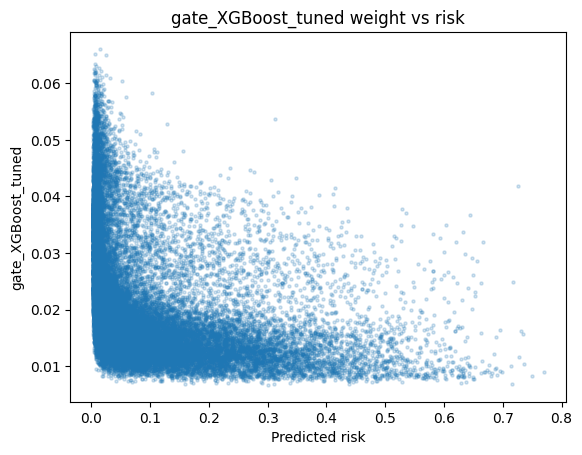

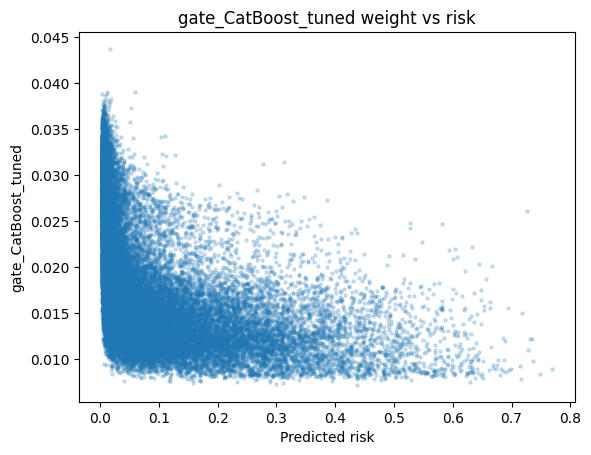

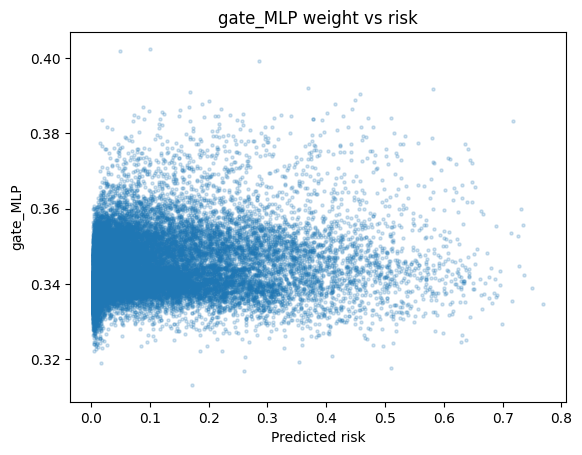

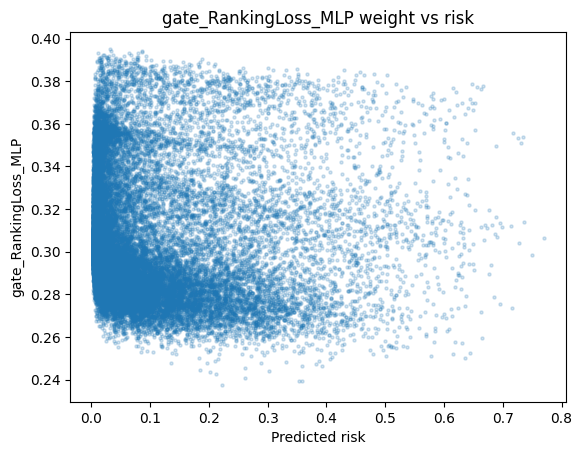

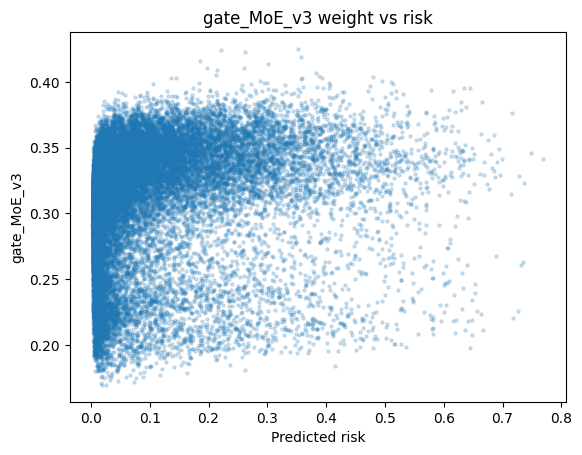

In [32]:
import matplotlib.pyplot as plt

for col in gate_cols:

    plt.figure()

    plt.scatter(
        gate_df["risk"],
        gate_df[col],
        alpha=0.2,
        s=5
    )

    plt.xlabel("Predicted risk")
    plt.ylabel(col)
    plt.title(f"{col} weight vs risk")

    plt.show()


SHAP analysis for HybridMoE gate
Number of experts: 5


PermutationExplainer explainer: 1001it [00:18, 30.94it/s]                         


Experts:
0 XGBoost_tuned
1 CatBoost_tuned
2 MLP
3 RankingLoss_MLP
4 MoE_v3

Top features driving gate toward XGBoost_tuned:
          feature  mean_abs_shap         expert
0     AgeCategory       0.005244  XGBoost_tuned
1    MentalHealth       0.004108  XGBoost_tuned
2  PhysicalHealth       0.002075  XGBoost_tuned
3             BMI       0.000688  XGBoost_tuned
4       SleepTime       0.000585  XGBoost_tuned
5        Diabetic       0.000403  XGBoost_tuned
6      SkinCancer       0.000373  XGBoost_tuned
7     Race__Black       0.000273  XGBoost_tuned
8     Race__White       0.000260  XGBoost_tuned
9       GenHealth       0.000215  XGBoost_tuned

Top features driving gate toward CatBoost_tuned:
           feature  mean_abs_shap          expert
0      AgeCategory       0.004023  CatBoost_tuned
1     MentalHealth       0.001805  CatBoost_tuned
2   PhysicalHealth       0.001675  CatBoost_tuned
3              BMI       0.000626  CatBoost_tuned
4        SleepTime       0.000458  CatBoost_tune

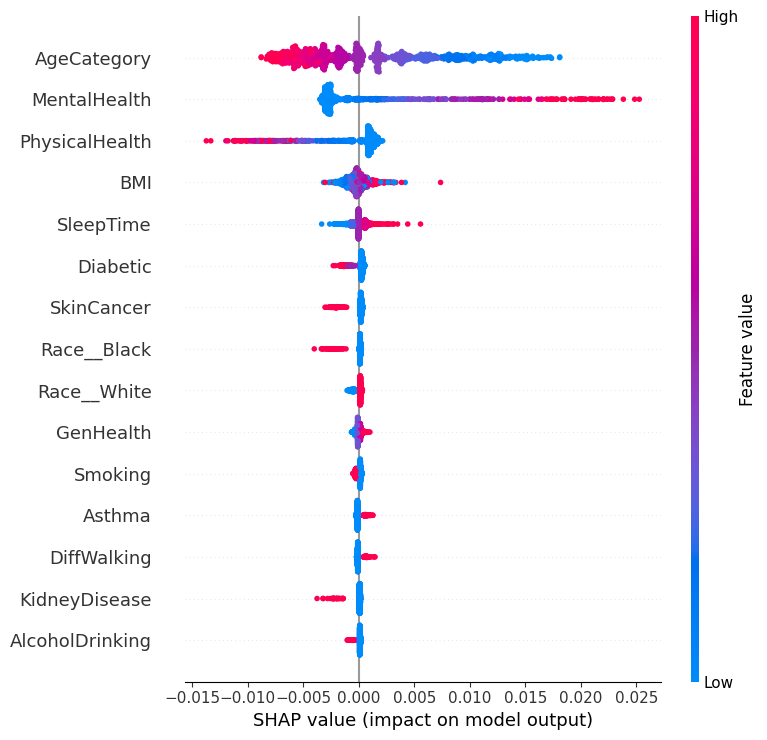

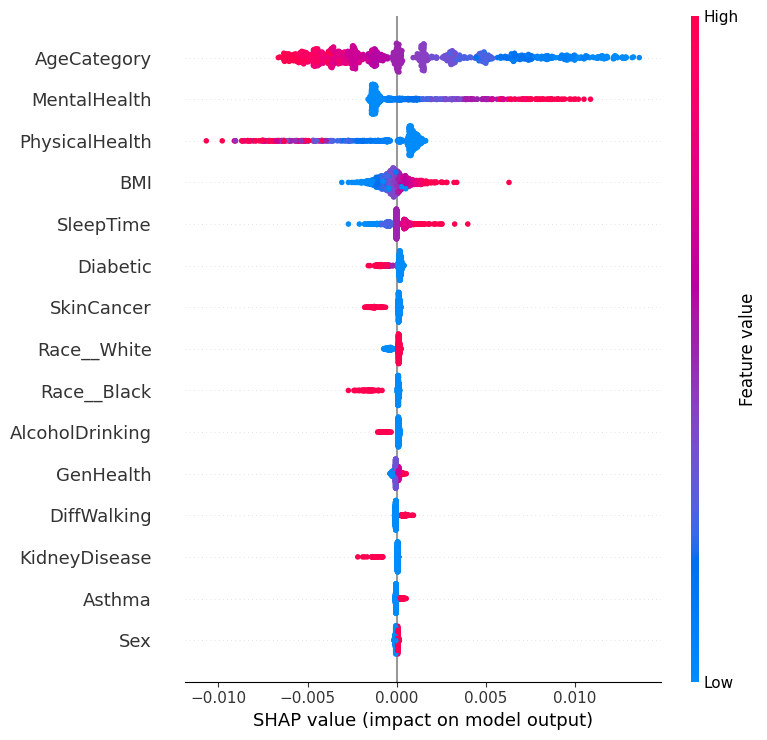

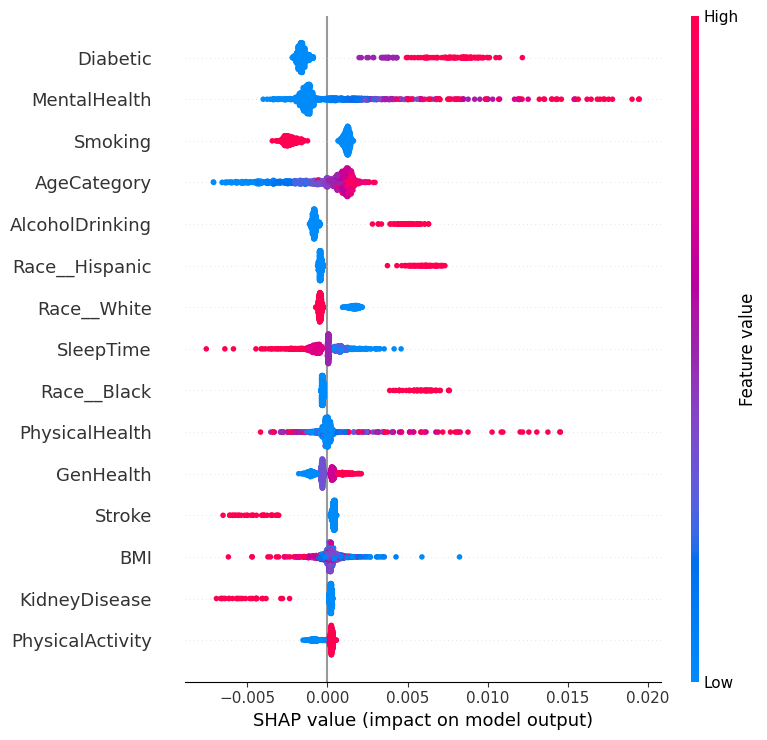

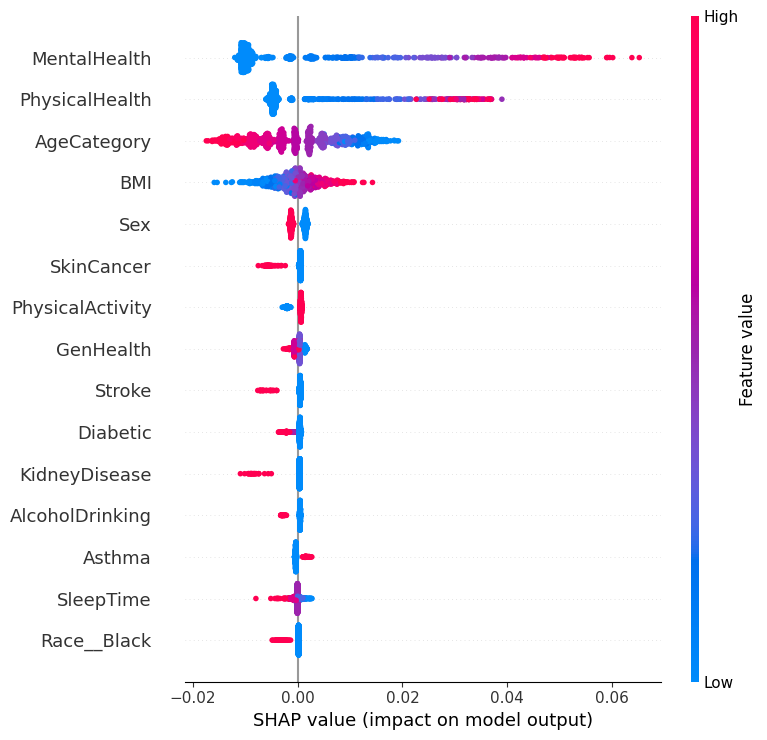

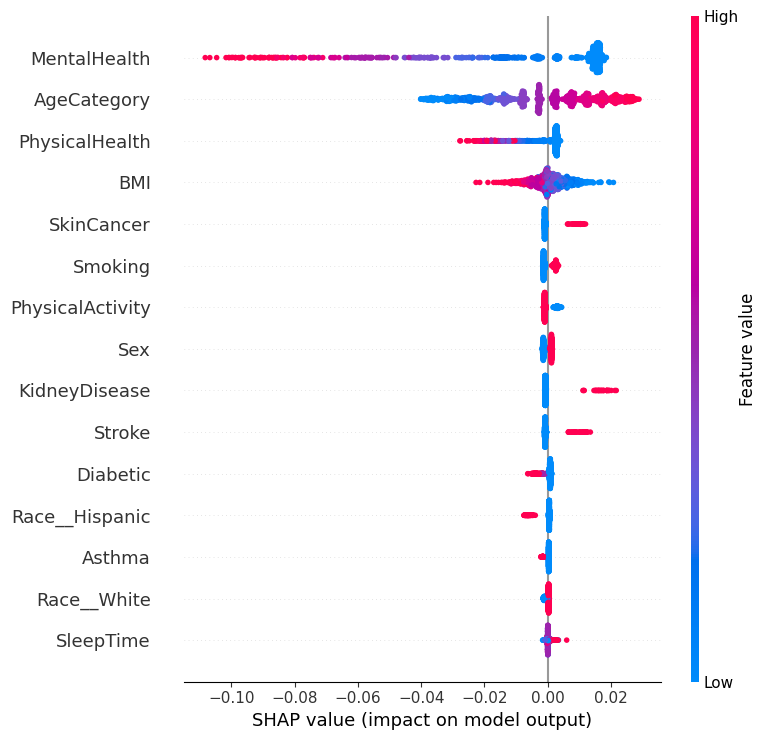

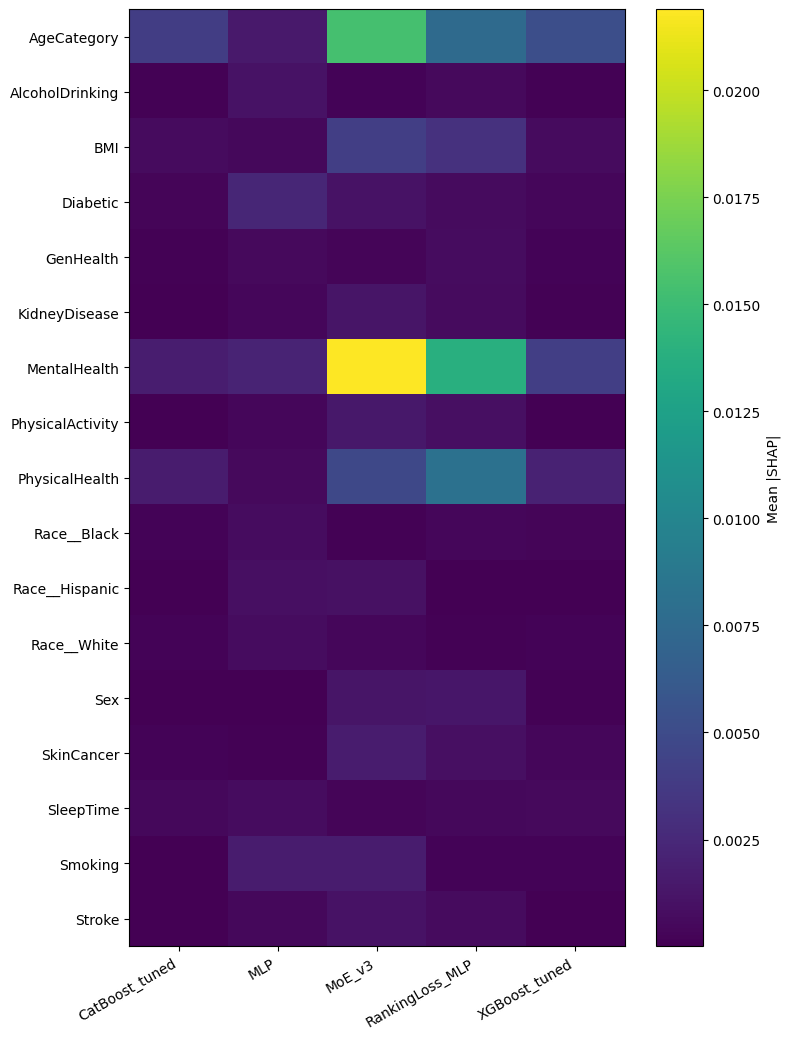


Gate SHAP analysis complete.


In [33]:
# ============================================================
# Analysis — SHAP for HybridMoE gate
# Purpose:
#   Explain which input features drive the gate toward
#   different experts.
#
# Output:
#   - global SHAP importance for each expert gate
#   - summary plots
#   - compact csv tables
# ============================================================

print("\n==============================")
print("SHAP analysis for HybridMoE gate")
print("==============================")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "hybrid_moe",
    "Xcal_ml",
    "TAB_DIR",
    "FIG_DIR",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for gate SHAP analysis: {missing_vars}")

# ------------------------------------------------------------
# Prepare sample data
# ------------------------------------------------------------
# SHAP on full calibration may be too heavy, so use a subset
N_BG = 256
N_EXPLAIN = 1000

X_cal_shap = Xcal_ml.copy()

if len(X_cal_shap) > N_BG:
    bg_idx = np.random.RandomState(SEED).choice(len(X_cal_shap), size=N_BG, replace=False)
    X_bg = X_cal_shap.iloc[bg_idx].copy()
else:
    X_bg = X_cal_shap.copy()

if len(X_cal_shap) > N_EXPLAIN:
    ex_idx = np.random.RandomState(SEED + 1).choice(len(X_cal_shap), size=N_EXPLAIN, replace=False)
    X_explain = X_cal_shap.iloc[ex_idx].copy()
else:
    X_explain = X_cal_shap.copy()

feature_names = list(X_cal_shap.columns)

# ------------------------------------------------------------
# Wrapper for gate outputs
# ------------------------------------------------------------
hybrid_moe.eval()
device = next(hybrid_moe.parameters()).device

def gate_predict_numpy(X_np):
    """
    Return gate weights only.
    Shape: [N, n_experts]
    """
    with torch.no_grad():
        X_t = torch.tensor(X_np, dtype=torch.float32, device=device)
        gate_w = hybrid_moe.gate(X_t)
        return gate_w.detach().cpu().numpy()

X_bg_np = X_bg.values.astype(np.float32)
X_explain_np = X_explain.values.astype(np.float32)

gate_out_bg = gate_predict_numpy(X_bg_np)
n_experts = gate_out_bg.shape[1]

print("Number of experts:", n_experts)

# ------------------------------------------------------------
# SHAP KernelExplainer / Explainer
# ------------------------------------------------------------
# For small neural gate, shap.Explainer usually works well.
explainer = shap.Explainer(
    gate_predict_numpy,
    X_bg_np,
    feature_names=feature_names,
)

shap_values = explainer(X_explain_np)

# ------------------------------------------------------------
# Expert names from earlier module
# ------------------------------------------------------------
# fallback names if not present
if "expert_names" not in globals():
    expert_names = [f"Expert_{i}" for i in range(n_experts)]

print("Experts:")
for i, name in enumerate(expert_names):
    print(i, name)

# ------------------------------------------------------------
# Save global importance tables for each expert
# ------------------------------------------------------------
global_tables = []

for expert_idx, expert_name in enumerate(expert_names):
    # shap_values.values shape expected: [N, D, E]
    sv = shap_values.values[:, :, expert_idx]
    mean_abs = np.abs(sv).mean(axis=0)

    df_imp = pd.DataFrame({
        "feature": feature_names,
        "mean_abs_shap": mean_abs,
        "expert": expert_name,
    }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

    df_imp.to_csv(
        TAB_DIR / f"hybrid_moe_gate_shap_{expert_name}_global.csv",
        index=False
    )

    global_tables.append(df_imp)

    print(f"\nTop features driving gate toward {expert_name}:")
    print(df_imp.head(10))

# combined table
global_all_df = pd.concat(global_tables, axis=0, ignore_index=True)
global_all_df.to_csv(TAB_DIR / "hybrid_moe_gate_shap_global_all.csv", index=False)

# ------------------------------------------------------------
# Summary plots for each expert
# ------------------------------------------------------------
for expert_idx, expert_name in enumerate(expert_names):
    plt.figure()
    shap.summary_plot(
        shap_values.values[:, :, expert_idx],
        X_explain,
        show=False,
        max_display=15
    )
    plt.tight_layout()
    save_figure_multi(FIG_DIR / f"hybrid_moe_gate_shap_summary_{expert_name}")
    plt.show()

# ------------------------------------------------------------
# Compact heatmap of top features across experts
# ------------------------------------------------------------
top_k = 10
top_features = (
    global_all_df.sort_values("mean_abs_shap", ascending=False)
    .groupby("expert")
    .head(top_k)["feature"]
    .unique()
    .tolist()
)

heat_rows = []
for expert_name in expert_names:
    tmp = global_all_df[global_all_df["expert"] == expert_name].copy()
    for feat in top_features:
        val = tmp.loc[tmp["feature"] == feat, "mean_abs_shap"]
        heat_rows.append({
            "expert": expert_name,
            "feature": feat,
            "mean_abs_shap": float(val.iloc[0]) if len(val) > 0 else 0.0
        })

heat_df = pd.DataFrame(heat_rows)
heat_pivot = heat_df.pivot(index="feature", columns="expert", values="mean_abs_shap").fillna(0.0)
heat_pivot.to_csv(TAB_DIR / "hybrid_moe_gate_shap_heatmap_table.csv")

plt.figure(figsize=(1.6 * max(4, heat_pivot.shape[1]), 0.5 * max(8, heat_pivot.shape[0]) + 2))
im = plt.imshow(heat_pivot.values, aspect="auto")
plt.xticks(range(heat_pivot.shape[1]), heat_pivot.columns, rotation=30, ha="right")
plt.yticks(range(heat_pivot.shape[0]), heat_pivot.index)
cbar = plt.colorbar(im)
cbar.set_label("Mean |SHAP|")
plt.tight_layout()
save_figure_multi(FIG_DIR / "hybrid_moe_gate_shap_heatmap")
plt.show()

print("\nGate SHAP analysis complete.")